### Finding Log.txt Files

In [282]:
pip install pandas

Note: you may need to restart the kernel to use updated packages.


In [1]:
# Cell 0 — Imports
from __future__ import annotations

import os
import re
import json
from pathlib import Path
from typing import Any, Dict, Optional, Tuple, List

import pandas as pd


In [2]:
# Cell 1 — Configure paths (notebook sits next to save/ and save_grouped/)

#SAVE_DIRS = [ROOT / "Prune_U-Net/save", ROOT / "Prune_U-Net/save_grouped"]

ROOT = Path(".").resolve()
SAVE_DIRS = [ROOT / "../save_mri/global", ROOT / "../save_mri/decoder", ROOT / "../save_mri/FLOPs_based" ]

for d in SAVE_DIRS:
    print("Exists:", d, "->", d.exists())


Exists: /home/jovyan/pruning-datavol-1/Prune_U-Net/analysis/../save_mri/global -> True
Exists: /home/jovyan/pruning-datavol-1/Prune_U-Net/analysis/../save_mri/decoder -> True
Exists: /home/jovyan/pruning-datavol-1/Prune_U-Net/analysis/../save_mri/FLOPs_based -> True


In [3]:
# Cell 2 — Find all log.txt files
def find_logs(save_dirs: List[Path]) -> List[Path]:
    logs: List[Path] = []
    for base in save_dirs:
        if not base.exists():
            continue
        logs.extend(base.rglob("log.txt"))
    # deterministic order
    logs = sorted(set(logs), key=lambda p: str(p).lower())
    return logs

log_paths = find_logs(SAVE_DIRS)
print(f"Found {len(log_paths)} log.txt files")
log_paths[:5]


Found 67 log.txt files


[PosixPath('/home/jovyan/pruning-datavol-1/Prune_U-Net/analysis/../save_mri/decoder/test/decoder-01/log.txt'),
 PosixPath('/home/jovyan/pruning-datavol-1/Prune_U-Net/analysis/../save_mri/decoder/test/decoder-02/log.txt'),
 PosixPath('/home/jovyan/pruning-datavol-1/Prune_U-Net/analysis/../save_mri/decoder/test/decoder-03/log.txt'),
 PosixPath('/home/jovyan/pruning-datavol-1/Prune_U-Net/analysis/../save_mri/decoder/test/decoder-04/log.txt'),
 PosixPath('/home/jovyan/pruning-datavol-1/Prune_U-Net/analysis/../save_mri/decoder/test/decoder-05/log.txt')]

### Helpers

In [12]:
import os
import re
import json
from pathlib import Path
import pandas as pd
import numpy as np

# ----------------------------
# Small parsing utilities
# ----------------------------

PARTS = ["inc", "down1", "down2", "down3", "down4", "up1", "up2", "up3", "up4", "outc", "other"]

def _to_int_commas(x: str):
    if x is None:
        return np.nan
    x = x.strip().replace(",", "")
    return int(x) if x.isdigit() or (x and x[0] == "-" and x[1:].isdigit()) else np.nan

def _to_float(x: str):
    try:
        return float(x)
    except Exception:
        return np.nan

def _parse_g_token(tok: str):
    # "1.906G" -> 1.906
    if tok is None:
        return np.nan
    tok = tok.strip()
    m = re.match(r"^([+-]?\d+(?:\.\d+)?)G$", tok)
    return float(m.group(1)) if m else np.nan

def _parse_pct_token(tok: str):
    # "98.26%" or "nan%"
    if tok is None:
        return np.nan
    tok = tok.strip().replace("%", "")
    if tok.lower() == "nan":
        return np.nan
    return _to_float(tok)

def _extract_args_block(text: str):
    """
    Extracts the JSON dict after 'Args: {' ... '}'.
    Uses brace counting so it works even if the args span many lines.
    """
    anchor = "Args:"
    i = text.find(anchor)
    if i < 0:
        return {}
    j = text.find("{", i)
    if j < 0:
        return {}
    depth = 0
    end = None
    for k in range(j, len(text)):
        if text[k] == "{":
            depth += 1
        elif text[k] == "}":
            depth -= 1
            if depth == 0:
                end = k + 1
                break
    if end is None:
        return {}
    blob = text[j:end]
    try:
        return json.loads(blob)
    except Exception:
        # If the JSON has trailing commas or minor issues, fall back to a safer eval-like parsing
        return {}

def _infer_experiment_type(args: dict):
    # global
    scope = (args.get("scope") or "").lower()
    if scope == "custom_seq":
        return "flops_based"
    if scope == "params_based":
        return "params_based"
    if scope == "balanced":
        return "balanced"
    if scope == "global":
        return "global"
    if scope in {"grouped", "grouped_fixed"}:
        # let budget structure refine it
        pass
    # grouped flavors
    pe = args.get("prune_encoder", 0) or 0
    pb = args.get("prune_bottleneck", 0) or 0
    pd = args.get("prune_decoder", 0) or 0
    pdown = args.get("prune_down_total", -1)
    pdown = pdown if pdown is not None else -1

    # pooled down mode
    if pdown is not None and pdown >= 0:
        if pd > 0 and pdown > 0:
            return "pooled_down+decoder"
        if pdown > 0:
            return "pooled_down"
    # separate budgets
    nz = sum(int(x > 0) for x in [pe, pb, pd])
    if nz == 1 and pe > 0:
        return "enc_only"
    if nz == 1 and pb > 0:
        return "bottleneck_only"
    if nz == 1 and pd > 0:
        return "dec_only"
    if nz >= 2:
        return "mixed_grouped"
    return "grouped_unknown"

def _infer_requested_budget(args: dict):
    # Prefer explicit effective total if present (your grouped logs have it)
    if "prune_total_effective" in args and args["prune_total_effective"] is not None:
        return int(args["prune_total_effective"])
    if "prune_channels" in args and args["prune_channels"] is not None:
        return int(args["prune_channels"])

    # Grouped fallback
    pe = int(args.get("prune_encoder", 0) or 0)
    pb = int(args.get("prune_bottleneck", 0) or 0)
    pd = int(args.get("prune_decoder", 0) or 0)
    pdown = args.get("prune_down_total", -1)
    pdown = int(pdown) if pdown is not None else -1
    if pdown >= 0:
        return pdown + pd
    return pe + pb + pd

def _extract_removed_channels_reported(text: str):
    # Old format: removed 1100 channels
    m = re.search(r"Pruning complete:\s*removed\s+(\d+)\s+channels", text)
    if m:
        return int(m.group(1))

    # New format: requested removal=208
    m = re.search(r"Pruning complete:\s*requested removal=(\d+)", text)
    if m:
        return int(m.group(1))

    # Group pruning variant
    m = re.search(r"Group pruning complete:\s*removed\s+(\d+)\s+channels", text)
    if m:
        return int(m.group(1))

    return np.nan


def _extract_final_summary_metrics(text: str):
    """
    Parse FINAL SUMMARY table rows:
      Dice | baseline | pruned | delta | ratio%
      Params | baseline | pruned | delta... | ratio%
      Size (MB) | ...
      FLOPs | 1.906G | 1.826G | ... | 95.79%
    Returns a dict with both baseline and pruned numeric values.
    """
    out = {}

    # Dice
    m = re.search(r"^\[.*?\]\s*Dice\s*\|\s*([0-9.]+)\s*\|\s*([0-9.]+)\s*\|\s*([+-]?[0-9.]+)\s*\|\s*([0-9.]+)%\s*$",
                  text, flags=re.MULTILINE)
    if m:
        out["dice_baseline"] = _to_float(m.group(1))
        out["dice_pruned"] = _to_float(m.group(2))
        out["dice_delta"] = _to_float(m.group(3))
        out["dice_ratio_pct"] = _to_float(m.group(4))

    # Params
    m = re.search(r"^\[.*?\]\s*Params\s*\|\s*([\d,]+)\s*\|\s*([\d,]+)\s*\|\s*.*?\|\s*([0-9.]+)%\s*$",
                  text, flags=re.MULTILINE)
    if m:
        out["params_baseline"] = _to_int_commas(m.group(1))
        out["params_pruned"] = _to_int_commas(m.group(2))
        out["params_keep_pct"] = _to_float(m.group(3))
        out["params_ratio"] = out["params_pruned"] / out["params_baseline"] if out["params_baseline"] else np.nan
        out["params_reduction_pct"] = 100.0 * (1 - out["params_ratio"]) if pd.notna(out["params_ratio"]) else np.nan

    # Size
    m = re.search(r"^\[.*?\]\s*Size\s*\(MB\)\s*\|\s*([0-9.]+)\s*\|\s*([0-9.]+)\s*\|\s*.*?\|\s*([0-9.]+)%\s*$",
                  text, flags=re.MULTILINE)
    if m:
        out["size_mb_baseline"] = _to_float(m.group(1))
        out["size_mb_pruned"] = _to_float(m.group(2))
        out["size_keep_pct"] = _to_float(m.group(3))
        out["size_ratio"] = out["size_mb_pruned"] / out["size_mb_baseline"] if out["size_mb_baseline"] else np.nan
        out["size_reduction_pct"] = 100.0 * (1 - out["size_ratio"]) if pd.notna(out["size_ratio"]) else np.nan

    # FLOPs
    m = re.search(r"^\[.*?\]\s*FLOPs\s*\|\s*([0-9.]+G)\s*\|\s*([0-9.]+G)\s*\|\s*.*?\|\s*([0-9.]+)%\s*$",
                  text, flags=re.MULTILINE)
    if m:
        out["flops_g_baseline"] = _parse_g_token(m.group(1))
        out["flops_g_pruned"] = _parse_g_token(m.group(2))
        out["flops_keep_pct"] = _to_float(m.group(3))
        out["flops_ratio"] = out["flops_g_pruned"] / out["flops_g_baseline"] if out["flops_g_baseline"] else np.nan
        out["flops_reduction_pct"] = 100.0 * (1 - out["flops_ratio"]) if pd.notna(out["flops_ratio"]) else np.nan

    return out

def _extract_per_part_table(text: str, which: str):
    """
    which in {"flops", "params"}.
    Parses PER-PART table into fixed columns:
      part_{which}_baseline, part_{which}_pruned, part_{which}_delta, part_{which}_ratio_pct

    FLOPs tokens are like 0.247G, 0.000G; Params are 38,848 etc.
    """
    assert which in {"flops", "params"}
    section_title = "PER-PART FLOPs" if which == "flops" else "PER-PART Params"

    # Grab only the part of the log starting at that section; stop at the next big separator of a different section.
    i = text.find(section_title)
    if i < 0:
        return {}

    # Take a reasonably bounded window after the section
    chunk = text[i:i+8000]

    out = {}
    for part in PARTS:
        # Typical row:
        # [..] down1 | 0.177G | 0.171G | -0.006G | 96.88%
        # [..] down1 | 221,696 | 203,616 | -18080 | 91.84%
        if which == "flops":
            row_re = rf"^\[.*?\]\s*{re.escape(part)}\s*\|\s*([0-9.]+G)\s*\|\s*([0-9.]+G)\s*\|\s*([+-]?[0-9.]+G)\s*\|\s*([0-9.]+%|nan%)\s*$"
            m = re.search(row_re, chunk, flags=re.MULTILINE)
            if m:
                out[f"{part}_flops_g_baseline"] = _parse_g_token(m.group(1))
                out[f"{part}_flops_g_pruned"]   = _parse_g_token(m.group(2))
                out[f"{part}_flops_g_delta"]    = _parse_g_token(m.group(3))
                out[f"{part}_flops_ratio_pct"]  = _parse_pct_token(m.group(4))
        else:
            row_re = rf"^\[.*?\]\s*{re.escape(part)}\s*\|\s*([\d,]+)\s*\|\s*([\d,]+)\s*\|\s*([+-]?\d+)\s*\|\s*([0-9.]+%|nan%)\s*$"
            m = re.search(row_re, chunk, flags=re.MULTILINE)
            if m:
                out[f"{part}_params_baseline"]  = _to_int_commas(m.group(1))
                out[f"{part}_params_pruned"]    = _to_int_commas(m.group(2))
                out[f"{part}_params_delta"]     = _to_int_commas(m.group(3))
                out[f"{part}_params_ratio_pct"] = _parse_pct_token(m.group(4))

    return out

def _extract_aggregated_groups(text: str):
    i = text.find("AGGREGATED GROUPS")
    if i < 0:
        return {}

    chunk = text[i:i+4000]

    groups = ["ENCODER", "BOTTLENECK", "DECODER"]
    out = {}

    for g in groups:
        # Match table row
        # ENCODER (...) | 4687296 | 4687296 | 0.00% | 0.022 | 0.022 | 0.00%
        pattern = (
            rf"{g}.*?\|\s*([\d,]+)\s*\|\s*([\d,]+)\s*\|\s*([0-9.]+)%"
            rf"\s*\|\s*([0-9.]+)\s*\|\s*([0-9.]+)\s*\|\s*([0-9.]+)%"
        )

        m = re.search(pattern, chunk)
        if m:
            gname = g.lower()

            out[f"{gname}_params_baseline"] = _to_int_commas(m.group(1))
            out[f"{gname}_params_pruned"] = _to_int_commas(m.group(2))
            out[f"{gname}_params_reduce_pct"] = _to_float(m.group(3))

            out[f"{gname}_flops_g_baseline"] = _to_float(m.group(4))
            out[f"{gname}_flops_g_pruned"] = _to_float(m.group(5))
            out[f"{gname}_flops_reduce_pct"] = _to_float(m.group(6))

    return out


def parse_single_log(log_path: str):
    text = Path(log_path).read_text(encoding="utf-8", errors="ignore")

    args = _extract_args_block(text)
    # Flatten nested "budget" dict if present
    if "budget" in args and isinstance(args["budget"], dict):
        for k, v in args["budget"].items():
            if k not in args:
                args[k] = v
    
    exp_type = _infer_experiment_type(args)
    requested_budget = _infer_requested_budget(args)
    removed_reported = _extract_removed_channels_reported(text)

    # This is now the authoritative source for baseline/pruned metrics
    summary = _extract_final_summary_metrics(text)

    per_part_flops = _extract_per_part_table(text, which="flops")
    per_part_params = _extract_per_part_table(text, which="params")
    aggs = _extract_aggregated_groups(text)

    row = {
        "log_path": str(log_path),
        "experiment_type": exp_type,
        "requested_budget_channels": requested_budget,
        "removed_channels_reported": removed_reported,
    }

    # Model name
    if exp_type == "global":
        row["model_name"] = f"global_b{requested_budget}"
    elif exp_type == "enc_only":
        row["model_name"] = f"enc_only_e{int(args.get('prune_encoder', 0) or 0)}"
    elif exp_type == "bottleneck_only":
        row["model_name"] = f"bottleneck_only_b{int(args.get('prune_bottleneck', 0) or 0)}"
    elif exp_type == "dec_only":
        row["model_name"] = f"dec_only_d{int(args.get('prune_decoder', 0) or 0)}"
    elif exp_type == "pooled_down+decoder":
        row["model_name"] = f"pooled_down{int(args.get('prune_down_total', 0) or 0)}_dec{int(args.get('prune_decoder', 0) or 0)}"
    elif exp_type == "mixed_grouped":
        row["model_name"] = f"mixed_e{int(args.get('prune_encoder',0) or 0)}_b{int(args.get('prune_bottleneck',0) or 0)}_d{int(args.get('prune_decoder',0) or 0)}"
    else:
        row["model_name"] = f"{exp_type}_b{requested_budget}"

    # Add args (prefixed)
    for k, v in args.items():
        row[f"arg_{k}"] = v

    # Add summary metrics (baseline + pruned)
    row.update(summary)

    # Add per-part and aggregated
    row.update(per_part_flops)
    row.update(per_part_params)
    row.update(aggs)

    return row


### Execution

In [13]:
# Cell — Scan logs and build baseline + runs tables
rows = []
bad = []
for lp in log_paths:
    try:
        rows.append(parse_single_log(lp))
    except Exception as e:
        bad.append((lp, repr(e)))

if bad:
    print("Failed logs:", len(bad))
    print("First 5 failures:")
    for lp, err in bad[:5]:
        print("  -", lp, err)

df_all = pd.DataFrame(rows)

# ----------------------------
# Build a SINGLE baseline row
# ----------------------------
# Baseline should be identical across runs; we derive it from the FINAL SUMMARY baseline columns
# and the per-part baseline columns from any log that has them.

# pick candidates that have dice_baseline and params_baseline
cand = df_all[df_all["dice_baseline"].notna() & df_all["params_baseline"].notna()].copy()
if len(cand) == 0:
    raise RuntimeError("No logs contained FINAL SUMMARY baseline metrics (dice_baseline/params_baseline).")

# Use median to be robust; then verify max deviation
baseline = {}
for col in ["dice_baseline", "params_baseline", "size_mb_baseline", "flops_g_baseline"]:
    if col in cand.columns:
        baseline[col] = cand[col].median()

# Per-part baseline columns: take from the first log that contains each column
baseline_source_row = cand.iloc[0].to_dict()
for part in PARTS:
    # FLOPs baseline per-part
    c = f"{part}_flops_g_baseline"
    if c in df_all.columns and pd.notna(baseline_source_row.get(c, np.nan)):
        baseline[c] = baseline_source_row[c]
    # Params baseline per-part
    c = f"{part}_params_baseline"
    if c in df_all.columns and pd.notna(baseline_source_row.get(c, np.nan)):
        baseline[c] = baseline_source_row[c]

# Aggregated groups baseline (params + flops_abs)
for g in ["encoder", "bottleneck", "decoder"]:
    for c in [f"{g}_params_baseline", f"{g}_flops_abs_baseline"]:
        if c in df_all.columns and pd.notna(baseline_source_row.get(c, np.nan)):
            baseline[c] = baseline_source_row[c]

df_baseline = pd.DataFrame([{
    "model_name": "BASELINE",
    "experiment_type": "baseline",
    "log_path": "",  # baseline is not a log; it is inferred from logs
    **baseline
}])

# ----------------------------
# Build df_runs: one row per pruned experiment (no baseline redundancy)
# ----------------------------
df_runs = df_all.copy()

# Ensure baseline metrics are filled (never NaN) using the baseline row values
for k, v in baseline.items():
    if k in df_runs.columns and df_runs[k].isna().any():
        df_runs[k] = df_runs[k].fillna(v)

# Now compute consistent deltas/ratios against the baseline row (even if the log didn't print % fields)
df_runs["dice_drop"] = df_runs["dice_baseline"] - df_runs["dice_pruned"]
df_runs["dice_keep"] = df_runs["dice_pruned"] / df_runs["dice_baseline"]

df_runs["params_ratio"] = df_runs["params_pruned"] / df_runs["params_baseline"]
df_runs["params_reduction_pct"] = 100 * (1 - df_runs["params_ratio"])

df_runs["size_ratio"] = df_runs["size_mb_pruned"] / df_runs["size_mb_baseline"]
df_runs["size_reduction_pct"] = 100 * (1 - df_runs["size_ratio"])

df_runs["flops_ratio"] = df_runs["flops_g_pruned"] / df_runs["flops_g_baseline"]
df_runs["flops_reduction_pct"] = 100 * (1 - df_runs["flops_ratio"])

# Per-part ratios/deltas re-derived (so you can rely on them, even if "nan%" printed)
for part in PARTS:
    # FLOPs per-part
    b = f"{part}_flops_g_baseline"
    p = f"{part}_flops_g_pruned"
    if b in df_runs.columns and p in df_runs.columns:
        df_runs[f"{part}_flops_g_delta_recalc"] = df_runs[p] - df_runs[b]
        df_runs[f"{part}_flops_ratio_recalc"] = df_runs[p] / df_runs[b].replace({0: np.nan})
    # Params per-part
    b = f"{part}_params_baseline"
    p = f"{part}_params_pruned"
    if b in df_runs.columns and p in df_runs.columns:
        df_runs[f"{part}_params_delta_recalc"] = df_runs[p] - df_runs[b]
        df_runs[f"{part}_params_ratio_recalc"] = df_runs[p] / df_runs[b].replace({0: np.nan})

# Remove baseline columns from runs to reduce redundancy (keep only what’s needed)
# Keep baseline scalar columns if you prefer; otherwise you can drop them.
drop_baseline_cols = [c for c in df_runs.columns if c.endswith("_baseline") and c not in ["dice_baseline","params_baseline","size_mb_baseline","flops_g_baseline"]]
# The per-part baseline columns are the main redundancy:
drop_perpart_baseline = [c for c in df_runs.columns if c.endswith("_flops_g_baseline") or c.endswith("_params_baseline")]
# Aggregated baseline redundancy:
drop_agg_baseline = [c for c in df_runs.columns if c.endswith("_params_baseline") or c.endswith("_flops_abs_baseline")]

# Keep the 4 scalar baseline metrics because they are useful for sanity; if you want, drop them too.
keep_scalar_baseline = {"dice_baseline", "params_baseline", "size_mb_baseline", "flops_g_baseline"}
drop_cols = sorted(set(drop_perpart_baseline + drop_agg_baseline) - keep_scalar_baseline)

df_runs = df_runs.drop(columns=[c for c in drop_cols if c in df_runs.columns])

# Add a baseline_id to join later if needed
df_runs["baseline_id"] = 0
df_baseline["baseline_id"] = 0

print("df_baseline shape:", df_baseline.shape)
print("df_runs shape:", df_runs.shape)

display(df_baseline)
display(df_runs.head(60))


df_baseline shape: (1, 33)
df_runs shape: (67, 179)


/tmp/ipykernel_3459/4162676260.py:95: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_runs[f"{part}_params_delta_recalc"] = df_runs[p] - df_runs[b]
/tmp/ipykernel_3459/4162676260.py:96: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_runs[f"{part}_params_ratio_recalc"] = df_runs[p] / df_runs[b].replace({0: np.nan})
/tmp/ipykernel_3459/4162676260.py:89: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns a

,model_name,experiment_type,log_path,dice_baseline,params_baseline,size_mb_baseline,flops_g_baseline,inc_flops_g_baseline,inc_params_baseline,down1_flops_g_baseline,...,up4_flops_g_baseline,up4_params_baseline,outc_flops_g_baseline,outc_params_baseline,other_flops_g_baseline,other_params_baseline,encoder_params_baseline,bottleneck_params_baseline,decoder_params_baseline,baseline_id
0,BASELINE,baseline,,0.880062,31037698.0,118.484,0.076,0.01,38848.0,0.007,...,0.028,143680.0,0.0,130.0,0.0,0.0,4687296.0,14159872.0,12190530.0,0


,log_path,experiment_type,requested_budget_channels,removed_channels_reported,model_name,arg_name,arg_save_dir,arg_device,arg_data_root,arg_scale,...,up4_params_ratio_recalc,outc_flops_g_delta_recalc,outc_flops_ratio_recalc,outc_params_delta_recalc,outc_params_ratio_recalc,other_flops_g_delta_recalc,other_flops_ratio_recalc,other_params_delta_recalc,other_params_ratio_recalc,baseline_id
0,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,dec_only,200,208,dec_only_d200,decoder,save_mri/decoder/test/decoder-01,cuda,dataset_split,0.5,...,1.000000,0.0,NaN,0.0,1.000000,0.0,NaN,0.0,NaN,0
1,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,dec_only,300,304,dec_only_d300,decoder,save_mri/decoder/test/decoder-02,cuda,dataset_split,0.5,...,0.907127,0.0,NaN,-32.0,0.753846,0.0,NaN,0.0,NaN,0
2,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,dec_only,400,400,dec_only_d400,decoder,save_mri/decoder/test/decoder-03,cuda,dataset_split,0.5,...,0.907127,0.0,NaN,-32.0,0.753846,0.0,NaN,0.0,NaN,0
3,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,dec_only,500,512,dec_only_d500,decoder,save_mri/decoder/test/decoder-04,cuda,dataset_split,0.5,...,0.907127,0.0,NaN,-32.0,0.753846,0.0,NaN,0.0,NaN,0
4,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,dec_only,600,608,dec_only_d600,decoder,save_mri/decoder/test/decoder-05,cuda,dataset_split,0.5,...,0.907127,0.0,NaN,-32.0,0.753846,0.0,NaN,0.0,NaN,0
5,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,dec_only,700,704,dec_only_d700,decoder,save_mri/decoder/test/decoder-06,cuda,dataset_split,0.5,...,0.907127,0.0,NaN,-32.0,0.753846,0.0,NaN,0.0,NaN,0
6,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,dec_only,800,800,dec_only_d800,decoder,save_mri/decoder/test/decoder-07,cuda,dataset_split,0.5,...,0.702004,0.0,NaN,-32.0,0.753846,0.0,NaN,0.0,NaN,0
7,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,dec_only,900,912,dec_only_d900,decoder,save_mri/decoder/test/decoder-08,cuda,dataset_split,0.5,...,0.702004,0.0,NaN,-32.0,0.753846,0.0,NaN,0.0,NaN,0
8,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,dec_only,1000,1008,dec_only_d1000,decoder,save_mri/decoder/test/decoder-09,cuda,dataset_split,0.5,...,0.702004,0.0,NaN,-32.0,0.753846,0.0,NaN,0.0,NaN,0
9,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,dec_only,1100,1104,dec_only_d1100,decoder,save_mri/decoder/test/decoder-10,cuda,dataset_split,0.5,...,0.673497,0.0,NaN,-32.0,0.753846,0.0,NaN,0.0,NaN,0


In [14]:
# Cell — Integrity check for df_baseline + df_runs

def _missing_report(d: pd.DataFrame, name: str, key_cols):
    miss = d[key_cols].isna().sum().sort_values(ascending=False)
    miss_pct = (miss / len(d) * 100).round(2) if len(d) else miss * 0
    out = pd.DataFrame({"na": miss, "na_%": miss_pct})
    print(f"\n{name} — rows={len(d)}, cols={d.shape[1]}")
    display(out[out["na"] > 0])

# 1) Baseline must have no NaNs in the core baseline metrics
baseline_required = ["dice_baseline", "params_baseline", "size_mb_baseline", "flops_g_baseline"]
_missing_report(df_baseline, "df_baseline", baseline_required)

# 2) Runs must have no NaNs in core run metrics
runs_required = [
    "model_name", "experiment_type", "requested_budget_channels", "removed_channels_reported", "log_path",
    "dice_pruned", "params_pruned", "size_mb_pruned", "flops_g_pruned",
    "dice_drop", "params_reduction_pct", "size_reduction_pct", "flops_reduction_pct",
]
_missing_report(df_runs, "df_runs", [c for c in runs_required if c in df_runs.columns])

# 3) Sanity: metrics ranges
issues = []
def flag(mask, msg):
    n = int(mask.sum())
    if n > 0:
        issues.append((msg, n, df_runs.loc[mask, ["model_name","experiment_type","log_path"]].head(10)))

if "dice_pruned" in df_runs.columns:
    flag(df_runs["dice_pruned"].notna() & ((df_runs["dice_pruned"] < 0) | (df_runs["dice_pruned"] > 1)),
         "dice_pruned outside [0,1]")
if "flops_g_pruned" in df_runs.columns and "flops_g_baseline" in df_runs.columns:
    flag(df_runs["flops_g_pruned"] > df_runs["flops_g_baseline"] * 1.001,
         "flops_g_pruned > flops_g_baseline (unexpected)")
if "params_pruned" in df_runs.columns and "params_baseline" in df_runs.columns:
    flag(df_runs["params_pruned"] > df_runs["params_baseline"],
         "params_pruned > params_baseline (unexpected)")

print("\nSanity issues:")
if not issues:
    print("None")
else:
    for msg, n, sample in issues:
        print(f"- {msg}: {n} rows")
        display(sample)



df_baseline — rows=1, cols=33


,na,na_%



df_runs — rows=67, cols=179


,na,na_%
dice_drop,1,1.49
flops_g_pruned,1,1.49
size_mb_pruned,1,1.49
params_pruned,1,1.49
dice_pruned,1,1.49
size_reduction_pct,1,1.49
params_reduction_pct,1,1.49
flops_reduction_pct,1,1.49



Sanity issues:
None


### Visualisations

#### Global metrics

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Columns needed for "global metrics" plots across ALL experiments
REQ = [
    "model_name", "experiment_type", "log_path",
    "requested_budget_channels", "removed_channels_reported",
    "dice_pruned", "dice_baseline",
    "params_pruned", "params_baseline",
    "size_mb_pruned", "size_mb_baseline",
    "flops_g_pruned", "flops_g_baseline",
    "dice_drop", "dice_keep",
    "params_ratio", "params_reduction_pct",
    "size_ratio", "size_reduction_pct",
    "flops_ratio", "flops_reduction_pct",
]
REQ = [c for c in REQ if c in df_runs.columns]

gdf = df_runs[REQ].copy()

# numeric safety
NUMS = [
    "requested_budget_channels","removed_channels_reported",
    "dice_pruned","dice_baseline","dice_drop","dice_keep",
    "params_pruned","params_baseline","params_ratio","params_reduction_pct",
    "size_mb_pruned","size_mb_baseline","size_ratio","size_reduction_pct",
    "flops_g_pruned","flops_g_baseline","flops_ratio","flops_reduction_pct",
]
for c in NUMS:
    if c in gdf.columns:
        gdf[c] = pd.to_numeric(gdf[c], errors="coerce")

# choose x-axis (budget) column
if "removed_channels_reported" in gdf.columns and gdf["removed_channels_reported"].notna().any():
    gdf["budget_x"] = gdf["removed_channels_reported"]
else:
    gdf["budget_x"] = gdf["requested_budget_channels"]

# drop anything missing critical plot values
CRIT = ["experiment_type", "budget_x", "dice_pruned",
        "params_reduction_pct", "flops_reduction_pct", "size_reduction_pct"]
CRIT = [c for c in CRIT if c in gdf.columns]
gplot = gdf.dropna(subset=CRIT).copy()

print("gplot rows:", len(gplot), "/", len(gdf))
print("\nExperiment types:")
display(gplot["experiment_type"].value_counts())
display(gplot.head(30))


gplot rows: 66 / 67

Experiment types:


experiment_type
global         29
flops_based    19
dec_only       18
Name: count, dtype: int64

,model_name,experiment_type,log_path,requested_budget_channels,removed_channels_reported,dice_pruned,dice_baseline,params_pruned,params_baseline,size_mb_pruned,...,flops_g_baseline,dice_drop,dice_keep,params_ratio,params_reduction_pct,size_ratio,size_reduction_pct,flops_ratio,flops_reduction_pct,budget_x
0,dec_only_d200,dec_only,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,200,208,0.856334,0.880062,29522274.0,31037698.0,112.702,...,0.076,0.023728,0.973038,0.951175,4.882527,0.951200,4.879984,0.986842,1.315789,208
1,dec_only_d300,dec_only,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,300,304,0.860830,0.880062,28951938.0,31037698.0,110.526,...,0.076,0.019232,0.978147,0.932799,6.720086,0.932835,6.716519,0.986842,1.315789,304
2,dec_only_d400,dec_only,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,400,400,0.854474,0.880062,28109250.0,31037698.0,107.310,...,0.076,0.025588,0.970925,0.905649,9.435133,0.905692,9.430809,0.973684,2.631579,400
3,dec_only_d500,dec_only,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,500,512,0.863740,0.880062,27372258.0,31037698.0,104.498,...,0.076,0.016322,0.981454,0.881904,11.809639,0.881959,11.804125,0.973684,2.631579,512
4,dec_only_d600,dec_only,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,600,608,0.862386,0.880062,26711330.0,31037698.0,101.976,...,0.076,0.017676,0.979915,0.860609,13.939075,0.860673,13.932683,0.960526,3.947368,608
5,dec_only_d700,dec_only,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,700,704,0.851038,0.880062,26073442.0,31037698.0,99.542,...,0.076,0.029024,0.967021,0.840057,15.994279,0.840130,15.986969,0.960526,3.947368,704
6,dec_only_d800,dec_only,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,800,800,0.857283,0.880062,25701282.0,31037698.0,98.122,...,0.076,0.022779,0.974117,0.828067,17.193337,0.828146,17.185443,0.921053,7.894737,800
7,dec_only_d900,dec_only,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,900,912,0.841585,0.880062,25008066.0,31037698.0,95.476,...,0.076,0.038477,0.956279,0.805732,19.426802,0.805813,19.418656,0.921053,7.894737,912
8,dec_only_d1000,dec_only,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,1000,1008,0.824502,0.880062,24565762.0,31037698.0,93.788,...,0.076,0.055560,0.936868,0.791481,20.851856,0.791567,20.843321,0.921053,7.894737,1008
9,dec_only_d1100,dec_only,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,1100,1104,0.838935,0.880062,24082754.0,31037698.0,91.945,...,0.076,0.041127,0.953268,0.775919,22.408054,0.776012,22.398805,0.921053,7.894737,1104


In [16]:
summary = (
    gplot.groupby("experiment_type")
    .agg(
        n=("model_name","count"),
        budget_min=("budget_x","min"),
        budget_max=("budget_x","max"),
        dice_min=("dice_pruned","min"),
        dice_max=("dice_pruned","max"),
        dice_mean=("dice_pruned","mean"),
        drop_max=("dice_drop","max"),
        params_red_max=("params_reduction_pct","max"),
        flops_red_max=("flops_reduction_pct","max"),
        size_red_max=("size_reduction_pct","max"),
    )
    .sort_values("n", ascending=False)
)

display(summary)

# Show top-3 (best dice) per type
top3 = (
    gplot.sort_values(["experiment_type","dice_pruned"], ascending=[True, False])
    .groupby("experiment_type")
    .head(3)[["experiment_type","model_name","budget_x","dice_pruned","dice_drop",
              "params_reduction_pct","flops_reduction_pct","size_reduction_pct","log_path"]]
)
display(top3.reset_index(drop=True))


,n,budget_min,budget_max,dice_min,dice_max,dice_mean,drop_max,params_red_max,flops_red_max,size_red_max
experiment_type,,,,,,,,,,
global,29,208,3904,0.811516,0.877079,0.845592,0.068546,90.325204,32.894737,90.285608
flops_based,19,154,1620,0.655367,0.859982,0.803907,0.224695,45.311801,28.947368,45.294723
dec_only,18,208,1904,0.655367,0.863740,0.811178,0.224695,31.502852,18.421053,31.491172


,experiment_type,model_name,budget_x,dice_pruned,dice_drop,params_reduction_pct,flops_reduction_pct,size_reduction_pct,log_path
0,dec_only,dec_only_d500,512,0.863740,0.016322,11.809639,2.631579,11.804125,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
1,dec_only,dec_only_d600,608,0.862386,0.017676,13.939075,3.947368,13.932683,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
2,dec_only,dec_only_d300,304,0.860830,0.019232,6.720086,1.315789,6.716519,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
3,flops_based,flops_based_b0,236,0.859982,0.020080,11.123550,3.947368,11.118801,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
4,flops_based,flops_based_b0,556,0.858468,0.021594,22.964303,13.157895,22.954998,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
5,flops_based,flops_based_b0,478,0.855653,0.024409,20.487837,9.210526,20.478714,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
6,global,global_b0,304,0.877079,0.002983,10.749973,0.000000,10.744067,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
7,global,global_b0,208,0.875766,0.004296,7.592831,0.000000,7.588366,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
8,global,global_b0,1008,0.866010,0.014052,32.462614,2.631579,32.445731,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...


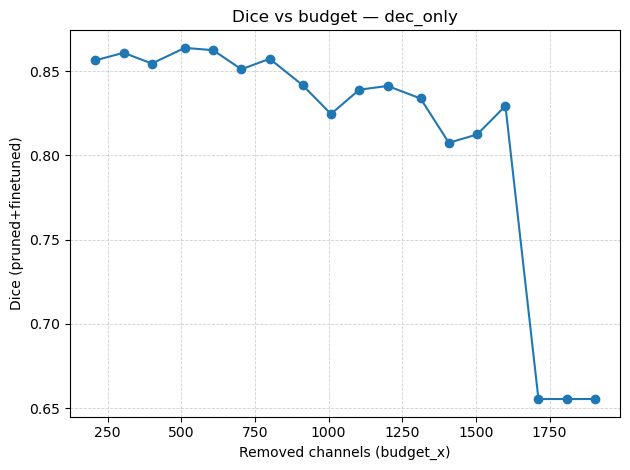

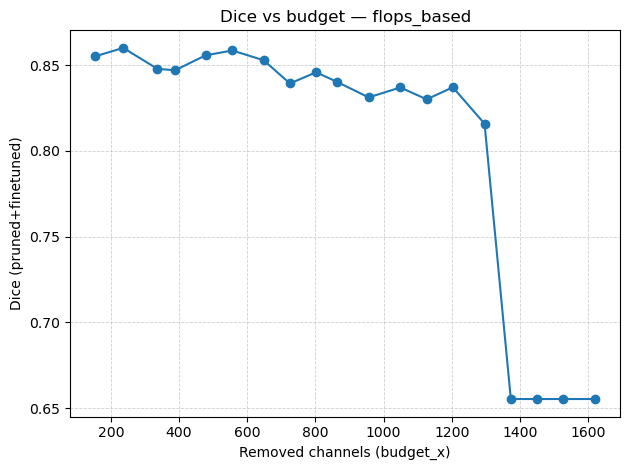

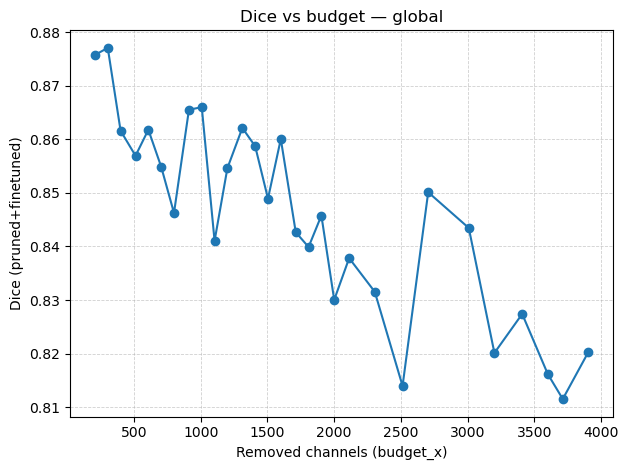

In [17]:
types = sorted(gplot["experiment_type"].unique())

for t in types:
    d = gplot[gplot["experiment_type"] == t].copy()
    d = d.sort_values("budget_x")
    plt.figure()
    plt.plot(d["budget_x"], d["dice_pruned"], marker="o")
    plt.xlabel("Removed channels (budget_x)")
    plt.ylabel("Dice (pruned+finetuned)")
    plt.title(f"Dice vs budget — {t}")
    plt.grid(True, linestyle="--", linewidth=0.6, alpha=0.6)
    plt.tight_layout()
    plt.show()


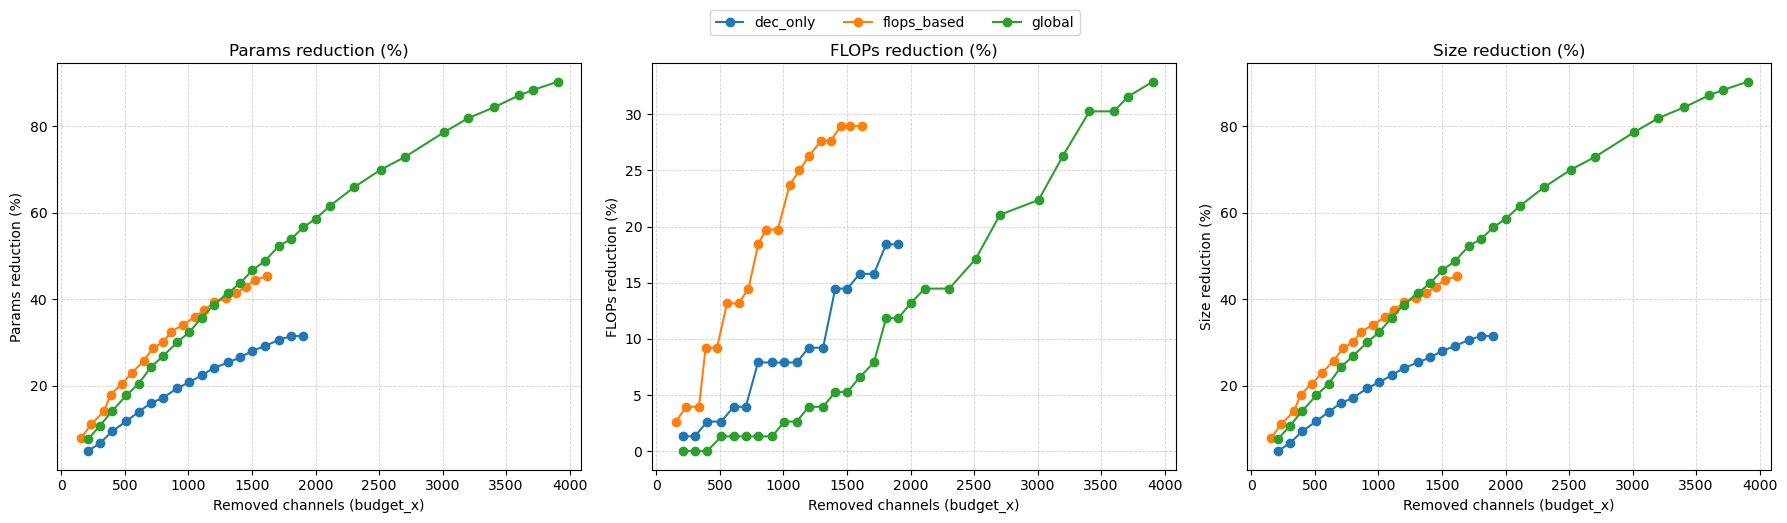

In [18]:
import matplotlib.pyplot as plt

METRICS = [
    ("params_reduction_pct", "Params reduction (%)"),
    ("flops_reduction_pct",  "FLOPs reduction (%)"),
    ("size_reduction_pct",   "Size reduction (%)"),
]

types = sorted(gplot["experiment_type"].unique())

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True)

for ax, (col, ylabel) in zip(axes, METRICS):
    if col not in gplot.columns:
        ax.set_visible(False)
        continue

    for t in types:
        d = gplot[gplot["experiment_type"] == t].copy().sort_values("budget_x")
        if len(d) == 0:
            continue
        ax.plot(d["budget_x"], d[col], marker="o", label=t)

    ax.set_xlabel("Removed channels (budget_x)")
    ax.set_ylabel(ylabel)
    ax.set_title(ylabel)
    ax.grid(True, linestyle="--", linewidth=0.6, alpha=0.6)

# one shared legend for the whole figure
handles, labels = axes[0].get_legend_handles_labels()
if handles:
    fig.legend(handles, labels, loc="upper center", ncol=min(len(labels), 6), bbox_to_anchor=(0.5, 1.05))

plt.tight_layout()
plt.show()


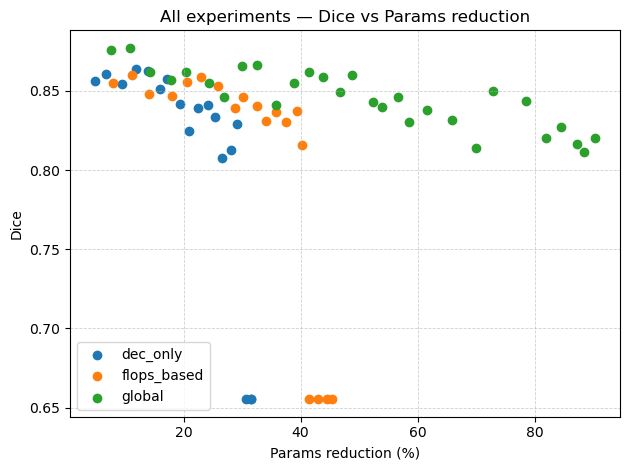

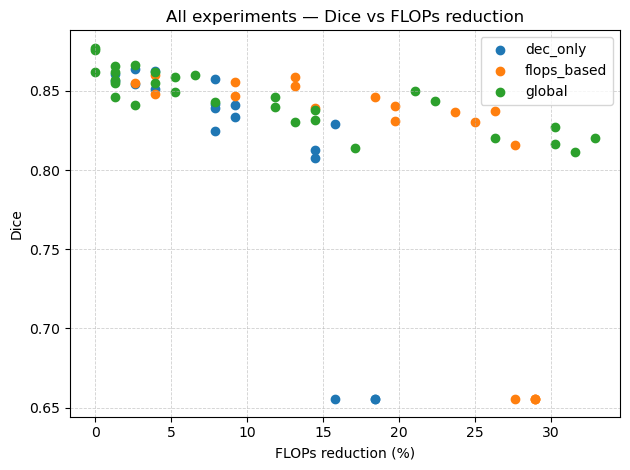

In [19]:
types = sorted(gplot["experiment_type"].unique())

# Dice vs Params reduction
plt.figure()
for t in types:
    d = gplot[gplot["experiment_type"] == t]
    plt.scatter(d["params_reduction_pct"], d["dice_pruned"], label=t)
plt.xlabel("Params reduction (%)")
plt.ylabel("Dice")
plt.title("All experiments — Dice vs Params reduction")
plt.grid(True, linestyle="--", linewidth=0.6, alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

# Dice vs FLOPs reduction
plt.figure()
for t in types:
    d = gplot[gplot["experiment_type"] == t]
    plt.scatter(d["flops_reduction_pct"], d["dice_pruned"], label=t)
plt.xlabel("FLOPs reduction (%)")
plt.ylabel("Dice")
plt.title("All experiments — Dice vs FLOPs reduction")
plt.grid(True, linestyle="--", linewidth=0.6, alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()


In [22]:
DICE_MIN = 0.8  # adjust for your acceptance threshold

types = sorted(gplot["experiment_type"].unique())

for t in types:
    d = gplot[(gplot["experiment_type"] == t) & (gplot["dice_pruned"] >= DICE_MIN)].copy()
    d = d.sort_values(["flops_reduction_pct", "params_reduction_pct"], ascending=False)
    print(f"\nTop candidates (Dice >= {DICE_MIN}) — {t}  |  rows={len(d)}")
    display(
        d[["model_name","budget_x","dice_pruned","dice_drop",
           "params_reduction_pct","flops_reduction_pct","size_reduction_pct","log_path"]]
        .reset_index(drop=True)
        .head(15)
    )



Top candidates (Dice >= 0.8) — dec_only  |  rows=15


,model_name,budget_x,dice_pruned,dice_drop,params_reduction_pct,flops_reduction_pct,size_reduction_pct,log_path
0,dec_only_d1600,1600,0.829320,0.050742,29.165668,15.789474,29.154991,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
1,dec_only_d1500,1504,0.812365,0.067697,28.100228,14.473684,28.089869,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
2,dec_only_d1400,1408,0.807445,0.072617,26.577847,14.473684,26.567300,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
3,dec_only_d1300,1312,0.833719,0.046343,25.384563,9.210526,25.374734,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
4,dec_only_d1200,1200,0.841153,0.038909,24.109520,9.210526,24.099456,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
5,dec_only_d1100,1104,0.838935,0.041127,22.408054,7.894737,22.398805,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
6,dec_only_d1000,1008,0.824502,0.055560,20.851856,7.894737,20.843321,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
7,dec_only_d900,912,0.841585,0.038477,19.426802,7.894737,19.418656,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
8,dec_only_d800,800,0.857283,0.022779,17.193337,7.894737,17.185443,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
9,dec_only_d700,704,0.851038,0.029024,15.994279,3.947368,15.986969,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...



Top candidates (Dice >= 0.8) — flops_based  |  rows=15


,model_name,budget_x,dice_pruned,dice_drop,params_reduction_pct,flops_reduction_pct,size_reduction_pct,log_path
0,flops_based_b0,1296,0.815767,0.064295,40.241751,27.631579,40.226528,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
1,flops_based_b0,1203,0.837021,0.043041,39.318006,26.315789,39.302353,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
2,flops_based_b0,1126,0.830008,0.050054,37.516787,25.000000,37.502110,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
3,flops_based_b0,1049,0.836929,0.043133,35.851290,23.684211,35.836906,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
4,flops_based_b0,956,0.831126,0.048936,34.071235,19.736842,34.057763,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
5,flops_based_b0,863,0.840186,0.039876,32.482467,19.736842,32.469363,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
6,flops_based_b0,802,0.845789,0.034273,30.092750,18.421053,30.080855,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
7,flops_based_b0,725,0.839241,0.040821,28.807059,14.473684,28.795449,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
8,flops_based_b0,648,0.852785,0.027277,25.788536,13.157895,25.778164,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
9,flops_based_b0,556,0.858468,0.021594,22.964303,13.157895,22.954998,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...



Top candidates (Dice >= 0.8) — global  |  rows=29


,model_name,budget_x,dice_pruned,dice_drop,params_reduction_pct,flops_reduction_pct,size_reduction_pct,log_path
0,global_b0,3904,0.820302,0.059760,90.325204,32.894737,90.285608,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
1,global_b0,3712,0.811516,0.068546,88.443260,31.578947,88.403498,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
2,global_b0,3600,0.816164,0.063898,87.169815,30.263158,87.130752,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
3,global_b0,3408,0.827399,0.052663,84.465594,30.263158,84.426589,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
4,global_b0,3200,0.820119,0.059943,81.884939,26.315789,81.846494,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
5,global_b0,3008,0.843456,0.036606,78.601963,22.368421,78.565038,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
6,global_b0,2704,0.850125,0.029937,72.941647,21.052632,72.906890,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
7,global_b0,2512,0.813956,0.066106,69.965292,17.105263,69.930961,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
8,global_b0,2304,0.831534,0.048528,65.947829,14.473684,65.915229,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
9,global_b0,2112,0.837821,0.042241,61.570082,14.473684,61.539111,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...


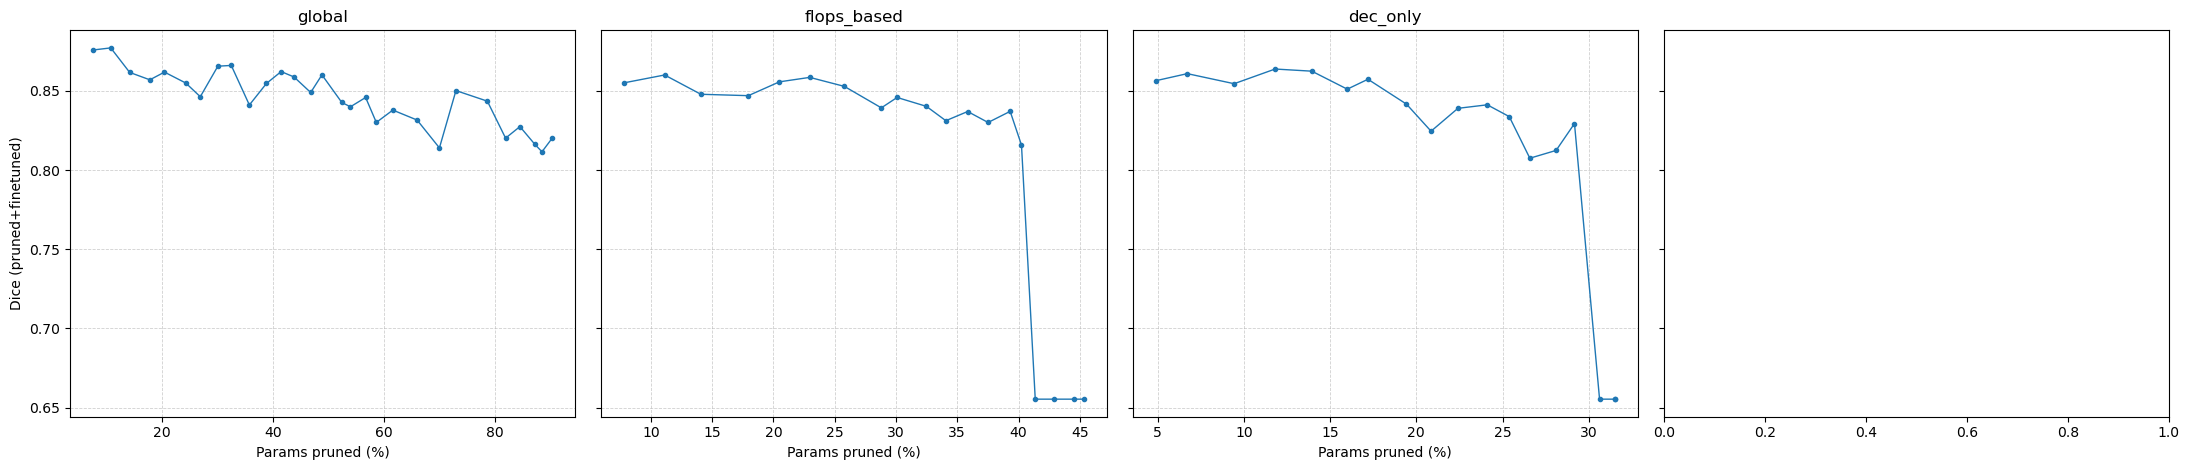

In [25]:
import numpy as np
import matplotlib.pyplot as plt

# We plot Dice vs pruning % (x-axis = params pruned %) for each experiment_type
XCOL = "params_reduction_pct"
YCOL = "dice_pruned"

ORDER = ["global", "flops_based", "dec_only"]  # adjust to your exact labels if needed

present = [t for t in ORDER if t in set(gplot["experiment_type"].unique())]
missing = [t for t in ORDER if t not in set(gplot["experiment_type"].unique())]
if missing:
    print("Missing experiment_type(s):", missing)

fig, axes = plt.subplots(1, 4, figsize=(22, 4.8), sharey=True)

for ax, t in zip(axes, ORDER):
    if t not in set(gplot["experiment_type"].unique()):
        ax.set_title(f"{t} (missing)")
        ax.axis("off")
        continue

    d = gplot[gplot["experiment_type"] == t].dropna(subset=[XCOL, YCOL]).copy()
    d = d.sort_values(XCOL)

    ax.plot(d[XCOL], d[YCOL], marker="o", linewidth=1, markersize=3)
    ax.set_title(t)
    ax.set_xlabel("Params pruned (%)")
    ax.grid(True, linestyle="--", linewidth=0.6, alpha=0.6)

axes[0].set_ylabel("Dice (pruned+finetuned)")

plt.tight_layout()
plt.show()


Common budgets kept: 7
Budget range: (400.0, 1600.0)


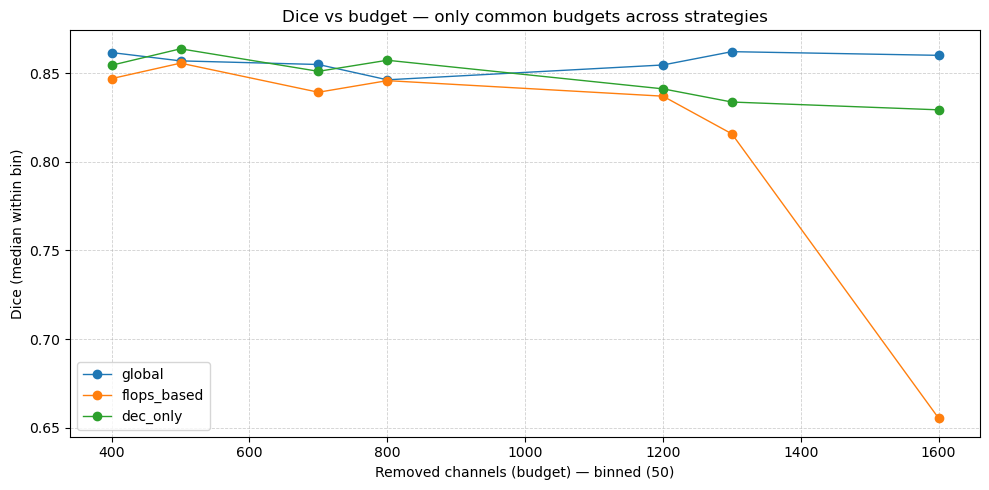

,budget_bin,experiment_type,dice_med,dice_mean,n
0,400.0,dec_only,0.854474,0.854474,1
1,400.0,flops_based,0.846929,0.846929,1
2,400.0,global,0.861614,0.861614,1
3,500.0,dec_only,0.863740,0.863740,1
4,500.0,flops_based,0.855653,0.855653,1
5,500.0,global,0.856934,0.856934,1
6,700.0,dec_only,0.851038,0.851038,1
7,700.0,flops_based,0.839241,0.839241,1
8,700.0,global,0.854890,0.854890,1
9,800.0,dec_only,0.857283,0.857283,1


In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BIN_W = 50


tmp = gplot.dropna(subset=["budget_x", "dice_pruned", "experiment_type"]).copy()
tmp = tmp[tmp["experiment_type"].isin(ORDER)].copy()

# Bin budgets
tmp["budget_bin"] = (tmp["budget_x"] / BIN_W).round() * BIN_W

# Keep ONLY budgets that exist for ALL experiment types (clean comparison)
budgets_by_type = tmp.groupby("experiment_type")["budget_bin"].apply(set).to_dict()
common_budgets = set.intersection(*(budgets_by_type[t] for t in budgets_by_type))
tmp_common = tmp[tmp["budget_bin"].isin(common_budgets)].copy()

print("Common budgets kept:", len(common_budgets))
print("Budget range:", (min(common_budgets), max(common_budgets)) if common_budgets else "None")

# Aggregate within each (budget_bin, type)
cmp = (
    tmp_common.groupby(["budget_bin", "experiment_type"])
              .agg(dice_med=("dice_pruned", "median"),
                   dice_mean=("dice_pruned", "mean"),
                   n=("dice_pruned", "count"))
              .reset_index()
)

pivot = (
    cmp.pivot_table(index="budget_bin", columns="experiment_type", values="dice_med")
       .sort_index()
)

cols = [c for c in ORDER if c in pivot.columns]
pivot = pivot[cols]

plt.figure(figsize=(10, 5))
for c in pivot.columns:
    plt.plot(pivot.index, pivot[c], marker="o", linewidth=1, label=c)

plt.xlabel(f"Removed channels (budget) — binned ({BIN_W})")
plt.ylabel("Dice (median within bin)")
plt.title("Dice vs budget — only common budgets across strategies")
plt.grid(True, linestyle="--", linewidth=0.6, alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

# Optional table
display(cmp.sort_values(["budget_bin", "experiment_type"]).head(80))


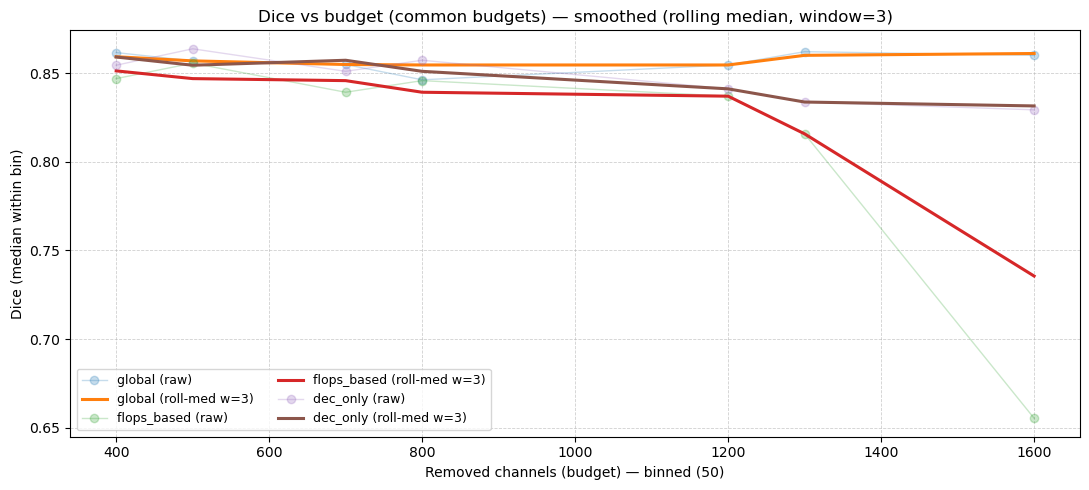

experiment_type,global,flops_based,dec_only
budget_bin,,,
400.0,0.859274,0.851291,0.859107
500.0,0.856934,0.846929,0.854474
700.0,0.854890,0.845789,0.857283
800.0,0.854621,0.839241,0.851038
1200.0,0.854621,0.837021,0.841153
1300.0,0.860057,0.815767,0.833719
1600.0,0.861094,0.735567,0.831519


In [27]:
# Cell — Smoothed view of the "common budgets" curves (rolling median + optional rolling mean)
# Uses: `pivot` from your previous cell (index=budget_bin, columns=experiment_type, values=dice_med)

import matplotlib.pyplot as plt

# ---- config ----
ROLL = 3          # window size in number of budget bins (try 3, 5, 7)
CENTER = True     # center the rolling window
MINP = 1          # allow edges to be computed

# If budgets are not evenly spaced or you want stricter smoothing, increase ROLL.
pivot_s = pivot.sort_index()

# Rolling statistics (robust + smoother)
pivot_roll_med = pivot_s.rolling(window=ROLL, center=CENTER, min_periods=MINP).median()
pivot_roll_mean = pivot_s.rolling(window=ROLL, center=CENTER, min_periods=MINP).mean()

# ---- plot ----
fig, ax = plt.subplots(figsize=(11, 5))

# Plot raw (faint) + smoothed (bold)
for c in pivot_s.columns:
    ax.plot(pivot_s.index, pivot_s[c], marker="o", linewidth=1, alpha=0.25, label=f"{c} (raw)")
    ax.plot(pivot_roll_med.index, pivot_roll_med[c], linewidth=2.2, label=f"{c} (roll-med w={ROLL})")
    # Uncomment if you also want rolling mean overlay:
    # ax.plot(pivot_roll_mean.index, pivot_roll_mean[c], linewidth=2.0, linestyle="--", label=f"{c} (roll-mean w={ROLL})")

ax.set_xlabel(f"Removed channels (budget) — binned ({BIN_W})")
ax.set_ylabel("Dice (median within bin)")
ax.set_title(f"Dice vs budget (common budgets) — smoothed (rolling median, window={ROLL})")
ax.grid(True, linestyle="--", linewidth=0.6, alpha=0.6)

# keep legend readable
ax.legend(ncol=2, fontsize=9)
plt.tight_layout()
plt.show()

# Optional: show the smoothed table to inspect values
display(pivot_roll_med.head(20))


#### Aggregated Metrics

#### Per-Block Metrics

In [28]:
# Cell A1 — Build aggregated-groups plotting table (from your existing df_runs + df_baseline)
# Goal: a clean table with encoder/bottleneck/decoder (params + flops) % reductions + dice + budget for all runs.

import numpy as np
import pandas as pd

GROUPS = ["encoder", "bottleneck", "decoder"]

# pick a baseline reference row (your df_baseline is 1 row)
brow = df_baseline.iloc[0].to_dict()

# Start from df_runs (already has global metrics + some agg fields extracted from logs)
ag = df_runs.copy()

# Ensure we have a single budget column for plotting in this section too
if "budget_x" not in ag.columns:
    if "removed_channels_reported" in ag.columns and ag["removed_channels_reported"].notna().any():
        ag["budget_x"] = pd.to_numeric(ag["removed_channels_reported"], errors="coerce")
    else:
        ag["budget_x"] = pd.to_numeric(ag["requested_budget_channels"], errors="coerce")

# Compute derived aggregated reductions (params + flops) against baseline (robust to missing keep/reduce printed fields)
for g in GROUPS:
    # ----- Params -----
    pcol = f"{g}_params_pruned"
    bval = brow.get(f"{g}_params_baseline", np.nan)

    if pcol in ag.columns and pd.notna(bval) and bval != 0:
        ag[f"{g}_params_keep_pct_recalc"] = 100.0 * pd.to_numeric(ag[pcol], errors="coerce") / bval
        ag[f"{g}_params_reduce_pct_recalc"] = 100.0 - ag[f"{g}_params_keep_pct_recalc"]
    else:
        ag[f"{g}_params_keep_pct_recalc"] = np.nan
        ag[f"{g}_params_reduce_pct_recalc"] = np.nan

    # ----- FLOPs (absolute) -----
    fcol = f"{g}_flops_abs_pruned"
    bval = brow.get(f"{g}_flops_abs_baseline", np.nan)

    if fcol in ag.columns and pd.notna(bval) and bval != 0:
        ag[f"{g}_flops_keep_pct_recalc"] = 100.0 * pd.to_numeric(ag[fcol], errors="coerce") / bval
        ag[f"{g}_flops_reduce_pct_recalc"] = 100.0 - ag[f"{g}_flops_keep_pct_recalc"]
    else:
        ag[f"{g}_flops_keep_pct_recalc"] = np.nan
        ag[f"{g}_flops_reduce_pct_recalc"] = np.nan

# Build a compact plotting dataframe
keep_cols = [
    "model_name","experiment_type","log_path","budget_x",
    "dice_pruned","dice_drop",
    "params_reduction_pct","flops_reduction_pct","size_reduction_pct",
]
for g in GROUPS:
    keep_cols += [
        f"{g}_params_reduce_pct_recalc",
        f"{g}_flops_reduce_pct_recalc",
    ]

keep_cols = [c for c in keep_cols if c in ag.columns]
agplot = ag[keep_cols].copy()

# Drop rows missing the aggregated columns completely (you can loosen if needed)
CRIT_AGG = ["dice_pruned","budget_x"] + [f"{g}_params_reduce_pct_recalc" for g in GROUPS]
CRIT_AGG = [c for c in CRIT_AGG if c in agplot.columns]
agplot = agplot.dropna(subset=CRIT_AGG)

print("agplot rows:", len(agplot), "/", len(df_runs))
print("Experiment types:", sorted(agplot["experiment_type"].unique()))
display(agplot.head(10))


agplot rows: 66 / 67
Experiment types: ['dec_only', 'flops_based', 'global']


,model_name,experiment_type,log_path,budget_x,dice_pruned,dice_drop,params_reduction_pct,flops_reduction_pct,size_reduction_pct,encoder_params_reduce_pct_recalc,encoder_flops_reduce_pct_recalc,bottleneck_params_reduce_pct_recalc,bottleneck_flops_reduce_pct_recalc,decoder_params_reduce_pct_recalc,decoder_flops_reduce_pct_recalc
0,dec_only_d200,dec_only,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,208,0.856334,0.023728,4.882527,1.315789,4.879984,0.0,NaN,0.0,NaN,12.431158,NaN
1,dec_only_d300,dec_only,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,304,0.860830,0.019232,6.720086,1.315789,6.716519,0.0,NaN,0.0,NaN,17.109674,NaN
2,dec_only_d400,dec_only,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,400,0.854474,0.025588,9.435133,2.631579,9.430809,0.0,NaN,0.0,NaN,24.022319,NaN
3,dec_only_d500,dec_only,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,512,0.863740,0.016322,11.809639,2.631579,11.804125,0.0,NaN,0.0,NaN,30.067930,NaN
4,dec_only_d600,dec_only,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,608,0.862386,0.017676,13.939075,3.947368,13.932683,0.0,NaN,0.0,NaN,35.489581,NaN
5,dec_only_d700,dec_only,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,704,0.851038,0.029024,15.994279,3.947368,15.986969,0.0,NaN,0.0,NaN,40.722233,NaN
6,dec_only_d800,dec_only,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,800,0.857283,0.022779,17.193337,7.894737,17.185443,0.0,NaN,0.0,NaN,43.775094,NaN
7,dec_only_d900,dec_only,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,912,0.841585,0.038477,19.426802,7.894737,19.418656,0.0,NaN,0.0,NaN,49.461607,NaN
8,dec_only_d1000,dec_only,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,1008,0.824502,0.055560,20.851856,7.894737,20.843321,0.0,NaN,0.0,NaN,53.089866,NaN
9,dec_only_d1100,dec_only,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,1104,0.838935,0.041127,22.408054,7.894737,22.398805,0.0,NaN,0.0,NaN,57.052023,NaN


In [29]:
# Cell A2 — Sanity check aggregated columns coverage (by experiment_type)
import pandas as pd

GROUPS = ["encoder","bottleneck","decoder"]

chk = []
for t, d in agplot.groupby("experiment_type"):
    row = {"experiment_type": t, "n": len(d)}
    for g in GROUPS:
        c1 = f"{g}_params_reduce_pct_recalc"
        c2 = f"{g}_flops_reduce_pct_recalc"
        row[f"{g}_params_na%"] = float(d[c1].isna().mean()*100) if c1 in d.columns else 100.0
        row[f"{g}_flops_na%"] = float(d[c2].isna().mean()*100) if c2 in d.columns else 100.0
    chk.append(row)

chk = pd.DataFrame(chk).sort_values("n", ascending=False)
display(chk)


,experiment_type,n,encoder_params_na%,encoder_flops_na%,bottleneck_params_na%,bottleneck_flops_na%,decoder_params_na%,decoder_flops_na%
2,global,29,0.0,100.0,0.0,100.0,0.0,100.0
1,flops_based,19,0.0,100.0,0.0,100.0,0.0,100.0
0,dec_only,18,0.0,100.0,0.0,100.0,0.0,100.0


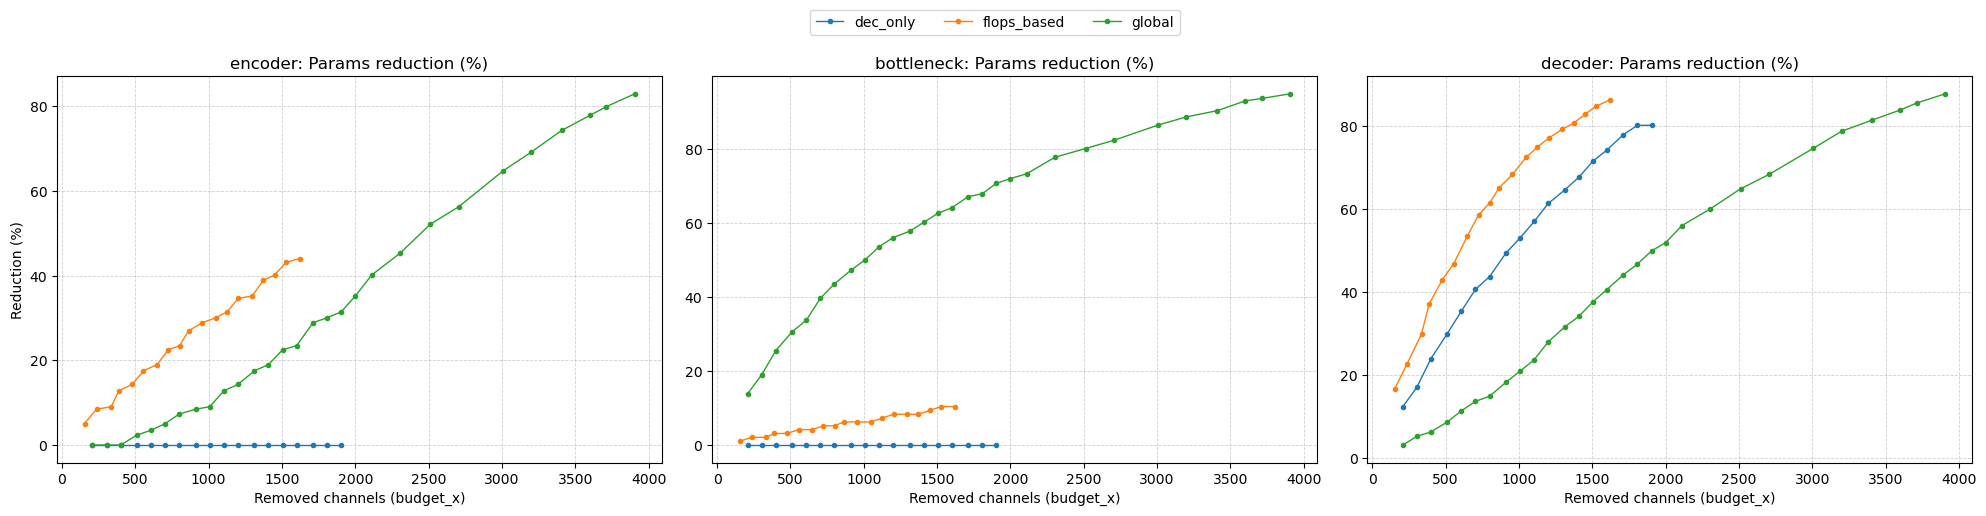

In [30]:
# Cell A3 — 2×3 figure: aggregated PARAMS reduction (%) per group, one subplot per group, lines by experiment_type
import matplotlib.pyplot as plt

GROUPS = ["encoder","bottleneck","decoder"]
types = sorted(agplot["experiment_type"].unique())

fig, axes = plt.subplots(1, 3, figsize=(20, 4.8), sharex=True)

for ax, g in zip(axes, GROUPS):
    col = f"{g}_params_reduce_pct_recalc"
    for t in types:
        d = agplot[agplot["experiment_type"] == t].dropna(subset=["budget_x", col]).copy()
        if len(d) == 0:
            continue
        d = d.sort_values("budget_x")
        ax.plot(d["budget_x"], d[col], marker="o", linewidth=1, markersize=3, label=t)

    ax.set_title(f"{g}: Params reduction (%)")
    ax.set_xlabel("Removed channels (budget_x)")
    ax.grid(True, linestyle="--", linewidth=0.6, alpha=0.6)

axes[0].set_ylabel("Reduction (%)")

handles, labels = axes[0].get_legend_handles_labels()
if handles:
    fig.legend(handles, labels, loc="upper center", ncol=min(len(labels), 6), bbox_to_anchor=(0.5, 1.08))

plt.tight_layout()
plt.show()


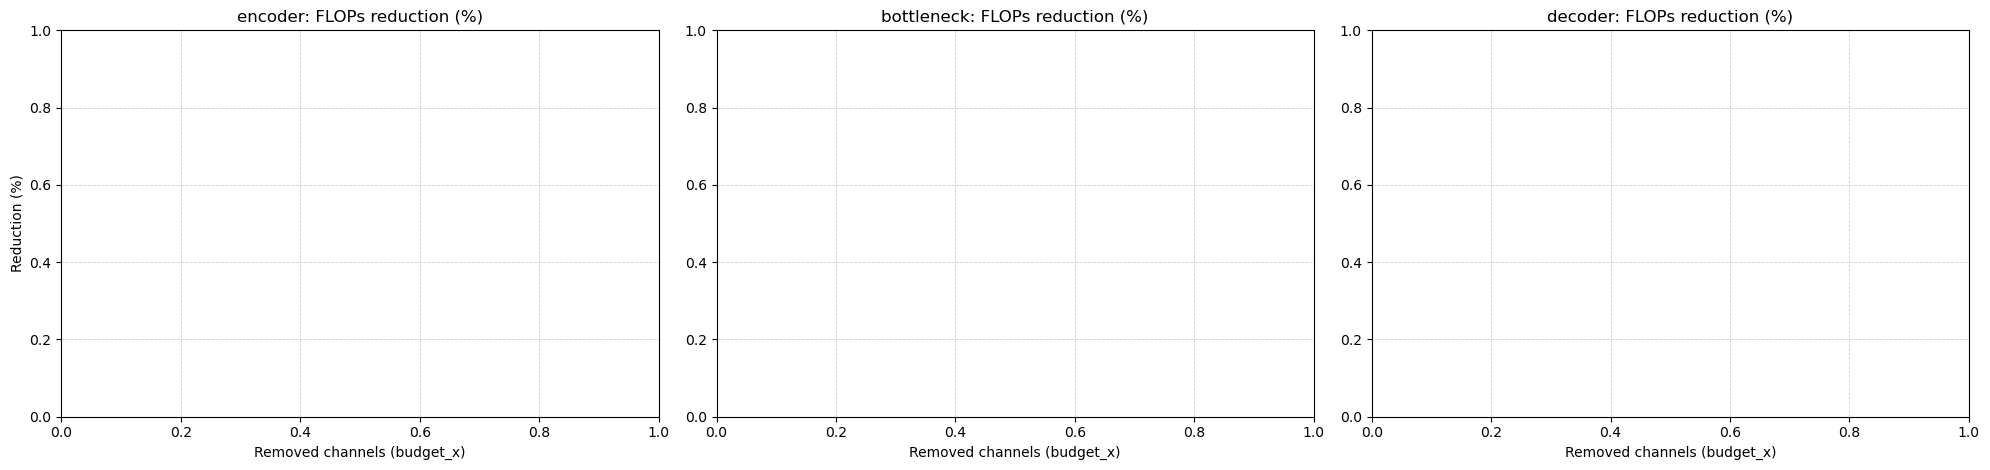

In [31]:
# Cell A4 — 2×3 figure: aggregated FLOPs reduction (%) per group, one subplot per group, lines by experiment_type
import matplotlib.pyplot as plt

GROUPS = ["encoder","bottleneck","decoder"]
types = sorted(agplot["experiment_type"].unique())

fig, axes = plt.subplots(1, 3, figsize=(20, 4.8), sharex=True)

for ax, g in zip(axes, GROUPS):
    col = f"{g}_flops_reduce_pct_recalc"
    for t in types:
        d = agplot[agplot["experiment_type"] == t].dropna(subset=["budget_x", col]).copy()
        if len(d) == 0:
            continue
        d = d.sort_values("budget_x")
        ax.plot(d["budget_x"], d[col], marker="o", linewidth=1, markersize=3, label=t)

    ax.set_title(f"{g}: FLOPs reduction (%)")
    ax.set_xlabel("Removed channels (budget_x)")
    ax.grid(True, linestyle="--", linewidth=0.6, alpha=0.6)

axes[0].set_ylabel("Reduction (%)")

handles, labels = axes[0].get_legend_handles_labels()
if handles:
    fig.legend(handles, labels, loc="upper center", ncol=min(len(labels), 6), bbox_to_anchor=(0.5, 1.08))

plt.tight_layout()
plt.show()


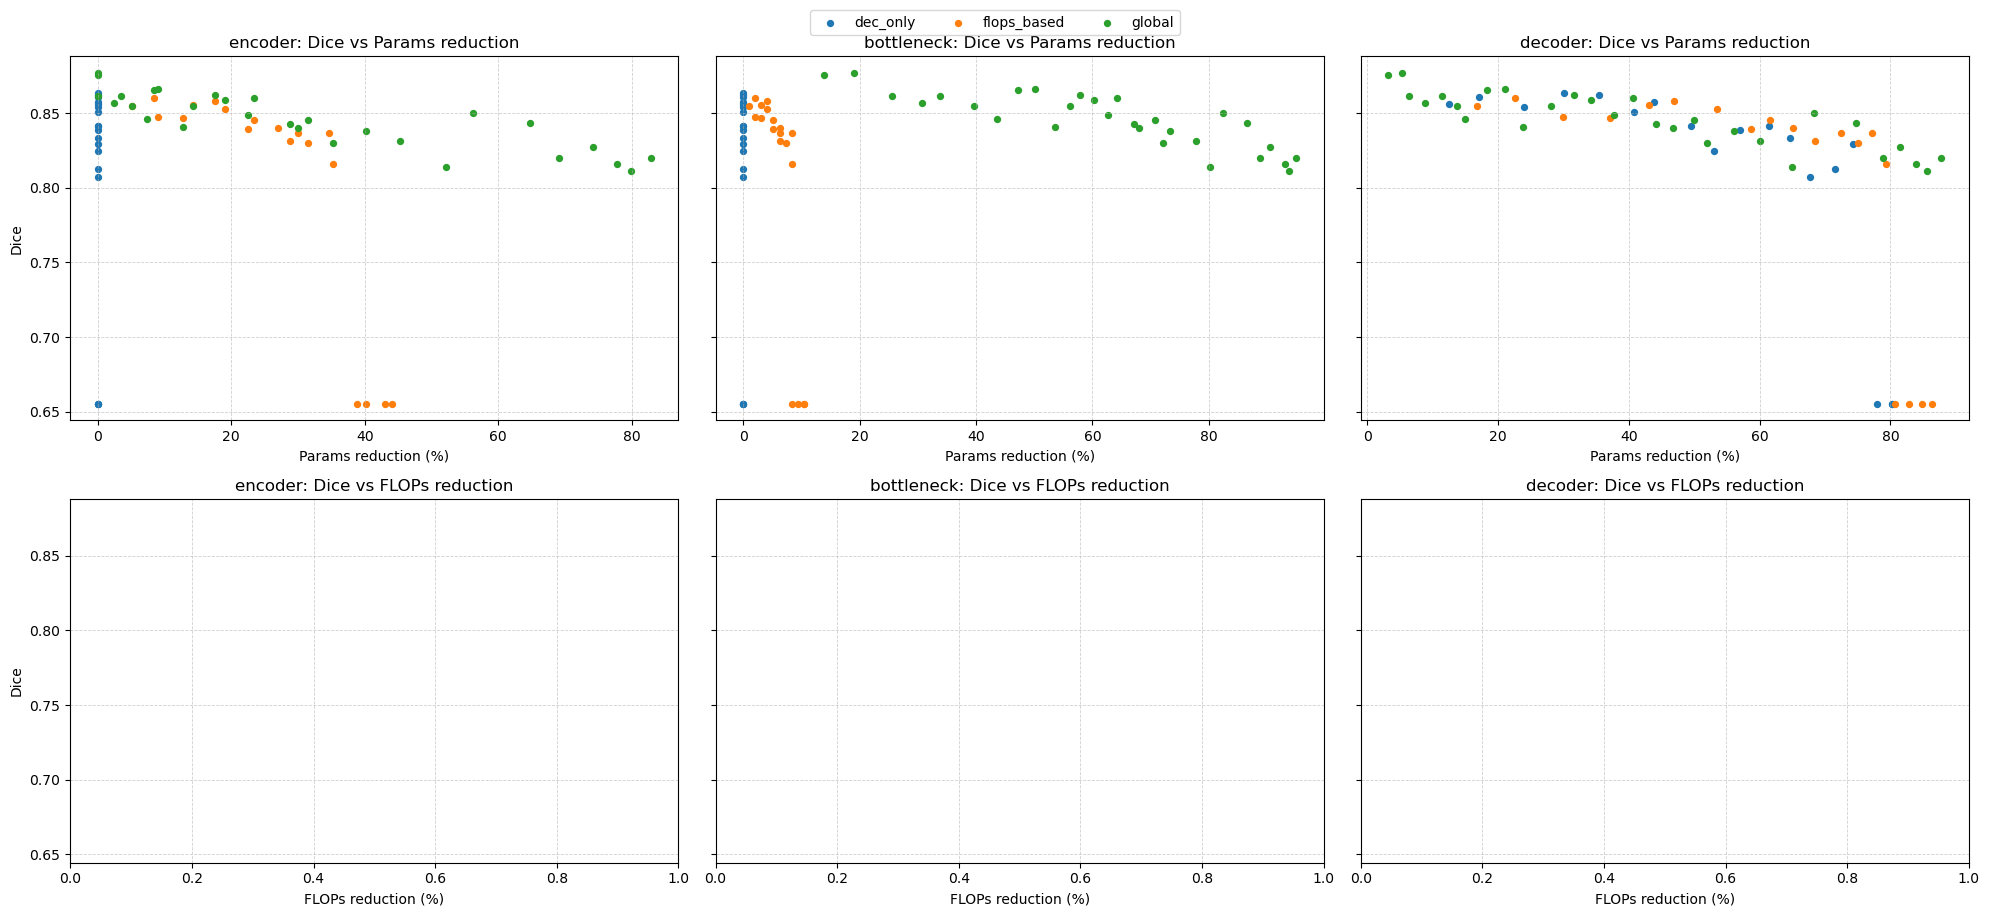

In [32]:
# Cell A5 — 2×3 scatter: Dice vs aggregated reductions (params & flops) per group, colored by experiment_type
import matplotlib.pyplot as plt

GROUPS = ["encoder","bottleneck","decoder"]
types = sorted(agplot["experiment_type"].unique())

fig, axes = plt.subplots(2, 3, figsize=(20, 9), sharey=True)

for j, g in enumerate(GROUPS):
    x1 = f"{g}_params_reduce_pct_recalc"
    x2 = f"{g}_flops_reduce_pct_recalc"

    # Dice vs Params reduction
    ax = axes[0, j]
    for t in types:
        d = agplot[agplot["experiment_type"] == t].dropna(subset=[x1, "dice_pruned"])
        if len(d) == 0:
            continue
        ax.scatter(d[x1], d["dice_pruned"], s=18, label=t)
    ax.set_title(f"{g}: Dice vs Params reduction")
    ax.set_xlabel("Params reduction (%)")
    ax.grid(True, linestyle="--", linewidth=0.6, alpha=0.6)

    # Dice vs FLOPs reduction
    ax = axes[1, j]
    for t in types:
        d = agplot[agplot["experiment_type"] == t].dropna(subset=[x2, "dice_pruned"])
        if len(d) == 0:
            continue
        ax.scatter(d[x2], d["dice_pruned"], s=18, label=t)
    ax.set_title(f"{g}: Dice vs FLOPs reduction")
    ax.set_xlabel("FLOPs reduction (%)")
    ax.grid(True, linestyle="--", linewidth=0.6, alpha=0.6)

axes[0, 0].set_ylabel("Dice")
axes[1, 0].set_ylabel("Dice")

# one shared legend
handles, labels = axes[0, 0].get_legend_handles_labels()
if handles:
    fig.legend(handles, labels, loc="upper center", ncol=min(len(labels), 6), bbox_to_anchor=(0.5, 1.02))

plt.tight_layout()
plt.show()


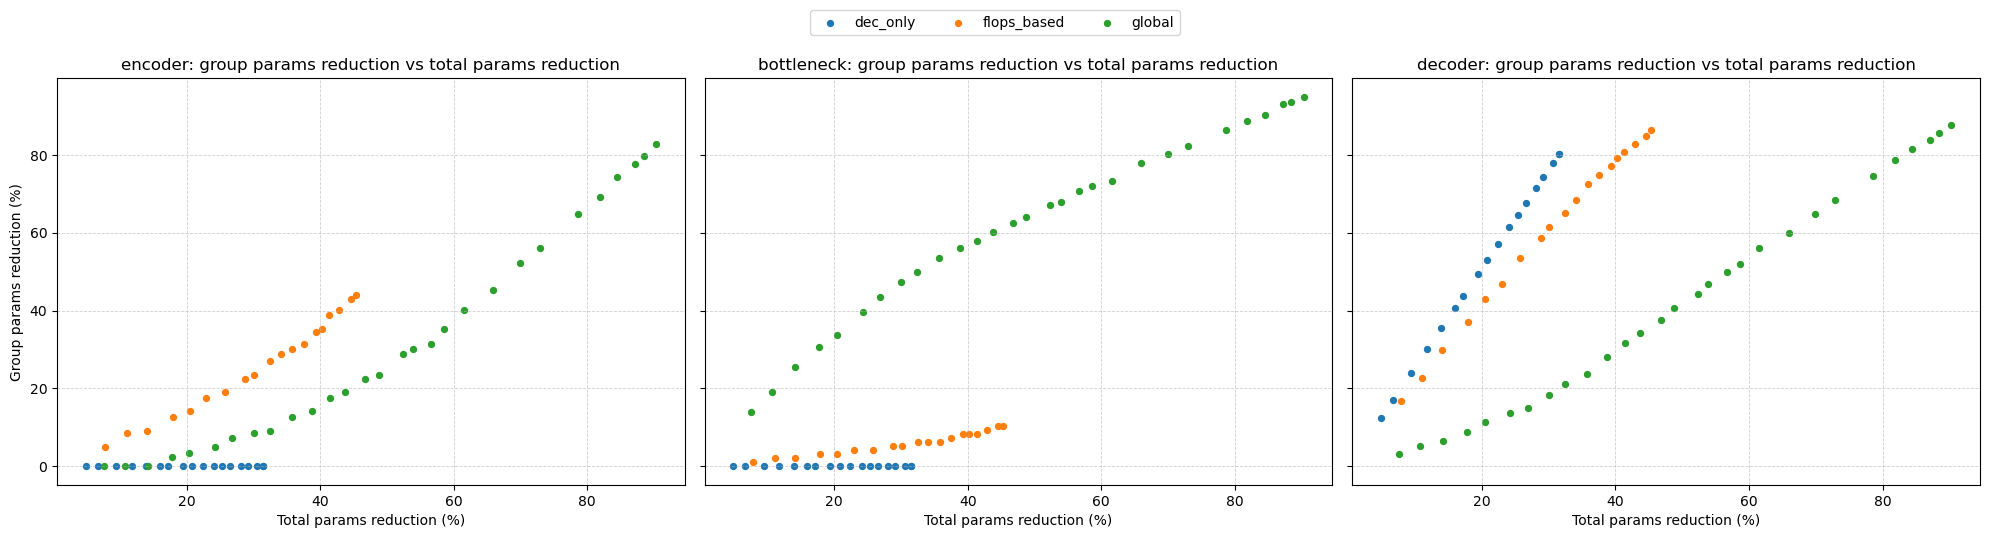

In [33]:
# Cell A6 — Within each experiment_type: "where is the pruning going?"
# Plot (encoder/bottleneck/decoder params reduction) vs total params reduction, as points.
import matplotlib.pyplot as plt

GROUPS = ["encoder","bottleneck","decoder"]

fig, axes = plt.subplots(1, 3, figsize=(20, 5), sharey=True)

for ax, g in zip(axes, GROUPS):
    x = "params_reduction_pct"
    y = f"{g}_params_reduce_pct_recalc"
    for t in sorted(agplot["experiment_type"].unique()):
        d = agplot[agplot["experiment_type"] == t].dropna(subset=[x, y])
        if len(d) == 0:
            continue
        ax.scatter(d[x], d[y], s=18, label=t)
    ax.set_title(f"{g}: group params reduction vs total params reduction")
    ax.set_xlabel("Total params reduction (%)")
    ax.grid(True, linestyle="--", linewidth=0.6, alpha=0.6)

axes[0].set_ylabel("Group params reduction (%)")

handles, labels = axes[0].get_legend_handles_labels()
if handles:
    fig.legend(handles, labels, loc="upper center", ncol=min(len(labels), 6), bbox_to_anchor=(0.5, 1.08))

plt.tight_layout()
plt.show()


In [34]:
# Cell A7 — Table: Top candidates under a dice constraint, ranked by encoder/bottleneck/decoder reduction
# (useful to see if a strategy mainly shrinks bottleneck vs decoder, etc.)
import pandas as pd

DICE_MIN = 0.8  # tune

cols = [
    "experiment_type","model_name","budget_x","dice_pruned","dice_drop",
    "params_reduction_pct","flops_reduction_pct","size_reduction_pct",
    "encoder_params_reduce_pct_recalc","bottleneck_params_reduce_pct_recalc","decoder_params_reduce_pct_recalc",
    "encoder_flops_reduce_pct_recalc","bottleneck_flops_reduce_pct_recalc","decoder_flops_reduce_pct_recalc",
    "log_path",
]
cols = [c for c in cols if c in agplot.columns]

for t in sorted(agplot["experiment_type"].unique()):
    d = agplot[(agplot["experiment_type"] == t) & (agplot["dice_pruned"] >= DICE_MIN)].copy()
    d = d.sort_values(["flops_reduction_pct","params_reduction_pct"], ascending=False)
    print(f"\nTop candidates (Dice >= {DICE_MIN}) — {t}  |  rows={len(d)}")
    display(d[cols].head(20).reset_index(drop=True))



Top candidates (Dice >= 0.8) — dec_only  |  rows=15


,experiment_type,model_name,budget_x,dice_pruned,dice_drop,params_reduction_pct,flops_reduction_pct,size_reduction_pct,encoder_params_reduce_pct_recalc,bottleneck_params_reduce_pct_recalc,decoder_params_reduce_pct_recalc,encoder_flops_reduce_pct_recalc,bottleneck_flops_reduce_pct_recalc,decoder_flops_reduce_pct_recalc,log_path
0,dec_only,dec_only_d1600,1600,0.829320,0.050742,29.165668,15.789474,29.154991,0.0,0.0,74.257247,NaN,NaN,NaN,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
1,dec_only,dec_only_d1500,1504,0.812365,0.067697,28.100228,14.473684,28.089869,0.0,0.0,71.544584,NaN,NaN,NaN,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
2,dec_only,dec_only_d1400,1408,0.807445,0.072617,26.577847,14.473684,26.567300,0.0,0.0,67.668526,NaN,NaN,NaN,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
3,dec_only,dec_only_d1300,1312,0.833719,0.046343,25.384563,9.210526,25.374734,0.0,0.0,64.630365,NaN,NaN,NaN,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
4,dec_only,dec_only_d1200,1200,0.841153,0.038909,24.109520,9.210526,24.099456,0.0,0.0,61.384042,NaN,NaN,NaN,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
5,dec_only,dec_only_d1100,1104,0.838935,0.041127,22.408054,7.894737,22.398805,0.0,0.0,57.052023,NaN,NaN,NaN,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
6,dec_only,dec_only_d1000,1008,0.824502,0.055560,20.851856,7.894737,20.843321,0.0,0.0,53.089866,NaN,NaN,NaN,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
7,dec_only,dec_only_d900,912,0.841585,0.038477,19.426802,7.894737,19.418656,0.0,0.0,49.461607,NaN,NaN,NaN,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
8,dec_only,dec_only_d800,800,0.857283,0.022779,17.193337,7.894737,17.185443,0.0,0.0,43.775094,NaN,NaN,NaN,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
9,dec_only,dec_only_d700,704,0.851038,0.029024,15.994279,3.947368,15.986969,0.0,0.0,40.722233,NaN,NaN,NaN,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...



Top candidates (Dice >= 0.8) — flops_based  |  rows=15


,experiment_type,model_name,budget_x,dice_pruned,dice_drop,params_reduction_pct,flops_reduction_pct,size_reduction_pct,encoder_params_reduce_pct_recalc,bottleneck_params_reduce_pct_recalc,decoder_params_reduce_pct_recalc,encoder_flops_reduce_pct_recalc,bottleneck_flops_reduce_pct_recalc,decoder_flops_reduce_pct_recalc,log_path
0,flops_based,flops_based_b0,1296,0.815767,0.064295,40.241751,27.631579,40.226528,35.170811,8.330923,79.257465,NaN,NaN,NaN,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
1,flops_based,flops_based_b0,1203,0.837021,0.043041,39.318006,26.315789,39.302353,34.629432,8.330923,77.113727,NaN,NaN,NaN,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
2,flops_based,flops_based_b0,1126,0.830008,0.050054,37.516787,25.000000,37.502110,31.433048,7.289557,74.966347,NaN,NaN,NaN,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
3,flops_based,flops_based_b0,1049,0.836929,0.043133,35.851290,23.684211,35.836906,30.056049,6.248192,72.464963,NaN,NaN,NaN,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
4,flops_based,flops_based_b0,956,0.831126,0.048936,34.071235,19.736842,34.057763,28.865768,6.248192,68.390521,NaN,NaN,NaN,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
5,flops_based,flops_based_b0,863,0.840186,0.039876,32.482467,19.736842,32.469363,26.948074,6.248192,65.082798,NaN,NaN,NaN,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
6,flops_based,flops_based_b0,802,0.845789,0.034273,30.092750,18.421053,30.080855,23.456765,5.206827,61.550474,NaN,NaN,NaN,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
7,flops_based,flops_based_b0,725,0.839241,0.040821,28.807059,14.473684,28.795449,22.472999,5.206827,58.655300,NaN,NaN,NaN,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
8,flops_based,flops_based_b0,648,0.852785,0.027277,25.788536,13.157895,25.778164,18.981690,4.165461,53.522004,NaN,NaN,NaN,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
9,flops_based,flops_based_b0,556,0.858468,0.021594,22.964303,13.157895,22.954998,17.506383,4.165687,46.898363,NaN,NaN,NaN,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...



Top candidates (Dice >= 0.8) — global  |  rows=29


,experiment_type,model_name,budget_x,dice_pruned,dice_drop,params_reduction_pct,flops_reduction_pct,size_reduction_pct,encoder_params_reduce_pct_recalc,bottleneck_params_reduce_pct_recalc,decoder_params_reduce_pct_recalc,encoder_flops_reduce_pct_recalc,bottleneck_flops_reduce_pct_recalc,decoder_flops_reduce_pct_recalc,log_path
0,global,global_b0,3904,0.820302,0.059760,90.325204,32.894737,90.285608,82.888898,94.982780,87.774494,NaN,NaN,NaN,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
1,global,global_b0,3712,0.811516,0.068546,88.443260,31.578947,88.403498,79.887765,93.745480,85.574097,NaN,NaN,NaN,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
2,global,global_b0,3600,0.816164,0.063898,87.169815,30.263158,87.130752,77.821925,93.077904,83.901586,NaN,NaN,NaN,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
3,global,global_b0,3408,0.827399,0.052663,84.465594,30.263158,84.426589,74.280097,90.424546,81.460347,NaN,NaN,NaN,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
4,global,global_b0,3200,0.820119,0.059943,81.884939,26.315789,81.846494,69.163970,88.764192,78.785615,NaN,NaN,NaN,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
5,global,global_b0,3008,0.843456,0.036606,78.601963,22.368421,78.565038,64.727468,86.566884,74.685120,NaN,NaN,NaN,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
6,global,global_b0,2704,0.850125,0.029937,72.941647,21.052632,72.906890,56.219023,82.416338,68.366248,NaN,NaN,NaN,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
7,global,global_b0,2512,0.813956,0.066106,69.965292,17.105263,69.930961,52.137181,80.202759,64.928957,NaN,NaN,NaN,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
8,global,global_b0,2304,0.831534,0.048528,65.947829,14.473684,65.915229,45.252188,77.859009,60.069972,NaN,NaN,NaN,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
9,global,global_b0,2112,0.837821,0.042241,61.570082,14.473684,61.539111,40.137427,73.399534,56.070540,NaN,NaN,NaN,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...


## Distribution of Pruned Models: Aggregated Blocks


In [35]:
# Cell 1 (REPLACEMENT) — Select EXACT comparison budgets per experiment_type (16 samples total)
# Uses df_runs directly (NOT gplot), because df_runs contains aggregated group metrics.
# Budgets: 300, 500, 900, 1600
# Types: global, enc_only, bottleneck_only, dec_only
# Output: df_cmp (<=16 rows depending on availability) + availability report.

import numpy as np
import pandas as pd
COMPARE_BUDGETS = [300, 900, 1600, 3000]

ORDER_TYPES = ["global", "flops_based", "params_based", "balanced"]
GROUPS = ["encoder", "bottleneck", "decoder"]

# Work from df_runs (it has encoder/bottleneck/decoder_*_pruned columns)
src = df_runs.copy()

# Define budget_x consistently
src["budget_x"] = src["removed_channels_reported"].where(src["removed_channels_reported"].notna(),
                                                        src["requested_budget_channels"])
src["budget_x"] = pd.to_numeric(src["budget_x"], errors="coerce")

# Require group pruned cols
need_cols = [f"{g}_params_pruned" for g in GROUPS]
missing_need = [c for c in need_cols if c not in src.columns]
if missing_need:
    raise KeyError(f"Missing required group columns in df_runs: {missing_need}")

src = src.dropna(subset=["experiment_type", "budget_x"] + need_cols).copy()
src = src[src["experiment_type"].isin(ORDER_TYPES)].copy()

def pick_exact_or_closest_one(dt: pd.DataFrame, target: float) -> pd.DataFrame:
    """
    Prefer exact match budget_x==target; else pick closest.
    Tie-breaker: smaller dist, then higher dice_pruned.
    """
    if len(dt) == 0:
        return dt

    exact = dt[dt["budget_x"] == target].copy()
    if len(exact) > 0:
        dd = exact
        dd["dist"] = 0.0
    else:
        dd = dt.copy()
        dd["dist"] = (dd["budget_x"] - target).abs()

    sort_cols = ["dist"]
    asc = [True]
    if "dice_pruned" in dd.columns:
        sort_cols.append("dice_pruned")
        asc.append(False)

    return dd.sort_values(sort_cols, ascending=asc).head(1)

picked_rows = []
avail_rows = []

for t in ORDER_TYPES:
    dt = src[src["experiment_type"] == t].copy()
    if len(dt) == 0:
        for b in COMPARE_BUDGETS:
            avail_rows.append((t, "NO_ROWS", b, np.nan, np.nan, "", ""))
        continue

    for b in COMPARE_BUDGETS:
        one = pick_exact_or_closest_one(dt, b)
        if len(one) == 0:
            avail_rows.append((t, "MISSING", b, np.nan, np.nan, "", ""))
            continue

        r = one.iloc[0]
        status = "EXACT" if float(r["budget_x"]) == float(b) else "CLOSEST"
        avail_rows.append((
            t, status, b,
            int(r["budget_x"]) if pd.notna(r["budget_x"]) else np.nan,
            float(r.get("dice_pruned", np.nan)),
            r.get("model_name", ""),
            r.get("log_path", "")
        ))
        picked_rows.append(one.drop(columns=["dist"], errors="ignore"))

df_cmp = pd.concat(picked_rows, axis=0).reset_index(drop=True) if picked_rows else pd.DataFrame()

avail_df = pd.DataFrame(
    avail_rows,
    columns=["experiment_type","status","target_budget","picked_budget","dice_pruned","model_name","log_path"]
)

print("Targets:", COMPARE_BUDGETS)
print("Types:", ORDER_TYPES)
print("Selected rows:", len(df_cmp), "(max 16)")
display(avail_df)

if len(df_cmp) > 0:
    show_cols = ["experiment_type","budget_x","model_name","dice_pruned","log_path"]
    show_cols = [c for c in show_cols if c in df_cmp.columns]
    display(df_cmp[show_cols].sort_values(["experiment_type","budget_x"]).reset_index(drop=True))


Targets: [300, 900, 1600, 3000]
Types: ['global', 'flops_based', 'params_based', 'balanced']
Selected rows: 8 (max 16)


,experiment_type,status,target_budget,picked_budget,dice_pruned,model_name,log_path
0,global,CLOSEST,300,304.0,0.877079,global_b0,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
1,global,CLOSEST,900,912.0,0.865532,global_b0,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
2,global,EXACT,1600,1600.0,0.860057,global_b0,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
3,global,CLOSEST,3000,3008.0,0.843456,global_b0,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
4,flops_based,CLOSEST,300,336.0,0.847803,flops_based_b0,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
5,flops_based,CLOSEST,900,863.0,0.840186,flops_based_b0,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
6,flops_based,CLOSEST,1600,1620.0,0.655367,flops_based_b0,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
7,flops_based,CLOSEST,3000,1620.0,0.655367,flops_based_b0,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
8,params_based,NO_ROWS,300,NaN,NaN,,
9,params_based,NO_ROWS,900,NaN,NaN,,


,experiment_type,budget_x,model_name,dice_pruned,log_path
0,flops_based,336,flops_based_b0,0.847803,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
1,flops_based,863,flops_based_b0,0.840186,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
2,flops_based,1620,flops_based_b0,0.655367,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
3,flops_based,1620,flops_based_b0,0.655367,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
4,global,304,global_b0,0.877079,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
5,global,912,global_b0,0.865532,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
6,global,1600,global_b0,0.860057,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
7,global,3008,global_b0,0.843456,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...


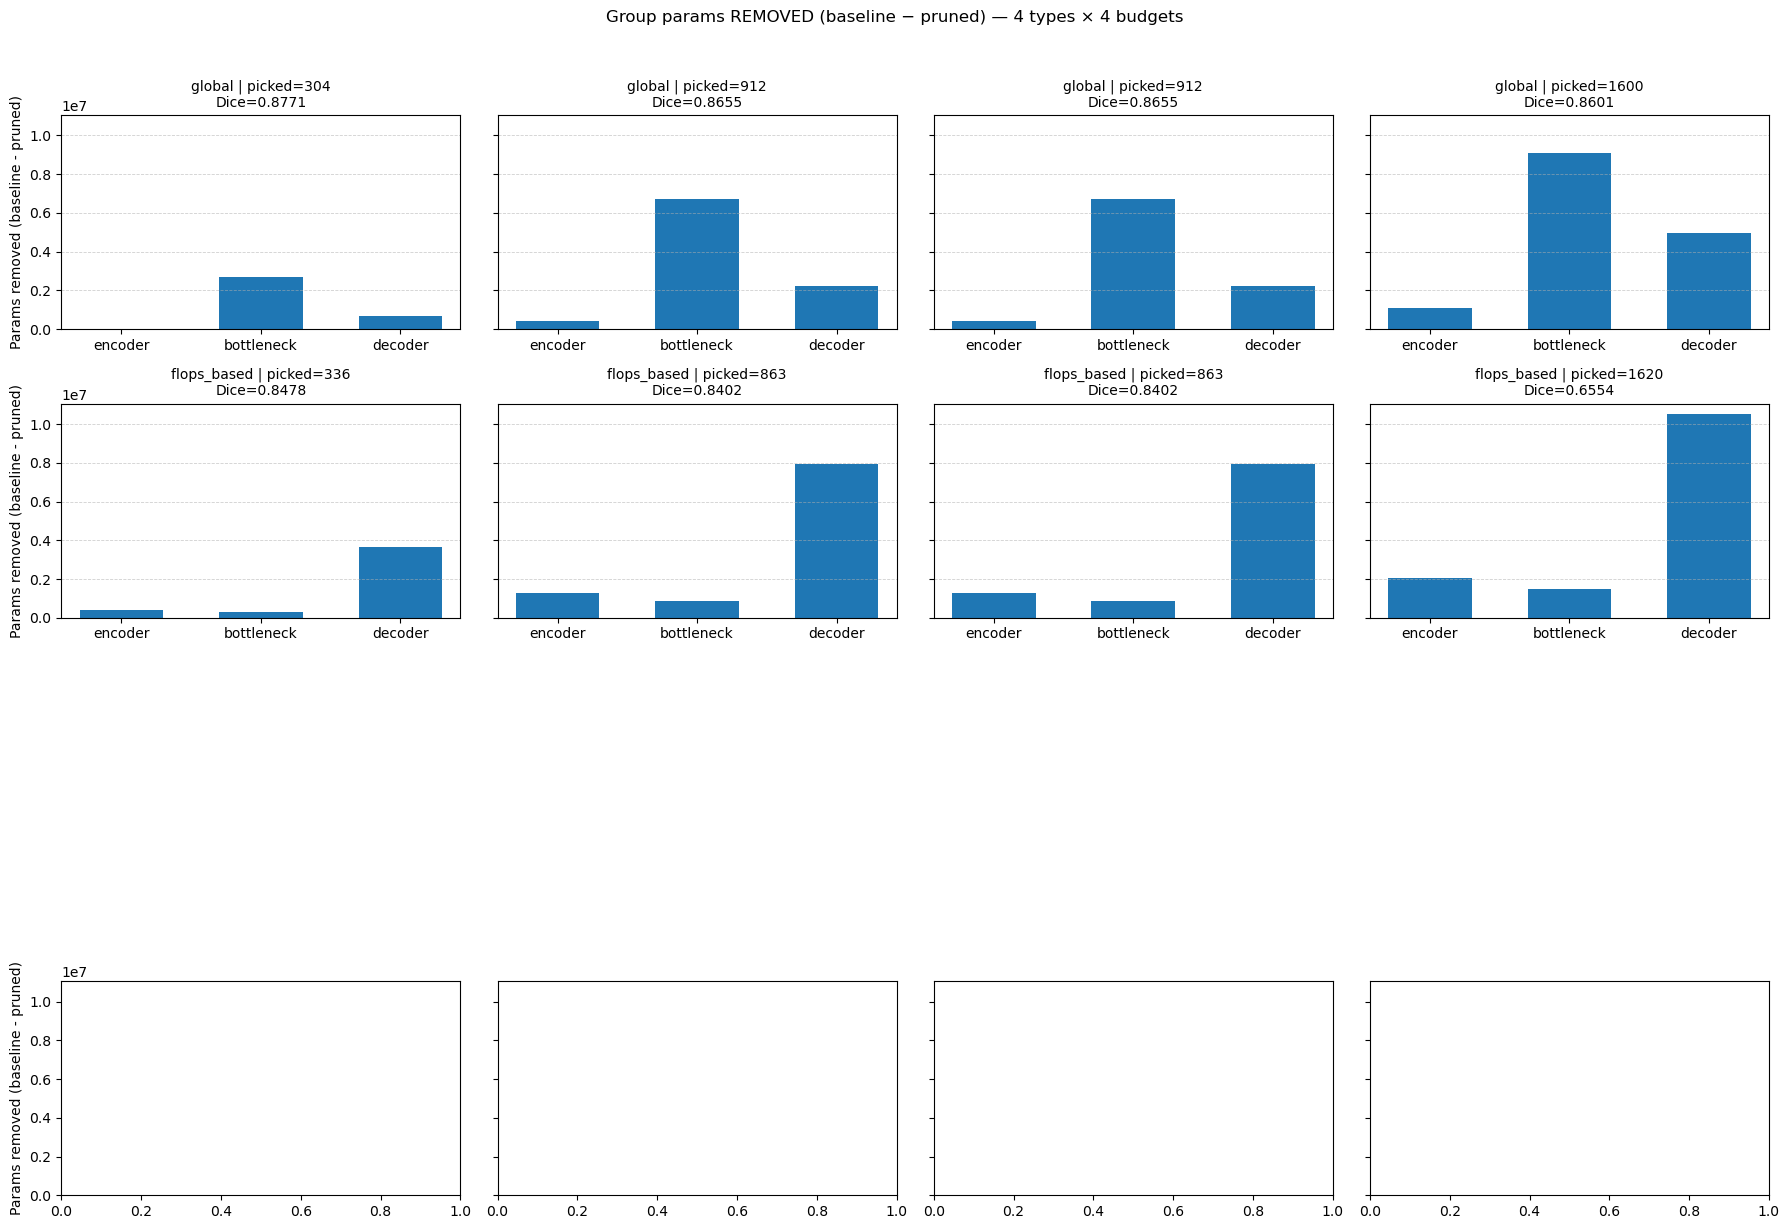

In [39]:
# Cell 2 (REPLACEMENT) — Plot REMOVED params per group (baseline - pruned) for the 16 samples
# Works even if you do NOT have *_params_baseline columns for groups:
# it derives baseline group params from df_baseline totals + baseline group shares from the lowest-budget GLOBAL run.

import numpy as np
import matplotlib.pyplot as plt

GROUPS = ["encoder", "bottleneck", "decoder"]
ORDER_TYPES = ["global", "flops_based", "dec_only"]
COMPARE_BUDGETS = [300, 900, 1200, 1600]

# --- Build baseline group params (robust) ---
# Prefer true baseline group params if present in df_baseline
have_true = all(f"{g}_params_baseline" in df_baseline.columns for g in GROUPS) and \
            df_baseline.loc[0, [f"{g}_params_baseline" for g in GROUPS]].notna().all()

if have_true:
    base = np.array([float(df_baseline.loc[0, f"{g}_params_baseline"]) for g in GROUPS], dtype=float)
else:
    # Fallback: estimate baseline group params using baseline total params and group shares from smallest GLOBAL run
    if "params_baseline" not in df_baseline.columns:
        raise KeyError("df_baseline must contain params_baseline")

    P0 = float(df_baseline.loc[0, "params_baseline"])

    ref_pool = df_runs[df_runs["experiment_type"] == "global"].copy()
    ref_pool["budget_x"] = ref_pool["removed_channels_reported"].where(ref_pool["removed_channels_reported"].notna(),
                                                                      ref_pool["requested_budget_channels"])
    ref_pool = ref_pool.dropna(subset=["budget_x"] + [f"{g}_params_pruned" for g in GROUPS])
    if len(ref_pool) == 0:
        raise RuntimeError("Cannot estimate baseline group shares: no GLOBAL rows with group params pruned.")

    ref = ref_pool.sort_values("budget_x").iloc[0]
    pr = np.array([float(ref[f"{g}_params_pruned"]) for g in GROUPS], dtype=float)
    sh = pr / pr.sum() if pr.sum() else np.array([1/3, 1/3, 1/3], dtype=float)
    base = P0 * sh

# --- Plot ---
if len(df_cmp) == 0:
    raise RuntimeError("df_cmp is empty. Fix selection cell first.")

fig, axes = plt.subplots(4, 4, figsize=(18, 12), sharey=True)
x = np.arange(len(GROUPS))

def _get_one(df, t, target_budget):
    dd = df[df["experiment_type"] == t].copy()
    if len(dd) == 0:
        return None
    dd["dist"] = (dd["budget_x"] - target_budget).abs()
    sort_cols = ["dist"]
    asc = [True]
    if "dice_pruned" in dd.columns:
        sort_cols.append("dice_pruned")
        asc.append(False)
    return dd.sort_values(sort_cols, ascending=asc).iloc[0]

for i, t in enumerate(ORDER_TYPES):
    for j, b in enumerate(COMPARE_BUDGETS):
        ax = axes[i, j]
        r = _get_one(df_cmp, t, b)
        if r is None:
            ax.axis("off")
            continue

        pr = np.array([float(r.get(f"{g}_params_pruned", np.nan)) for g in GROUPS], dtype=float)
        removed = base - pr
        removed = np.where(np.isfinite(removed), removed, 0.0)

        ax.bar(x, removed, width=0.6)
        ax.set_xticks(x)
        ax.set_xticklabels(GROUPS)
        ax.grid(True, axis="y", linestyle="--", linewidth=0.6, alpha=0.6)
        ax.set_title(f"{t} | picked={int(r['budget_x'])}\nDice={float(r.get('dice_pruned', np.nan)):.4f}", fontsize=10)

for r in range(4):
    axes[r, 0].set_ylabel("Params removed (baseline - pruned)")

plt.suptitle("Group params REMOVED (baseline − pruned) — 4 types × 4 budgets", y=1.02)
plt.tight_layout()
plt.show()


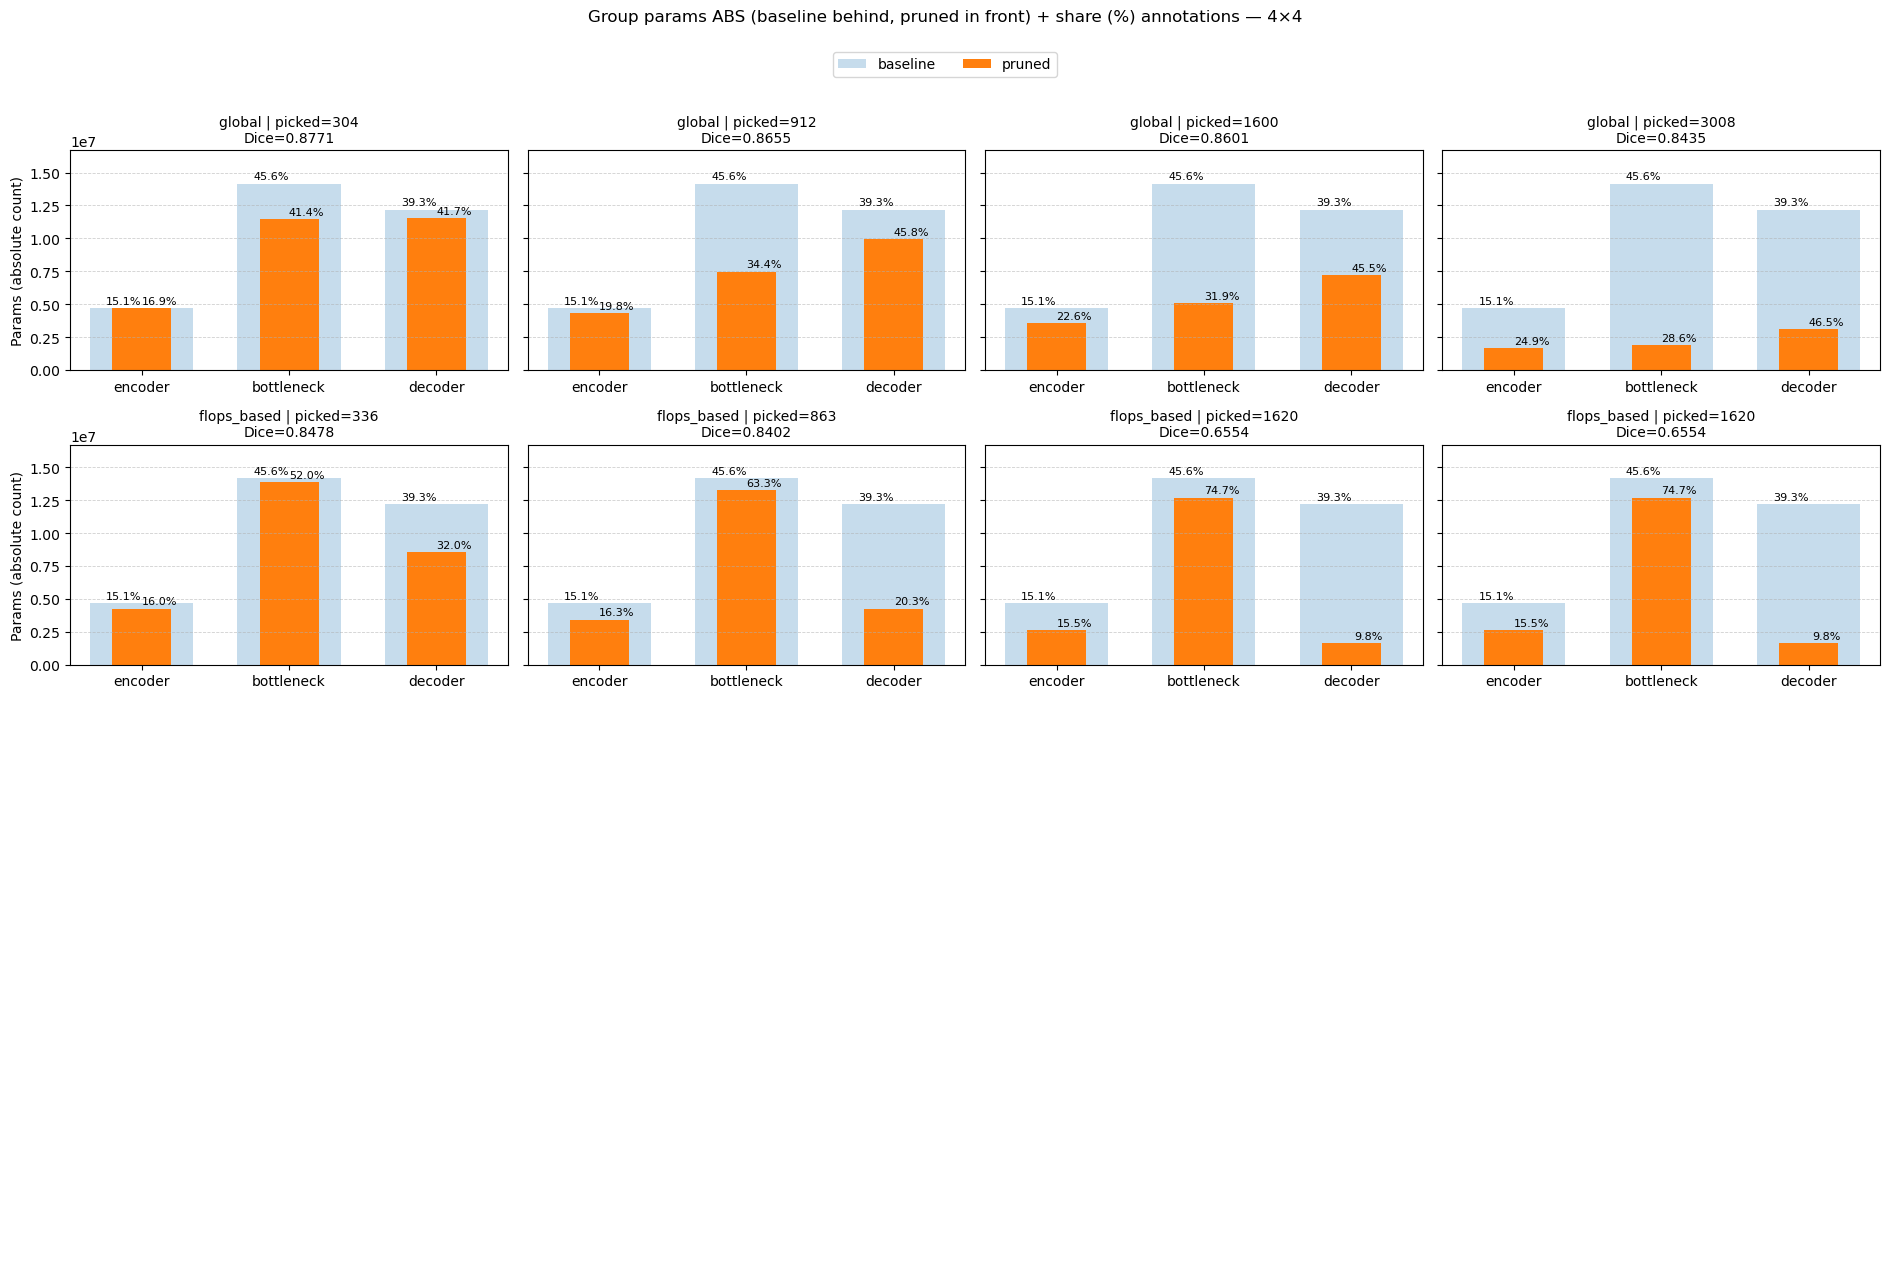

In [40]:
# Cell (REPLACEMENT) — Group params ABS (baseline behind, pruned in front)
# + annotate each bar with its SHARE (%) so you get both: absolute + distribution.
# 4 types × 4 budgets

import numpy as np
import matplotlib.pyplot as plt

GROUPS = ["encoder", "bottleneck", "decoder"]
ORDER_TYPES = ["global", "flops_based", "params_based", "balanced"]
COMPARE_BUDGETS = [300, 900, 1600, 3000]

if len(df_cmp) == 0:
    raise RuntimeError("df_cmp is empty. Run the selection cell first.")

# ---- Baseline absolute group params (robust) ----
# If true baseline group params exist, use them; else estimate from smallest-budget GLOBAL run shares.
have_true = all(f"{g}_params_baseline" in df_baseline.columns for g in GROUPS) and \
            df_baseline.loc[0, [f"{g}_params_baseline" for g in GROUPS]].notna().all()

if have_true:
    base_abs = np.array([float(df_baseline.loc[0, f"{g}_params_baseline"]) for g in GROUPS], dtype=float)
else:
    if "params_baseline" not in df_baseline.columns:
        raise KeyError("df_baseline must contain params_baseline")
    P0 = float(df_baseline.loc[0, "params_baseline"])

    ref_pool = df_runs[df_runs["experiment_type"] == "global"].copy()
    ref_pool["budget_x"] = ref_pool["removed_channels_reported"].where(
        ref_pool["removed_channels_reported"].notna(), ref_pool["requested_budget_channels"]
    )
    ref_pool = ref_pool.dropna(subset=["budget_x"] + [f"{g}_params_pruned" for g in GROUPS])
    if len(ref_pool) == 0:
        raise RuntimeError("No GLOBAL rows with group params to estimate baseline distribution.")
    ref = ref_pool.sort_values("budget_x").iloc[0]

    pr_ref = np.array([float(ref[f"{g}_params_pruned"]) for g in GROUPS], dtype=float)
    sh = pr_ref / pr_ref.sum() if pr_ref.sum() else np.array([1/3, 1/3, 1/3], dtype=float)
    base_abs = P0 * sh

def _pick_row(df, t, target_budget):
    dd = df[df["experiment_type"] == t].copy()
    if len(dd) == 0:
        return None
    dd["dist"] = (dd["budget_x"] - target_budget).abs()
    sort_cols = ["dist"]
    asc = [True]
    if "dice_pruned" in dd.columns:
        sort_cols.append("dice_pruned")
        asc.append(False)
    return dd.sort_values(sort_cols, ascending=asc).iloc[0]

def _annot_share(ax, xs, heights, share, dy=0.01):
    """
    Annotate each bar with share (%) above the bar.
    dy is relative to axis y-range.
    """
    y0, y1 = ax.get_ylim()
    pad = (y1 - y0) * dy
    for x, h, s in zip(xs, heights, share):
        if not np.isfinite(h) or h <= 0 or not np.isfinite(s):
            continue
        ax.text(x, h + pad, f"{s:.1f}%", ha="center", va="bottom", fontsize=8, rotation=0)

x = np.arange(len(GROUPS))

fig, axes = plt.subplots(4, 4, figsize=(19, 12), sharey=True)

for i, t in enumerate(ORDER_TYPES):
    for j, b in enumerate(COMPARE_BUDGETS):
        ax = axes[i, j]
        r = _pick_row(df_cmp, t, b)
        if r is None:
            ax.axis("off")
            continue

        pr_abs = np.array([float(r.get(f"{g}_params_pruned", np.nan)) for g in GROUPS], dtype=float)
        if not np.isfinite(pr_abs).all() or pr_abs.sum() <= 0:
            ax.axis("off")
            continue

        # shares
        base_share = base_abs / base_abs.sum() * 100 if base_abs.sum() else np.full_like(base_abs, np.nan)
        pr_share   = pr_abs   / pr_abs.sum()   * 100 if pr_abs.sum()   else np.full_like(pr_abs, np.nan)

        # baseline behind (blue)
        ax.bar(x, base_abs, width=0.70, alpha=0.25, label="baseline" if (i==0 and j==0) else None)
        # pruned in front (orange)
        ax.bar(x, pr_abs, width=0.40, alpha=1.00, label="pruned" if (i==0 and j==0) else None)

        ax.set_xticks(x)
        ax.set_xticklabels(GROUPS)
        ax.grid(True, axis="y", linestyle="--", linewidth=0.6, alpha=0.6)

        # y-limits: keep enough headroom for text labels
        ymax = max(base_abs.max(), pr_abs.max())
        ax.set_ylim(0, ymax * 1.18)

        # annotate shares (both baseline & pruned)
        # baseline labels slightly left; pruned labels slightly right so they don't overlap
        _annot_share(ax, x - 0.12, base_abs, base_share, dy=0.01)
        _annot_share(ax, x + 0.12, pr_abs,   pr_share,   dy=0.01)

        ax.set_title(
            f"{t} | picked={int(r['budget_x'])}\nDice={float(r.get('dice_pruned', np.nan)):.4f}",
            fontsize=10
        )

for r_i in range(4):
    axes[r_i, 0].set_ylabel("Params (absolute count)")

handles, labels = axes[0, 0].get_legend_handles_labels()
if handles:
    fig.legend(handles, labels, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.02))

plt.suptitle("Group params ABS (baseline behind, pruned in front) + share (%) annotations — 4×4", y=1.05)
plt.tight_layout()
plt.show()


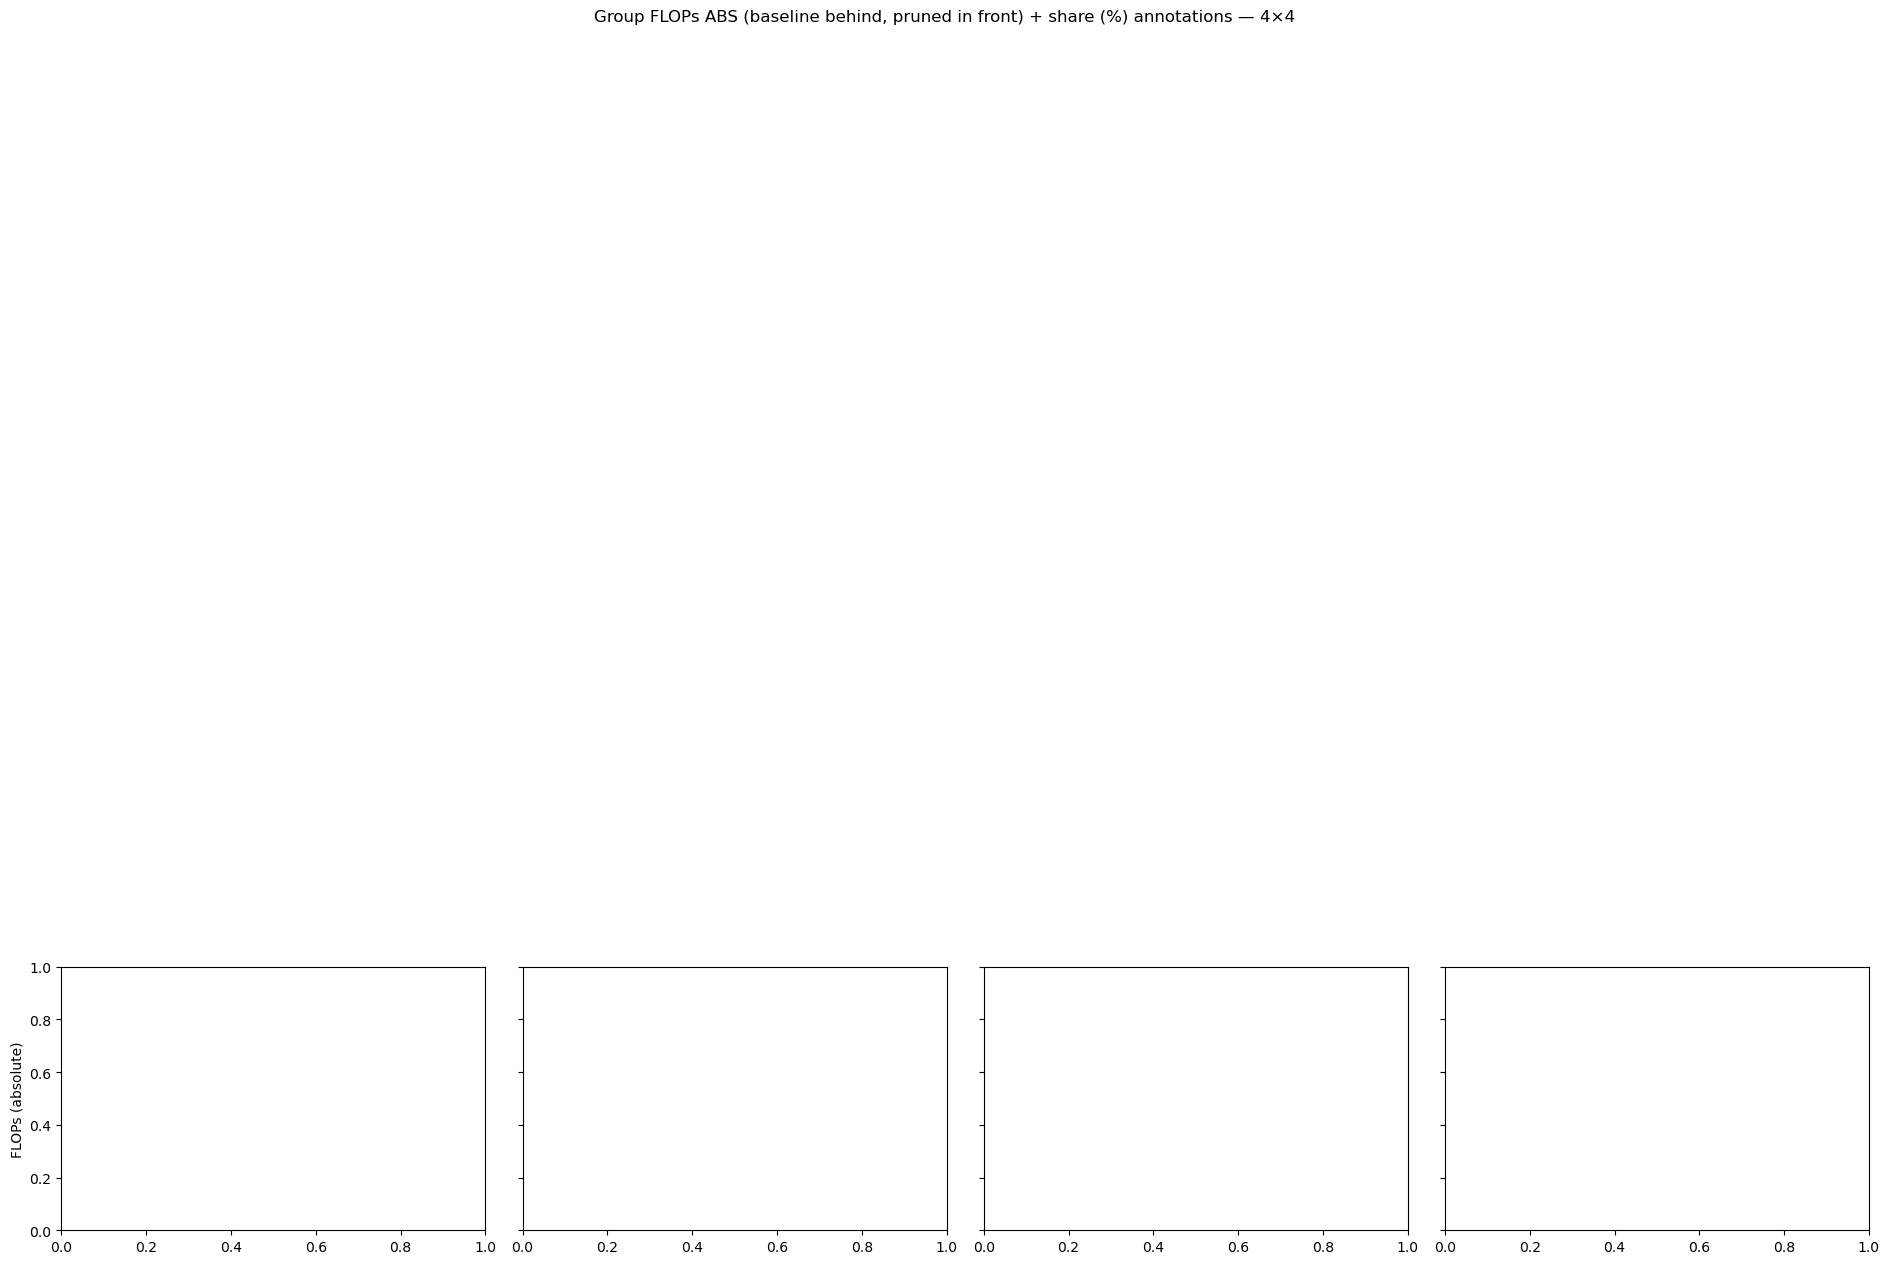

In [41]:
# Cell — Group FLOPs ABS (baseline behind, pruned in front) + share (%) annotations
# Uses aggregated group FLOPs if available (encoder/bottleneck/decoder), otherwise falls back to per-part FLOPs sums.

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

GROUPS = ["encoder", "bottleneck", "decoder"]
ORDER_TYPES = ["global", "flops_based", "dec_only"]
COMPARE_BUDGETS = [300, 900, 1200, 1600]

if len(df_cmp) == 0:
    raise RuntimeError("df_cmp is empty. Run the selection cell first.")

# ----------------------------
# Helpers: get group FLOPs (absolute)
# ----------------------------
ENC_PARTS = ["inc", "down1", "down2", "down3"]
BOT_PARTS = ["down4"]
DEC_PARTS = ["up1", "up2", "up3", "up4", "outc"]

def _row_group_flops_abs(row: pd.Series, which: str) -> float:
    """
    which: 'baseline' or 'pruned'
    Prefer aggregated columns:
      encoder_flops_abs_{which}, bottleneck_flops_abs_{which}, decoder_flops_abs_{which}
    Otherwise sum per-part FLOPs in G and convert to ABS using baseline total.
    """
    assert which in {"baseline", "pruned"}

    # (1) direct aggregated abs
    if which == "baseline":
        cols = {
            "encoder": "encoder_flops_abs_baseline",
            "bottleneck": "bottleneck_flops_abs_baseline",
            "decoder": "decoder_flops_abs_baseline",
        }
    else:
        cols = {
            "encoder": "encoder_flops_abs_pruned",
            "bottleneck": "bottleneck_flops_abs_pruned",
            "decoder": "decoder_flops_abs_pruned",
        }

    out = {}
    direct_ok = True
    for g in GROUPS:
        c = cols[g]
        if c in row.index and pd.notna(row[c]):
            out[g] = float(row[c])
        else:
            direct_ok = False
            break
    if direct_ok:
        return out  # dict

    # (2) fallback from per-part FLOPs in G
    # We convert to ABS by using baseline total flops_abs = flops_g_baseline * 1e9
    # and distributing by per-part shares.
    if "flops_g_baseline" not in row.index or pd.isna(row["flops_g_baseline"]) or float(row["flops_g_baseline"]) <= 0:
        return {g: np.nan for g in GROUPS}

    flops_abs_total_baseline = float(row["flops_g_baseline"]) * 1e9

    def sum_parts(parts, which_):
        s = 0.0
        for p in parts:
            c = f"{p}_flops_g_{which_}"
            if c in row.index and pd.notna(row[c]):
                s += float(row[c])
        return s

    # if baseline per-part missing, can't compute shares
    base_enc_g = sum_parts(ENC_PARTS, "baseline")
    base_bot_g = sum_parts(BOT_PARTS, "baseline")
    base_dec_g = sum_parts(DEC_PARTS, "baseline")
    base_sum_g = base_enc_g + base_bot_g + base_dec_g
    if base_sum_g <= 0:
        return {g: np.nan for g in GROUPS}

    if which == "baseline":
        sh = np.array([base_enc_g, base_bot_g, base_dec_g], dtype=float) / base_sum_g
        vals = flops_abs_total_baseline * sh
        return dict(zip(GROUPS, vals))

    # pruned: use pruned per-part shares but scale by baseline total for consistent ABS axis
    pr_enc_g = sum_parts(ENC_PARTS, "pruned")
    pr_bot_g = sum_parts(BOT_PARTS, "pruned")
    pr_dec_g = sum_parts(DEC_PARTS, "pruned")
    pr_sum_g = pr_enc_g + pr_bot_g + pr_dec_g
    if pr_sum_g <= 0:
        return {g: np.nan for g in GROUPS}

    sh = np.array([pr_enc_g, pr_bot_g, pr_dec_g], dtype=float) / pr_sum_g
    vals = flops_abs_total_baseline * sh
    return dict(zip(GROUPS, vals))


def _pick_row(df, t, target_budget):
    dd = df[df["experiment_type"] == t].copy()
    if len(dd) == 0:
        return None
    dd["dist"] = (dd["budget_x"] - target_budget).abs()
    sort_cols = ["dist"]
    asc = [True]
    if "dice_pruned" in dd.columns:
        sort_cols.append("dice_pruned")
        asc.append(False)
    return dd.sort_values(sort_cols, ascending=asc).iloc[0]

def _annot_share(ax, xs, heights, share, dy=0.01):
    y0, y1 = ax.get_ylim()
    pad = (y1 - y0) * dy
    for x, h, s in zip(xs, heights, share):
        if not np.isfinite(h) or h <= 0 or not np.isfinite(s):
            continue
        ax.text(x, h + pad, f"{s:.1f}%", ha="center", va="bottom", fontsize=8)

# ----------------------------
# Baseline group FLOPs abs (robust)
# ----------------------------
have_true = all(f"{g}_flops_abs_baseline" in df_baseline.columns for g in GROUPS) and \
            df_baseline.loc[0, [f"{g}_flops_abs_baseline" for g in GROUPS]].notna().all()

if have_true:
    base_abs = np.array([float(df_baseline.loc[0, f"{g}_flops_abs_baseline"]) for g in GROUPS], dtype=float)
else:
    # estimate from smallest-budget GLOBAL run
    ref_pool = df_runs[df_runs["experiment_type"] == "global"].copy()
    ref_pool["budget_x"] = ref_pool["removed_channels_reported"].where(
        ref_pool["removed_channels_reported"].notna(), ref_pool["requested_budget_channels"]
    )
    ref_pool = ref_pool.dropna(subset=["budget_x", "flops_g_baseline"])
    if len(ref_pool) == 0:
        raise RuntimeError("Cannot estimate baseline FLOPs groups (no global rows with flops_g_baseline).")
    ref = ref_pool.sort_values("budget_x").iloc[0]
    base_dict = _row_group_flops_abs(ref, "baseline")
    base_abs = np.array([base_dict[g] for g in GROUPS], dtype=float)

# ----------------------------
# Plot grid
# ----------------------------
x = np.arange(len(GROUPS))
fig, axes = plt.subplots(4, 4, figsize=(19, 12), sharey=True)

for i, t in enumerate(ORDER_TYPES):
    for j, b in enumerate(COMPARE_BUDGETS):
        ax = axes[i, j]
        r = _pick_row(df_cmp, t, b)
        if r is None:
            ax.axis("off")
            continue

        # get pruned abs for that row
        pr_dict = _row_group_flops_abs(r, "pruned")
        pr_abs = np.array([pr_dict[g] for g in GROUPS], dtype=float)

        if not np.isfinite(pr_abs).all() or pr_abs.sum() <= 0:
            ax.axis("off")
            continue

        base_share = base_abs / base_abs.sum() * 100 if base_abs.sum() else np.full_like(base_abs, np.nan)
        pr_share   = pr_abs   / pr_abs.sum()   * 100 if pr_abs.sum()   else np.full_like(pr_abs, np.nan)

        ax.bar(x, base_abs, width=0.70, alpha=0.25, label="baseline" if (i==0 and j==0) else None)
        ax.bar(x, pr_abs,   width=0.40, alpha=1.00, label="pruned"   if (i==0 and j==0) else None)

        ax.set_xticks(x)
        ax.set_xticklabels(GROUPS)
        ax.grid(True, axis="y", linestyle="--", linewidth=0.6, alpha=0.6)

        ymax = max(base_abs.max(), pr_abs.max())
        ax.set_ylim(0, ymax * 1.18)

        _annot_share(ax, x - 0.12, base_abs, base_share, dy=0.01)
        _annot_share(ax, x + 0.12, pr_abs,   pr_share,   dy=0.01)

        ax.set_title(
            f"{t} | picked={int(r['budget_x'])}\nDice={float(r.get('dice_pruned', np.nan)):.4f}",
            fontsize=10
        )

for r_i in range(4):
    axes[r_i, 0].set_ylabel("FLOPs (absolute)")

handles, labels = axes[0, 0].get_legend_handles_labels()
if handles:
    fig.legend(handles, labels, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.02))

plt.suptitle("Group FLOPs ABS (baseline behind, pruned in front) + share (%) annotations — 4×4", y=1.05)
plt.tight_layout()
plt.show()


## Distribution of the pruned models: All blocks

In [43]:
# Cell 1 (REPLACEMENT) — Select 16 comparison rows WITH per-block columns
import numpy as np
import pandas as pd

PARTS = ["inc","down1","down2","down3","down4","up1","up2","up3","up4","outc","other"]
ORDER_TYPES = ["global", "flops_based", "dec_only"]
COMPARE_BUDGETS = [300, 900, 1200, 1600]

# Source must be df_runs (has per-block *_pruned columns). Also ensure budget_x exists.
src = df_runs.copy()
src["budget_x"] = pd.to_numeric(
    src["removed_channels_reported"].where(src["removed_channels_reported"].notna(), src["requested_budget_channels"]),
    errors="coerce"
)

# Require per-block pruned cols exist
need_params = [f"{p}_params_pruned" for p in PARTS]
need_flops  = [f"{p}_flops_g_pruned" for p in PARTS]

missing_in_src = [c for c in (need_params + need_flops) if c not in src.columns]
if missing_in_src:
    raise RuntimeError(f"df_runs is missing required per-block columns (unexpected): {missing_in_src[:10]}")

# Keep only rows that have at least SOME per-block info (avoid empty logs)
src = src.dropna(subset=["experiment_type","budget_x","dice_pruned"]).copy()

def pick_closest_one(dt: pd.DataFrame, target: float) -> pd.DataFrame:
    """Pick 1 row closest to target budget_x. Tie-break: higher dice."""
    dd = dt.copy()
    dd["dist"] = (dd["budget_x"] - target).abs()
    return dd.sort_values(["dist","dice_pruned"], ascending=[True, False]).head(1)

picked = []
availability = []

for t in ORDER_TYPES:
    dt = src[src["experiment_type"] == t].copy()
    if dt.empty:
        availability.append((t, "NO_ROWS", None, None, None, None))
        continue

    for b in COMPARE_BUDGETS:
        one = pick_closest_one(dt, b)
        if one.empty:
            availability.append((t, "MISSING", b, None, None, None))
        else:
            r = one.iloc[0]
            availability.append((t, "OK", b, int(r["budget_x"]), float(r["dice_pruned"]), r.get("model_name","")))
            picked.append(one.drop(columns=["dist"], errors="ignore"))

df_cmp_blocks = pd.concat(picked, axis=0).reset_index(drop=True) if picked else pd.DataFrame()

avail_df = pd.DataFrame(
    availability,
    columns=["experiment_type","status","target_budget","picked_budget","dice_pruned","model_name"]
)
display(avail_df)

print("df_cmp_blocks rows:", len(df_cmp_blocks))
display(df_cmp_blocks[["experiment_type","budget_x","model_name","dice_pruned","log_path"]]
        .sort_values(["experiment_type","budget_x"])
        .reset_index(drop=True))


,experiment_type,status,target_budget,picked_budget,dice_pruned,model_name
0,global,OK,300,304,0.877079,global_b0
1,global,OK,900,912,0.865532,global_b0
2,global,OK,1200,1200,0.854621,global_b0
3,global,OK,1600,1600,0.860057,global_b0
4,flops_based,OK,300,336,0.847803,flops_based_b0
5,flops_based,OK,900,863,0.840186,flops_based_b0
6,flops_based,OK,1200,1203,0.837021,flops_based_b0
7,flops_based,OK,1600,1620,0.655367,flops_based_b0
8,dec_only,OK,300,304,0.860830,dec_only_d300
9,dec_only,OK,900,912,0.841585,dec_only_d900


df_cmp_blocks rows: 12


,experiment_type,budget_x,model_name,dice_pruned,log_path
0,dec_only,304,dec_only_d300,0.860830,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
1,dec_only,912,dec_only_d900,0.841585,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
2,dec_only,1200,dec_only_d1200,0.841153,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
3,dec_only,1600,dec_only_d1600,0.829320,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
4,flops_based,336,flops_based_b0,0.847803,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
5,flops_based,863,flops_based_b0,0.840186,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
6,flops_based,1203,flops_based_b0,0.837021,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
7,flops_based,1620,flops_based_b0,0.655367,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
8,global,304,global_b0,0.877079,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
9,global,912,global_b0,0.865532,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...


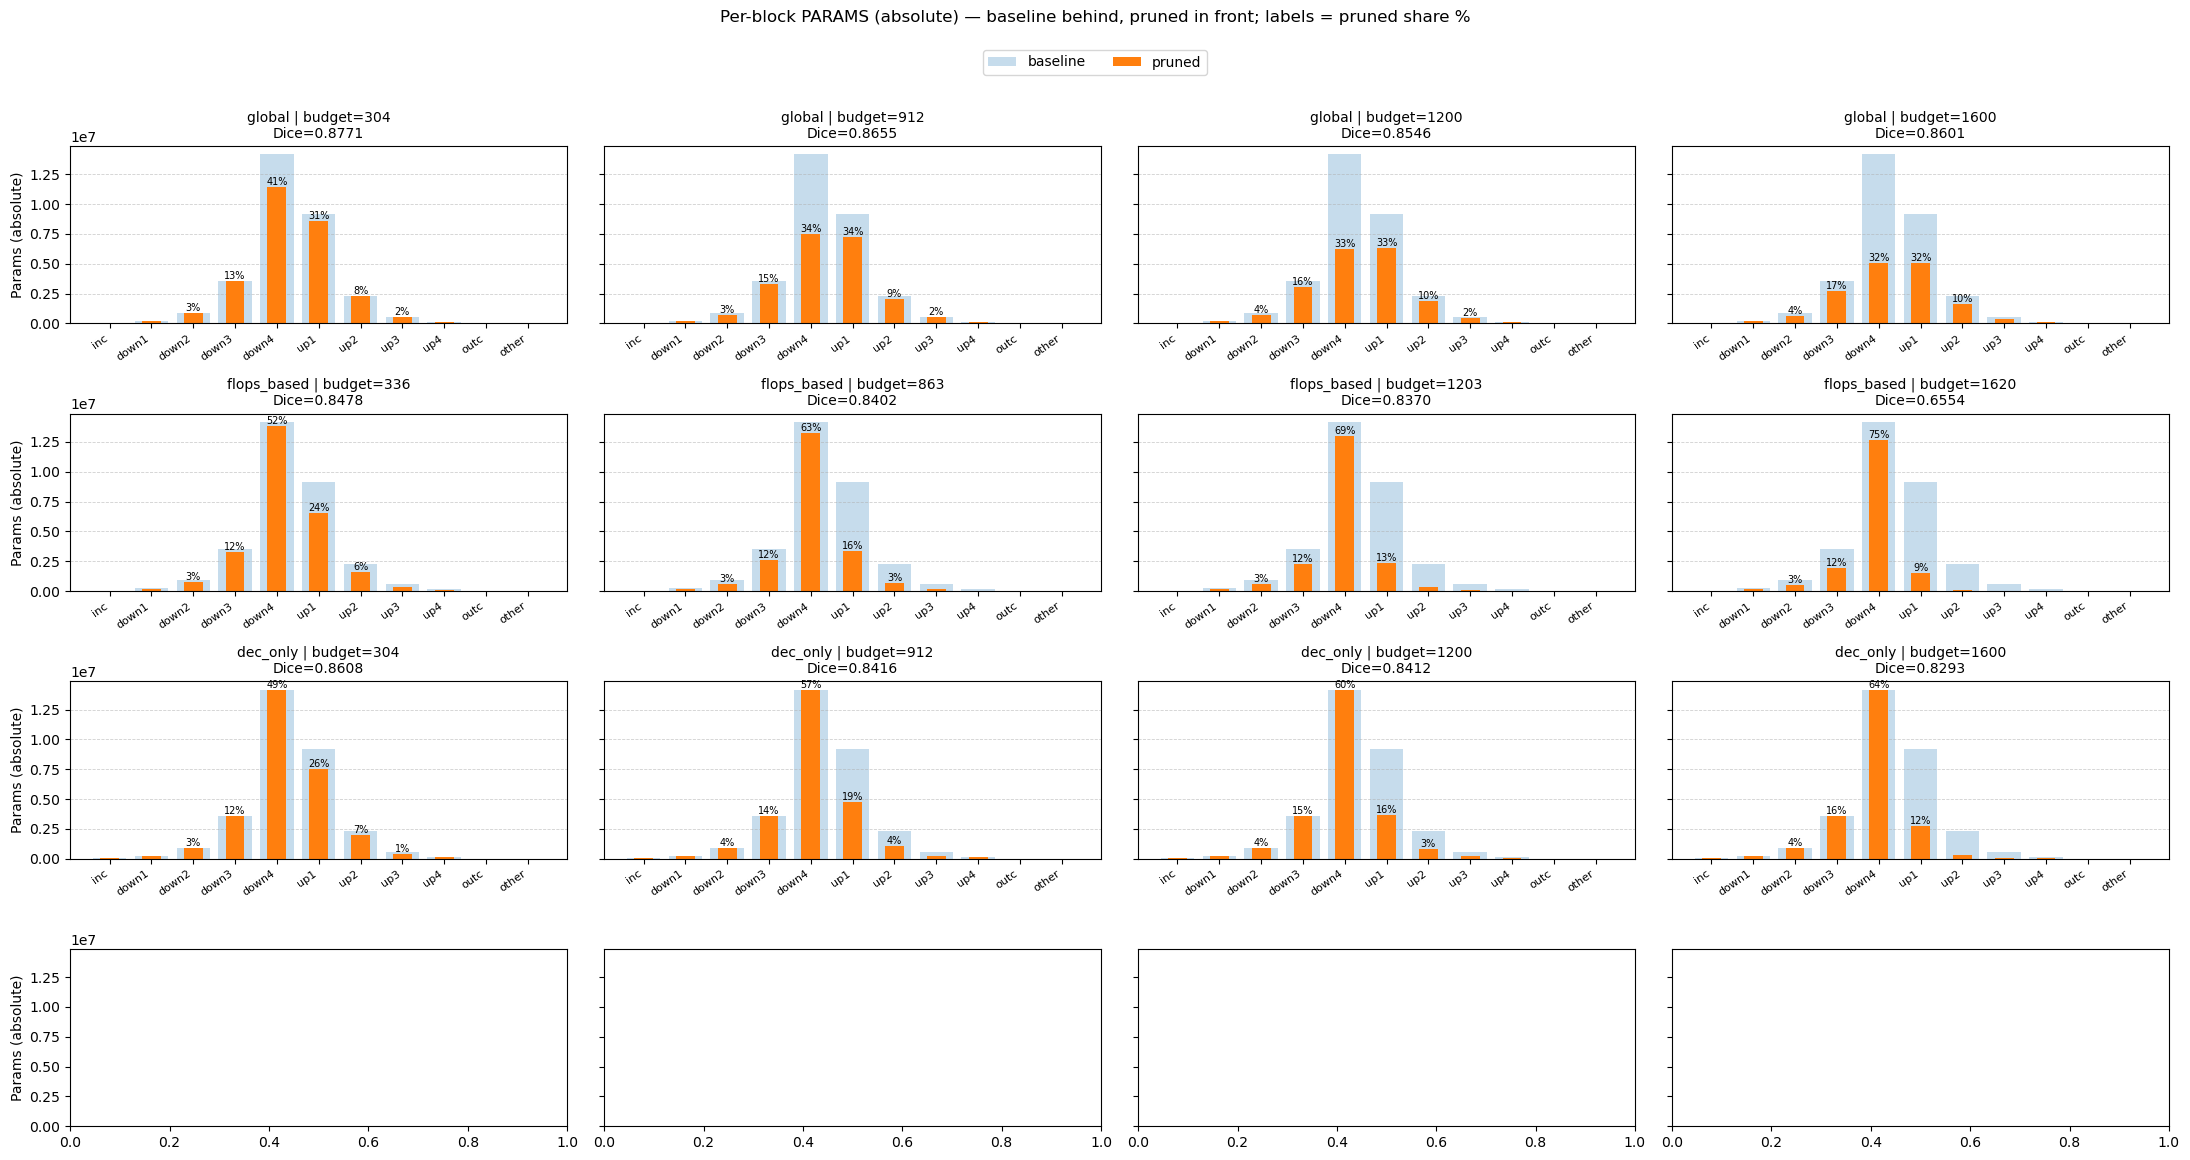

In [44]:
# Cell 2 (REPLACEMENT) — Per-block PARAMS (absolute), label = pruned share %
import numpy as np
import matplotlib.pyplot as plt

PARTS = ["inc","down1","down2","down3","down4","up1","up2","up3","up4","outc","other"]
ORDER_TYPES = ["global", "flops_based", "dec_only"]
COMPARE_BUDGETS = [300, 900, 1200, 1600]

# Baseline per-block params
base_abs = np.array([float(df_baseline.loc[0, f"{p}_params_baseline"]) for p in PARTS], dtype=float)

def pick_row(df: pd.DataFrame, t: str, b: float):
    dd = df[df["experiment_type"] == t].copy()
    if dd.empty:
        return None
    dd["dist"] = (pd.to_numeric(dd["budget_x"], errors="coerce") - b).abs()
    return dd.sort_values(["dist","dice_pruned"], ascending=[True, False]).iloc[0]

x = np.arange(len(PARTS))

fig, axes = plt.subplots(4, 4, figsize=(22, 11), sharey=True)

for i, t in enumerate(ORDER_TYPES):
    for j, b in enumerate(COMPARE_BUDGETS):
        ax = axes[i, j]
        r = pick_row(df_cmp_blocks, t, b)
        if r is None:
            ax.axis("off")
            continue

        pr_abs = np.array([pd.to_numeric(r.get(f"{p}_params_pruned", np.nan), errors="coerce") for p in PARTS], dtype=float)

        # If still NaN (shouldn't), skip
        if np.isnan(pr_abs).all():
            ax.set_title(f"{t} | budget≈{int(b)}\n(pruned per-block missing)")
            ax.axis("off")
            continue

        pr_sum = np.nansum(pr_abs)
        pr_share = (pr_abs / pr_sum * 100.0) if pr_sum > 0 else np.full_like(pr_abs, np.nan)

        # Baseline behind
        ax.bar(x, base_abs, width=0.80, alpha=0.25, label="baseline" if (i==0 and j==0) else None, zorder=1)
        # Pruned in front
        ax.bar(x, pr_abs,  width=0.45, alpha=1.00, label="pruned"   if (i==0 and j==0) else None, zorder=2)

        # Labels: share % on top of pruned bars (only for visible bars to avoid clutter)
        ymax = np.nanmax(base_abs) if np.isfinite(base_abs).any() else 1.0
        thresh = 0.03 * ymax
        for k in range(len(PARTS)):
            if np.isfinite(pr_abs[k]) and pr_abs[k] > thresh and np.isfinite(pr_share[k]):
                ax.text(k, pr_abs[k], f"{pr_share[k]:.0f}%", ha="center", va="bottom", fontsize=7, rotation=0)

        ax.set_xticks(x)
        ax.set_xticklabels(PARTS, rotation=35, ha="right", fontsize=8)
        ax.grid(True, axis="y", linestyle="--", linewidth=0.6, alpha=0.6, zorder=0)

        ax.set_title(f"{t} | budget={int(r['budget_x'])}\nDice={float(r['dice_pruned']):.4f}", fontsize=10)

for r_i in range(4):
    axes[r_i, 0].set_ylabel("Params (absolute)")

handles, labels = axes[0,0].get_legend_handles_labels()
if handles:
    fig.legend(handles, labels, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.02))

plt.suptitle("Per-block PARAMS (absolute) — baseline behind, pruned in front; labels = pruned share %", y=1.05)
plt.tight_layout()
plt.show()


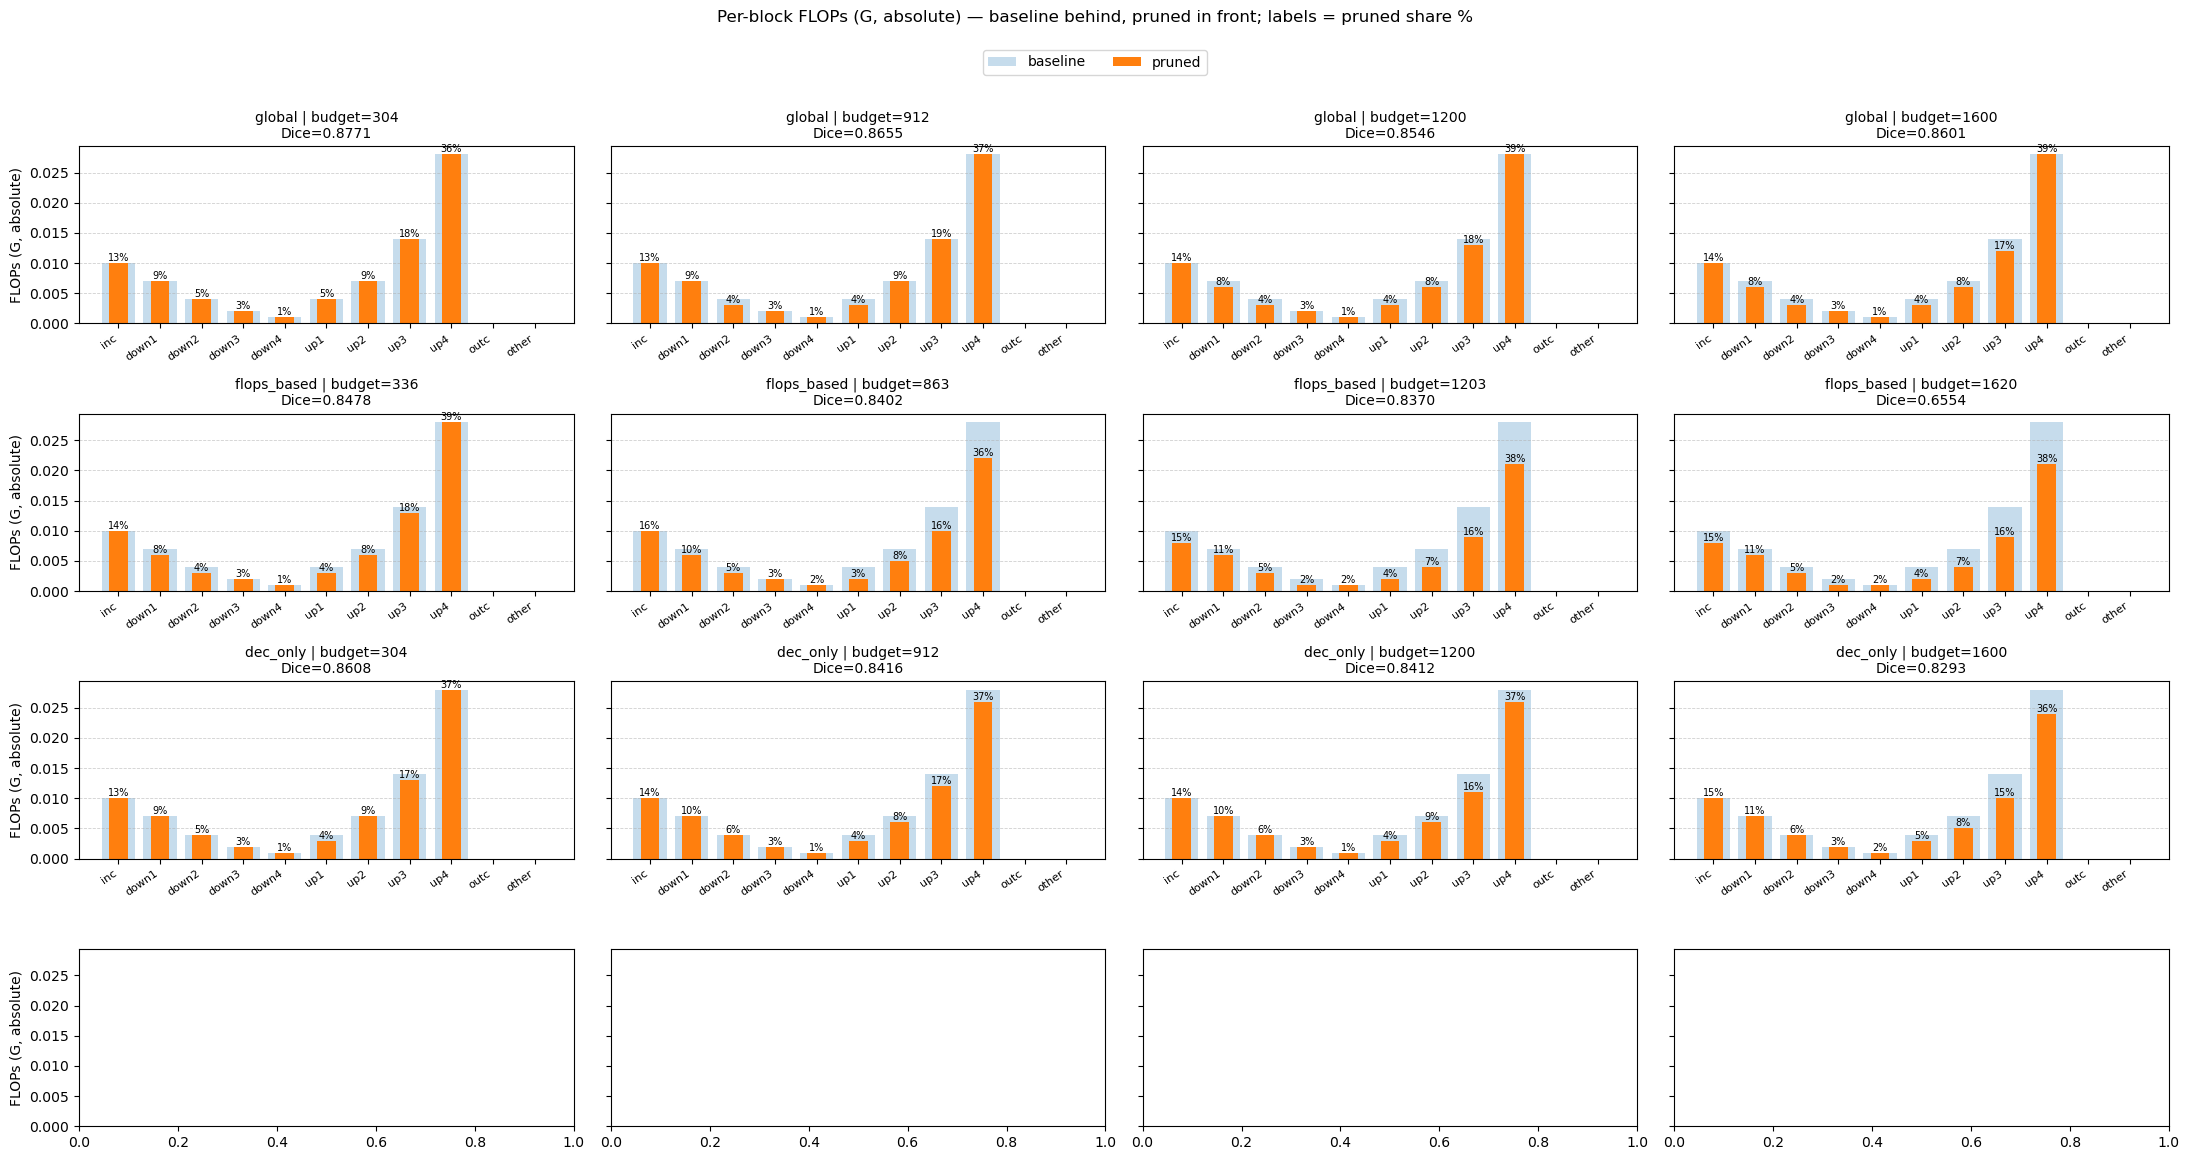

In [46]:
# Cell 3 (REPLACEMENT) — Per-block FLOPs (G), label = pruned share %
import numpy as np
import matplotlib.pyplot as plt

PARTS = ["inc","down1","down2","down3","down4","up1","up2","up3","up4","outc","other"]
ORDER_TYPES = ["global", "flops_based", "dec_only"]
COMPARE_BUDGETS = [300, 900, 1200, 1600]


# Baseline per-block FLOPs in G
base_abs = np.array([float(df_baseline.loc[0, f"{p}_flops_g_baseline"]) for p in PARTS], dtype=float)

def pick_row(df: pd.DataFrame, t: str, b: float):
    dd = df[df["experiment_type"] == t].copy()
    if dd.empty:
        return None
    dd["dist"] = (pd.to_numeric(dd["budget_x"], errors="coerce") - b).abs()
    return dd.sort_values(["dist","dice_pruned"], ascending=[True, False]).iloc[0]

x = np.arange(len(PARTS))

fig, axes = plt.subplots(4, 4, figsize=(22, 11), sharey=True)

for i, t in enumerate(ORDER_TYPES):
    for j, b in enumerate(COMPARE_BUDGETS):
        ax = axes[i, j]
        r = pick_row(df_cmp_blocks, t, b)
        if r is None:
            ax.axis("off")
            continue

        pr_abs = np.array([pd.to_numeric(r.get(f"{p}_flops_g_pruned", np.nan), errors="coerce") for p in PARTS], dtype=float)

        if np.isnan(pr_abs).all():
            ax.set_title(f"{t} | budget≈{int(b)}\n(pruned per-block missing)")
            ax.axis("off")
            continue

        pr_sum = np.nansum(pr_abs)
        pr_share = (pr_abs / pr_sum * 100.0) if pr_sum > 0 else np.full_like(pr_abs, np.nan)

        ax.bar(x, base_abs, width=0.80, alpha=0.25, label="baseline" if (i==0 and j==0) else None, zorder=1)
        ax.bar(x, pr_abs,  width=0.45, alpha=1.00, label="pruned"   if (i==0 and j==0) else None, zorder=2)

        ymax = np.nanmax(base_abs) if np.isfinite(base_abs).any() else 1.0
        thresh = 0.03 * ymax
        for k in range(len(PARTS)):
            if np.isfinite(pr_abs[k]) and pr_abs[k] > thresh and np.isfinite(pr_share[k]):
                ax.text(k, pr_abs[k], f"{pr_share[k]:.0f}%", ha="center", va="bottom", fontsize=7)

        ax.set_xticks(x)
        ax.set_xticklabels(PARTS, rotation=35, ha="right", fontsize=8)
        ax.grid(True, axis="y", linestyle="--", linewidth=0.6, alpha=0.6, zorder=0)

        ax.set_title(f"{t} | budget={int(r['budget_x'])}\nDice={float(r['dice_pruned']):.4f}", fontsize=10)

for r_i in range(4):
    axes[r_i, 0].set_ylabel("FLOPs (G, absolute)")

handles, labels = axes[0,0].get_legend_handles_labels()
if handles:
    fig.legend(handles, labels, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.02))

plt.suptitle("Per-block FLOPs (G, absolute) — baseline behind, pruned in front; labels = pruned share %", y=1.05)
plt.tight_layout()
plt.show()


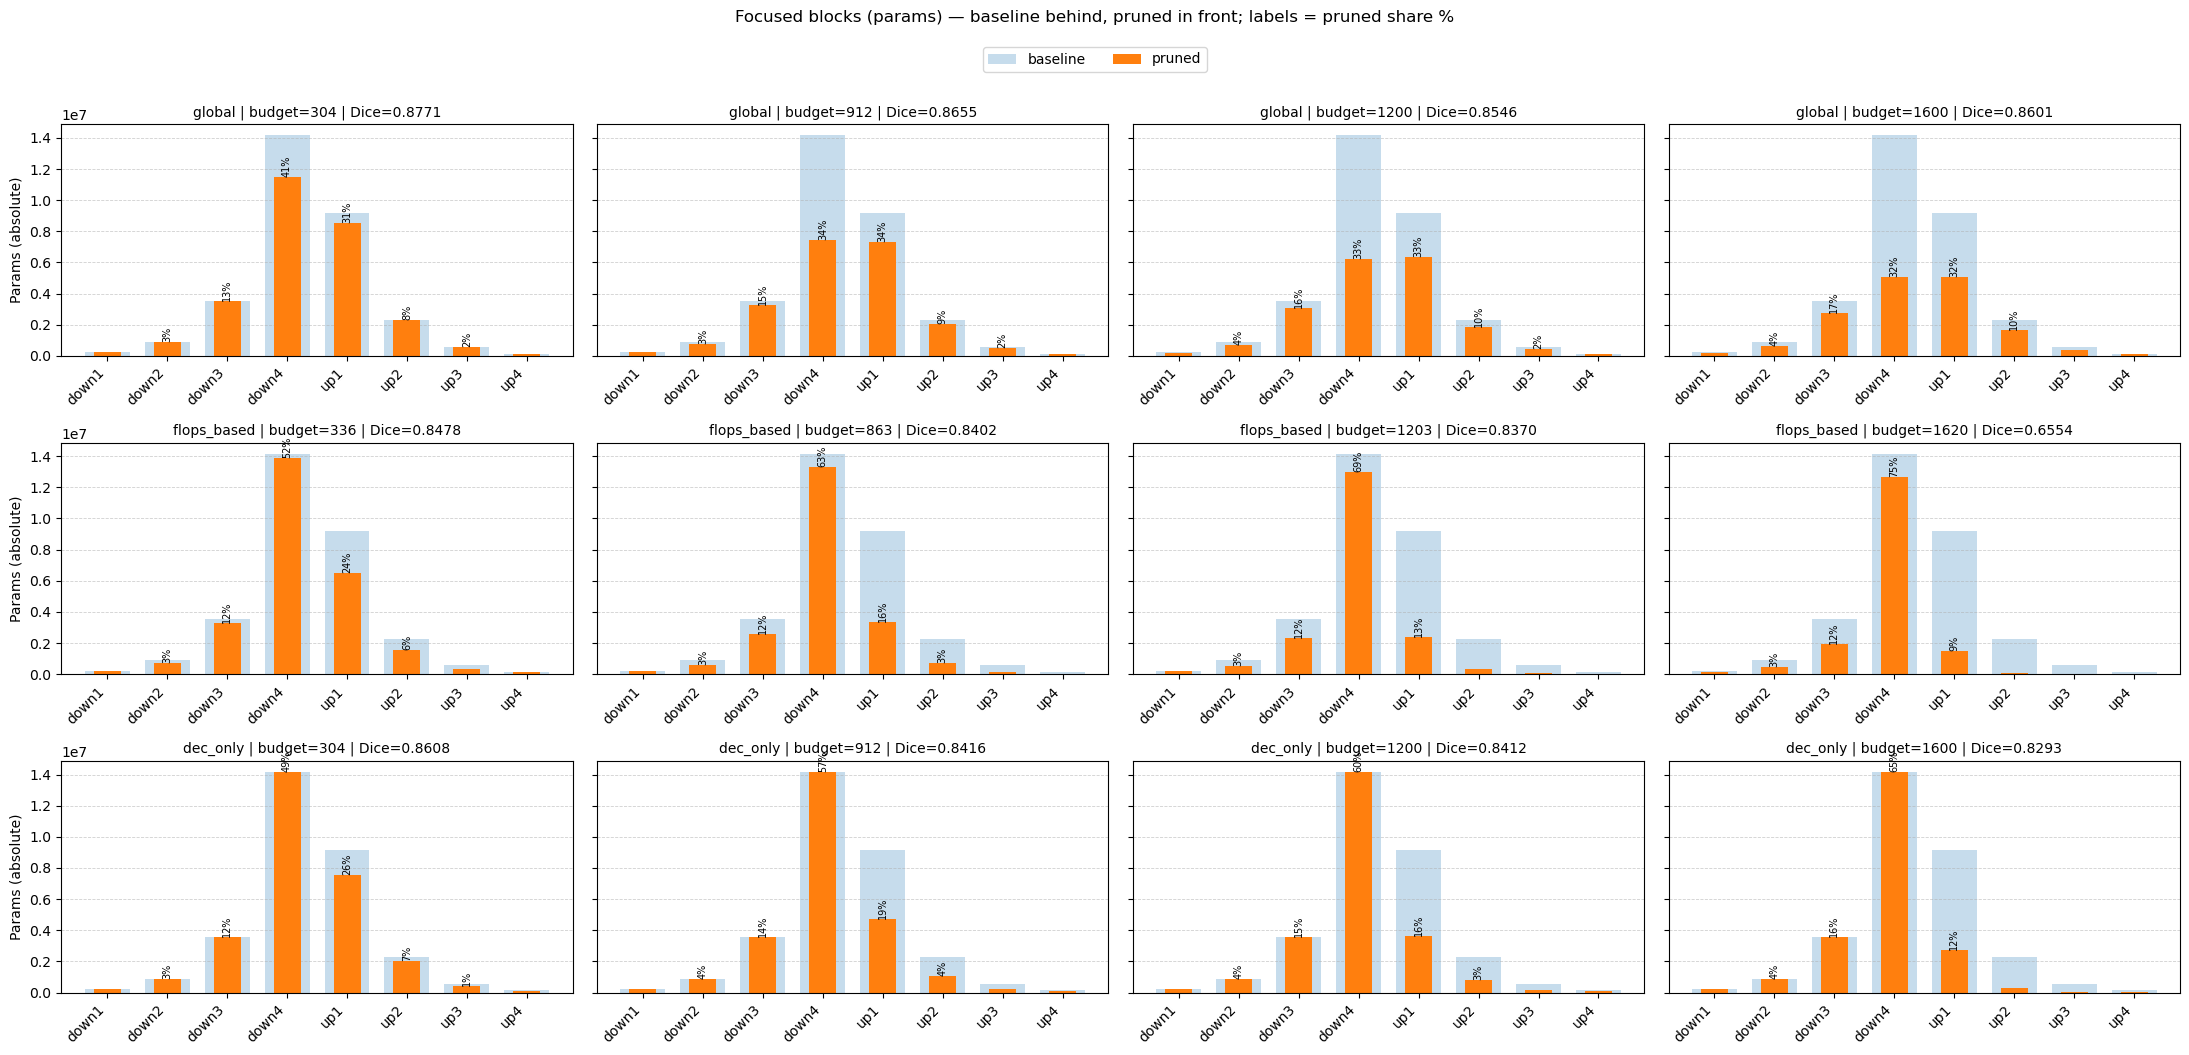

In [47]:
# Cell 4 (FIXED) — Focused view on blocks: baseline behind, pruned in front (absolute)
# Uses df_cmp_blocks (NOT df_cmp). Also makes budget_x numeric and robust.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

KEEP_PARTS = ["down1","down2","down3","down4","up1","up2","up3","up4"]  # adjust
ORDER_TYPES = ["global", "flops_based", "dec_only"]
COMPARE_BUDGETS = [300, 900, 1200, 1600]

# ---- pick correct source (must be the per-block selection) ----
if "df_cmp_blocks" not in globals():
    raise RuntimeError("df_cmp_blocks not found. Run the 'Cell 1 (REPLACEMENT) — Select 16 rows WITH per-block cols' first.")

src = df_cmp_blocks.copy()
src["budget_x"] = pd.to_numeric(src["budget_x"], errors="coerce")

# Sanity: ensure needed columns exist
missing = [f"{p}_params_pruned" for p in KEEP_PARTS if f"{p}_params_pruned" not in src.columns]
if missing:
    raise RuntimeError(f"Missing per-block params_pruned columns in df_cmp_blocks: {missing}")

def _pick_row(df: pd.DataFrame, t: str, target_budget: float):
    dd = df[df["experiment_type"] == t].copy()
    dd = dd.dropna(subset=["budget_x"])
    if dd.empty:
        return None
    dd["dist"] = (dd["budget_x"] - target_budget).abs()
    # tie-break: higher dice
    if "dice_pruned" in dd.columns:
        dd = dd.sort_values(["dist", "dice_pruned"], ascending=[True, False])
    else:
        dd = dd.sort_values(["dist"], ascending=[True])
    return dd.iloc[0]

# Baseline absolute params for these blocks
base_abs = np.array([float(df_baseline.loc[0, f"{p}_params_baseline"]) for p in KEEP_PARTS], dtype=float)
x = np.arange(len(KEEP_PARTS))

fig, axes = plt.subplots(len(ORDER_TYPES), len(COMPARE_BUDGETS), figsize=(22, 10), sharey=True)

for i, t in enumerate(ORDER_TYPES):
    for j, b in enumerate(COMPARE_BUDGETS):
        ax = axes[i, j]

        r = _pick_row(src, t, b)
        if r is None:
            ax.axis("off")
            continue

        pr_abs = np.array([pd.to_numeric(r.get(f"{p}_params_pruned", np.nan), errors="coerce") for p in KEEP_PARTS], dtype=float)

        # If still all NaN, hide panel
        if np.isnan(pr_abs).all():
            ax.set_title(f"{t} | target={b}\n(per-block missing)")
            ax.axis("off")
            continue

        pr_total = np.nansum(pr_abs)
        pr_share = (pr_abs / pr_total * 100.0) if pr_total > 0 else np.full_like(pr_abs, np.nan)

        # baseline behind + pruned in front
        ax.bar(x, base_abs, width=0.75, alpha=0.25, label="baseline" if (i==0 and j==0) else None, zorder=1)
        ax.bar(x, pr_abs,   width=0.45, alpha=1.00, label="pruned"   if (i==0 and j==0) else None, zorder=2)

        ax.set_xticks(x)
        ax.set_xticklabels(KEEP_PARTS, rotation=45, ha="right")
        ax.grid(True, axis="y", linestyle="--", linewidth=0.6, alpha=0.6, zorder=0)

        # label share % on top of pruned bars (avoid clutter on tiny bars)
        ymax = np.nanmax(base_abs) if np.isfinite(base_abs).any() else 1.0
        thresh = 0.03 * ymax
        for k in range(len(KEEP_PARTS)):
            if np.isfinite(pr_abs[k]) and pr_abs[k] > thresh and np.isfinite(pr_share[k]):
                ax.text(k, pr_abs[k], f"{pr_share[k]:.0f}%", ha="center", va="bottom", fontsize=7, rotation=90)

        ax.set_title(f"{t} | budget={int(r['budget_x'])} | Dice={float(r.get('dice_pruned', np.nan)):.4f}", fontsize=10)

for r_i in range(len(ORDER_TYPES)):
    axes[r_i, 0].set_ylabel("Params (absolute)")

handles, labels = axes[0, 0].get_legend_handles_labels()
if handles:
    fig.legend(handles, labels, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.02))

plt.suptitle("Focused blocks (params) — baseline behind, pruned in front; labels = pruned share %", y=1.05)
plt.tight_layout()
plt.show()


## Time Analysis

In [49]:
# Cell A — Imports + config (matches your prune.py setup)

from pathlib import Path
import re
import time
import numpy as np
import pandas as pd
import torch

# ====== device ======
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# ====== model / input shape ======
# Your prune.py builds: UNet(n_channels=3, n_classes=2, f_channels=...)
N_CHANNELS = 3
N_CLASSES  = 2

# Use the SAME spatial size for all models (representative inference)
BATCH_SIZE = 1
H, W = 128, 128              # <-- set to your target inference size
DTYPE = torch.float32

# ====== timing options ======
USE_AMP = (DEVICE == "cuda")  # only affects inference timing
CHANNELS_LAST = (DEVICE == "cuda")  # safe to enable on CUDA

WARMUP = 30
RUNS   = 200

# Optional: make GPU timings less noisy (speed-optimized)
if DEVICE == "cuda":
    torch.backends.cudnn.benchmark = True  # OK for timing, not for deterministic training


In [50]:
# Cell B — Build the 16-row selection table + locate finetuned checkpoint next to each log.txt

if "df_cmp_blocks" not in globals():
    raise RuntimeError("df_cmp_blocks not found. Run your 16-sample selection cell first.")

sel = df_cmp_blocks.copy()

# Ensure we have a log_path + budget_x (for reporting)
if "log_path" not in sel.columns:
    raise RuntimeError("df_cmp_blocks has no log_path column.")
sel["run_dir"] = sel["log_path"].apply(lambda p: str(Path(p).resolve().parent))
sel["run_dir"] = sel["run_dir"].apply(lambda p: str(Path(p)))

def find_finetuned_ckpt(run_dir: str):
    d = Path(run_dir)
    if not d.exists():
        return None

    # First try exact names (adapt if your repo uses another convention)
    for name in ["finetuned.pth", "finetuned_model.pth", "model_finetuned.pth", "checkpoint_finetuned.pth"]:
        p = d / name
        if p.exists():
            return str(p)

    # Otherwise, search for something containing "finetuned"
    cands = list(d.glob("*.pth")) + list(d.glob("*.pt"))
    cands = [p for p in cands if re.search(r"finetuned", p.name, flags=re.IGNORECASE)]
    if cands:
        # Prefer the largest file (often the real checkpoint vs small metadata)
        cands = sorted(cands, key=lambda p: p.stat().st_size, reverse=True)
        return str(cands[0])

    # Fallback: if nothing says finetuned, try common "best" names
    for name in ["best.pth", "best_model.pth", "checkpoint.pth", "model.pth"]:
        p = d / name
        if p.exists():
            return str(p)

    return None

sel["finetuned_ckpt"] = sel["run_dir"].apply(find_finetuned_ckpt)

print("Found finetuned ckpt:", sel["finetuned_ckpt"].notna().sum(), "/", len(sel))
display(sel[["experiment_type","budget_x","model_name","run_dir","finetuned_ckpt","dice_pruned"]])


Found finetuned ckpt: 12 / 12


,experiment_type,budget_x,model_name,run_dir,finetuned_ckpt,dice_pruned
0,global,304,global_b0,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...,0.877079
1,global,912,global_b0,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...,0.865532
2,global,1200,global_b0,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...,0.854621
3,global,1600,global_b0,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...,0.860057
4,flops_based,336,flops_based_b0,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...,0.847803
5,flops_based,863,flops_based_b0,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...,0.840186
6,flops_based,1203,flops_based_b0,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...,0.837021
7,flops_based,1620,flops_based_b0,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...,0.655367
8,dec_only,304,dec_only_d300,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...,0.860830
9,dec_only,912,dec_only_d900,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...,0.841585


In [51]:
# Cell C (adjusted) — Import UNet from your local Prune_U-Net repo (next to the notebook)

import sys
from pathlib import Path

# Notebook is next to folder "Prune_U-Net/"
ROOT = Path(".").resolve()
PRUNE_UNET_DIR = ROOT / "../../Prune_U-Net"

# Add Prune_U-Net to python path so "from unet import UNet" works
if str(PRUNE_UNET_DIR) not in sys.path:
    sys.path.insert(0, str(PRUNE_UNET_DIR))

# Optional sanity prints
print("Using Prune_U-Net dir:", PRUNE_UNET_DIR)
print("Exists:", PRUNE_UNET_DIR.exists())

from unet import UNet  # comes from Prune_U-Net/unet/

def build_model_for_checkpoint(channel_txt_path: str | None = None) -> torch.nn.Module:
    """
    Builds the SAME architecture as prune.py expects for finetuned checkpoints.
    - n_channels=3
    - n_classes=2
    - f_channels = path to pruned_channels.txt (or None for baseline shape)
    """
    return UNet(
        n_channels=N_CHANNELS,
        n_classes=N_CLASSES,
        f_channels=channel_txt_path if channel_txt_path else None,
    )


Using Prune_U-Net dir: /home/jovyan/pruning-datavol-1/Prune_U-Net/analysis/../../Prune_U-Net
Exists: True


In [52]:
# Cell D — Robust checkpoint loader (handles different dict formats)

def load_finetuned_model(ckpt_path: str, device: str = DEVICE) -> torch.nn.Module:
    model = build_model_for_checkpoint()

    obj = torch.load(ckpt_path, map_location="cpu")

    # common formats
    if isinstance(obj, dict):
        if "state_dict" in obj and isinstance(obj["state_dict"], dict):
            sd = obj["state_dict"]
        elif "model_state_dict" in obj and isinstance(obj["model_state_dict"], dict):
            sd = obj["model_state_dict"]
        elif all(isinstance(k, str) for k in obj.keys()) and any(k.startswith("module.") for k in obj.keys()):
            sd = obj
        elif all(isinstance(k, str) for k in obj.keys()) and any(k.endswith(".weight") for k in obj.keys()):
            sd = obj
        else:
            # last resort: try the largest dict-like entry
            dict_candidates = [(k, v) for k, v in obj.items() if isinstance(v, dict)]
            sd = dict_candidates[0][1] if dict_candidates else None
    else:
        sd = None

    if sd is None:
        raise RuntimeError(f"Unrecognized checkpoint format: {ckpt_path}")

    # strip "module." if saved from DDP
    if any(k.startswith("module.") for k in sd.keys()):
        sd = {k.replace("module.", "", 1): v for k, v in sd.items()}

    missing, unexpected = model.load_state_dict(sd, strict=False)
    if missing or unexpected:
        print(f"[WARN] {Path(ckpt_path).name} missing={len(missing)} unexpected={len(unexpected)}")

    model.eval().to(device)
    return model


In [53]:
# Cell E — Timing utilities (CUDA events on GPU; perf_counter on CPU)

@torch.inference_mode()
def measure_forward_latency_ms(
    model: torch.nn.Module,
    x: torch.Tensor,
    device: str = DEVICE,
    warmup: int = 20,
    runs: int = 100,
    use_amp: bool = USE_AMP,
) -> float:
    assert x.device.type == ("cuda" if device == "cuda" else "cpu")

    # warmup
    for _ in range(warmup):
        if device == "cuda" and use_amp:
            with torch.autocast(device_type="cuda", dtype=torch.float16):
                _ = model(x)
        else:
            _ = model(x)

    if device == "cuda":
        torch.cuda.synchronize()
        starter = torch.cuda.Event(enable_timing=True)
        ender   = torch.cuda.Event(enable_timing=True)

        times = []
        for _ in range(runs):
            starter.record()
            if use_amp:
                with torch.autocast(device_type="cuda", dtype=torch.float16):
                    _ = model(x)
            else:
                _ = model(x)
            ender.record()
            torch.cuda.synchronize()
            times.append(starter.elapsed_time(ender))  # milliseconds
        return float(np.median(times))

    else:
        # CPU timing
        times = []
        for _ in range(runs):
            t0 = time.perf_counter()
            _ = model(x)
            t1 = time.perf_counter()
            times.append((t1 - t0) * 1000.0)
        return float(np.median(times))


In [56]:
# Cell F (REPLACEMENT) — Latency benchmark for the 16 selected models (FIXED dtype)
import os
import time
import numpy as np
import pandas as pd
from pathlib import Path

import torch

# ---------------------------
# Config
# ---------------------------
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

IMG_SIZE = 128        # set to the size you use at inference
BATCH_SIZE = 1

WARMUP = 30
RUNS   = 100

# If True: convert model+inputs to FP16 on CUDA (faster but different numerics)
USE_FP16 = False

DTYPE = (torch.float16 if (USE_FP16 and DEVICE == "cuda") else torch.float32)

# selected comparison rows
if "df_cmp" not in globals() or df_cmp is None or df_cmp.empty:
    raise RuntimeError("df_cmp not found/empty. Re-run the selection cell that builds df_cmp (16 rows).")

sel = df_cmp.copy()

# ---------------------------
# Helpers: path resolution
# ---------------------------
def _run_dir_from_log_path(log_path: str) -> Path:
    p = Path(str(log_path))
    if p.is_dir():
        return p
    if p.name.lower() == "log.txt":
        return p.parent
    return p.parent

def _find_ckpt_and_channels(run_dir: Path) -> tuple[Path, Path | None]:
    # checkpoint
    cands = []
    for name in ["Finetuned.pth", "finetuned.pth"]:
        p = run_dir / name
        if p.exists():
            cands.append(p)

    if not cands:
        for p in run_dir.glob("*.pth"):
            if "finetuned" in p.name.lower():
                cands.append(p)

    if not cands:
        raise FileNotFoundError(f"No finetuned checkpoint found in: {run_dir}")

    ckpt = sorted(cands, key=lambda p: p.name.lower())[0]

    ch = run_dir / "pruned_channels.txt"
    ch = ch if ch.exists() else None
    return ckpt, ch

# ---------------------------
# Model loader (expects Cell C already defines build_model_for_checkpoint)
# ---------------------------
def _safe_torch_load_state_dict(path: str):
    # Prefer weights_only=True when available (PyTorch 2.0+)
    try:
        return torch.load(path, map_location=DEVICE, weights_only=True)
    except TypeError:
        # older torch
        return torch.load(path, map_location=DEVICE)

def _load_model(ckpt_path: Path, channel_txt_path: Path | None) -> torch.nn.Module:
    m = build_model_for_checkpoint(str(channel_txt_path) if channel_txt_path else None)
    m.to(DEVICE)
    sd = _safe_torch_load_state_dict(str(ckpt_path))
    m.load_state_dict(sd, strict=True)
    m.eval()

    # channels-last can help conv throughput
    if DEVICE == "cuda":
        m = m.to(memory_format=torch.channels_last)

    # OPTIONAL: FP16 benchmark (must convert weights too)
    if USE_FP16 and DEVICE == "cuda":
        m = m.half()

    return m

# ---------------------------
# Latency benchmark
# ---------------------------
@torch.no_grad()
def measure_latency_ms(model: torch.nn.Module, img_size: int, runs: int, warmup: int) -> dict:
    x = torch.randn(BATCH_SIZE, 3, img_size, img_size, device=DEVICE, dtype=DTYPE)
    if DEVICE == "cuda":
        x = x.to(memory_format=torch.channels_last)

    # warmup
    for _ in range(warmup):
        _ = model(x)
    if DEVICE == "cuda":
        torch.cuda.synchronize()

    times = []
    for _ in range(runs):
        if DEVICE == "cuda":
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        _ = model(x)
        if DEVICE == "cuda":
            torch.cuda.synchronize()
        t1 = time.perf_counter()
        times.append((t1 - t0) * 1000.0)

    arr = np.array(times, dtype=np.float64)
    return {
        "lat_ms_mean": float(arr.mean()),
        "lat_ms_p50":  float(np.percentile(arr, 50)),
        "lat_ms_p90":  float(np.percentile(arr, 90)),
        "lat_ms_p95":  float(np.percentile(arr, 95)),
        "lat_ms_min":  float(arr.min()),
        "lat_ms_max":  float(arr.max()),
    }

# ---------------------------
# Run all selected models
# ---------------------------
results = []
fail = []

for _, r in sel.iterrows():
    exp_type  = r.get("experiment_type", "")
    budget_x  = r.get("budget_x", np.nan)
    model_name = r.get("model_name", "")
    log_path  = r.get("log_path", "")

    try:
        run_dir = _run_dir_from_log_path(log_path)
        ckpt_path, ch_path = _find_ckpt_and_channels(run_dir)

        model = _load_model(ckpt_path, ch_path)
        lat = measure_latency_ms(model, IMG_SIZE, runs=RUNS, warmup=WARMUP)

        results.append({
            "experiment_type": exp_type,
            "budget_x": float(budget_x) if pd.notna(budget_x) else np.nan,
            "model_name": model_name,
            "run_dir": str(run_dir),
            "ckpt_path": str(ckpt_path),
            "channels_path": str(ch_path) if ch_path else "",
            "img_size": IMG_SIZE,
            "device": DEVICE,
            "dtype": str(DTYPE).replace("torch.", ""),
            **lat,
        })

    except Exception as e:
        fail.append((model_name, str(log_path), repr(e)))

    finally:
        try:
            del model
        except Exception:
            pass
        if DEVICE == "cuda":
            torch.cuda.empty_cache()

df_latency = pd.DataFrame(results)

print("Benchmarked:", len(df_latency), "/", len(sel))
if fail:
    print("\nFailures:", len(fail))
    for x in fail[:12]:
        print(" -", x)

if not df_latency.empty:
    df_latency = df_latency.sort_values(["experiment_type", "budget_x"]).reset_index(drop=True)

display(df_latency)


Benchmarked: 8 / 8


,experiment_type,budget_x,model_name,run_dir,ckpt_path,channels_path,img_size,device,dtype,lat_ms_mean,lat_ms_p50,lat_ms_p90,lat_ms_p95,lat_ms_min,lat_ms_max
0,flops_based,336.0,flops_based_b0,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,128,cuda,float32,2.939515,2.938785,2.944917,2.950095,2.927906,2.975252
1,flops_based,863.0,flops_based_b0,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,128,cuda,float32,2.500907,2.501096,2.505781,2.507582,2.492975,2.514454
2,flops_based,1620.0,flops_based_b0,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,128,cuda,float32,2.241894,2.119637,2.125849,2.255015,2.112735,4.857163
3,flops_based,1620.0,flops_based_b0,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,128,cuda,float32,4.497949,4.489481,5.067546,6.913074,2.124845,6.951960
4,global,304.0,global_b0,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,128,cuda,float32,7.690035,7.983559,7.992272,7.995028,3.511879,8.057830
5,global,912.0,global_b0,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,128,cuda,float32,7.519629,7.723537,7.737579,7.740150,3.381814,7.748799
6,global,1600.0,global_b0,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,128,cuda,float32,3.628490,2.962356,7.459377,7.475476,2.662826,7.495281
7,global,3008.0,global_b0,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,128,cuda,float32,2.422725,2.244484,2.864729,2.872801,2.231515,5.086781


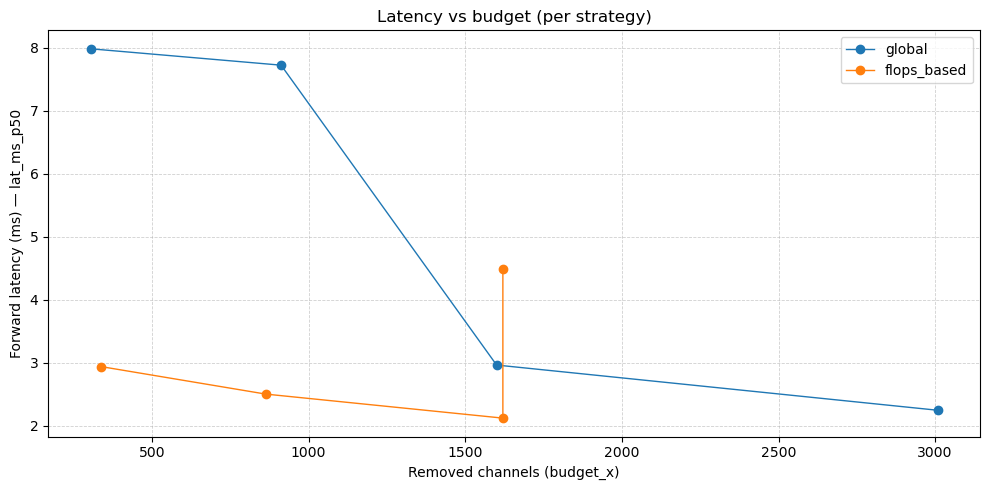

,experiment_type,budget_x,model_name,lat_ms_p50,lat_ms_mean,lat_ms_p90,lat_ms_p95,run_dir
0,flops_based,336.0,flops_based_b0,2.938785,2.939515,2.944917,2.950095,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
1,flops_based,863.0,flops_based_b0,2.501096,2.500907,2.505781,2.507582,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
2,flops_based,1620.0,flops_based_b0,2.119637,2.241894,2.125849,2.255015,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
3,flops_based,1620.0,flops_based_b0,4.489481,4.497949,5.067546,6.913074,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
4,global,304.0,global_b0,7.983559,7.690035,7.992272,7.995028,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
5,global,912.0,global_b0,7.723537,7.519629,7.737579,7.740150,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
6,global,1600.0,global_b0,2.962356,3.628490,7.459377,7.475476,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
7,global,3008.0,global_b0,2.244484,2.422725,2.864729,2.872801,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...


In [57]:
# Cell G (REPLACEMENT) — Plot latency vs budget (median = p50) per experiment_type
import matplotlib.pyplot as plt

if "df_latency" not in globals() or df_latency is None or df_latency.empty:
    raise RuntimeError("df_latency not found/empty. Run the benchmark cell first (Cell F).")

types = ["global", "flops_based", "dec_only"]

# choose the best available "median" column
if "lat_ms_p50" in df_latency.columns:
    y_med = "lat_ms_p50"
elif "latency_ms_median" in df_latency.columns:
    y_med = "latency_ms_median"
elif "lat_ms_mean" in df_latency.columns:
    y_med = "lat_ms_mean"  # fallback
else:
    raise RuntimeError(f"No usable latency column found. Available: {list(df_latency.columns)}")

plt.figure(figsize=(10, 5))

for t in types:
    d = df_latency[df_latency["experiment_type"] == t].sort_values("budget_x")
    if d.empty:
        continue
    plt.plot(d["budget_x"], d[y_med], marker="o", linewidth=1, label=t)

plt.xlabel("Removed channels (budget_x)")
plt.ylabel(f"Forward latency (ms) — {y_med}")
plt.title("Latency vs budget (per strategy)")
plt.grid(True, linestyle="--", linewidth=0.6, alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

# Optional: show a compact table
show_cols = ["experiment_type", "budget_x", "model_name"]
for c in ["lat_ms_p50", "lat_ms_mean", "lat_ms_p90", "lat_ms_p95", "run_dir"]:
    if c in df_latency.columns:
        show_cols.append(c)

display(df_latency[show_cols].sort_values(["experiment_type", "budget_x"]).reset_index(drop=True))


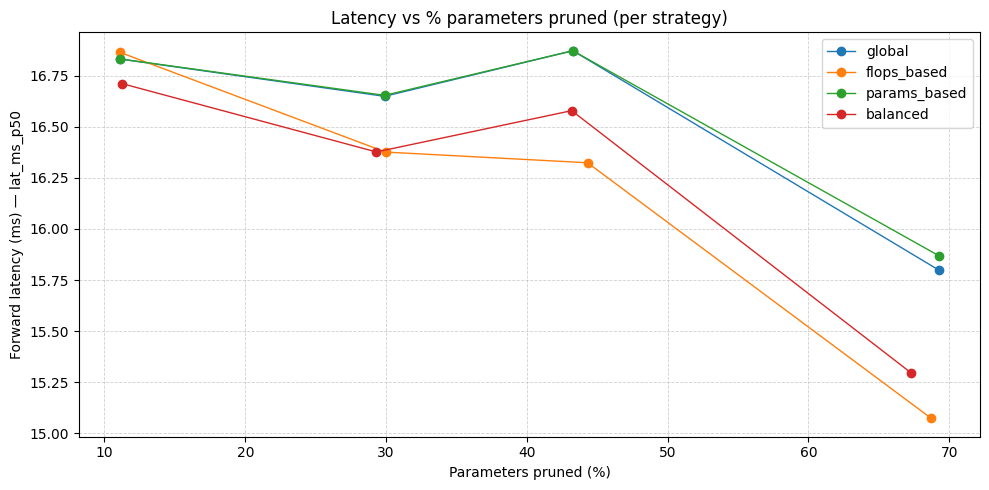

,experiment_type,budget_x,model_name,params_pruned_pct_x,lat_ms_p50,params_pruned,params_reduction_pct,params_keep_pct
0,balanced,304.0,balanced_b300,11.255693,16.710641,27544190,11.255693,88.74
1,balanced,912.0,balanced_b900,29.311362,16.376596,21940126,29.311362,70.69
2,balanced,1504.0,balanced_b1500,43.185584,16.578507,17633887,43.185584,56.81
3,balanced,2912.0,balanced_b2900,67.308246,15.295099,10146768,67.308246,32.69
4,flops_based,304.0,flops_b300,11.104055,16.863585,27591255,11.104055,88.90
5,flops_based,912.0,flops_b900,29.966939,16.375993,21736650,29.966939,70.03
6,flops_based,1504.0,flops_b1500,44.311469,16.323712,17284438,44.311469,55.69
7,flops_based,2912.0,flops_b2900,68.721601,15.073743,9708095,68.721601,31.28
8,global,304.0,global_b300,11.115786,16.830814,27587614,11.115786,88.88
9,global,912.0,global_b900,29.898835,16.648623,21757788,29.898835,70.10


In [268]:
# Cell (REPLACEMENT) — Latency vs % params pruned
# Works even if df_latency doesn't contain params columns:
# it merges them from df_cmp (or df_runs) using log_path / model_name as key.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- guards
if "df_latency" not in globals() or df_latency is None or df_latency.empty:
    raise RuntimeError("df_latency is empty. Run the benchmark cell first.")

if "df_baseline" not in globals() or df_baseline is None or df_baseline.empty:
    raise RuntimeError("df_baseline is missing/empty (needed for baseline params).")

base_params = float(df_baseline.loc[0, "params_baseline"])
if not np.isfinite(base_params) or base_params <= 0:
    raise RuntimeError(f"Invalid baseline params: {base_params}")

# ---- pick latency column (robust)
lat_candidates = ["lat_ms_p50", "latency_ms_median", "lat_ms_mean", "latency_ms_mean"]
y_col = next((c for c in lat_candidates if c in df_latency.columns), None)
if y_col is None:
    raise RuntimeError(f"No latency column found in df_latency. Available: {list(df_latency.columns)}")

d = df_latency.copy()

# ---- attach params info if missing
need_any = ("params_pruned" in d.columns and d["params_pruned"].notna().any()) or \
           ("params_reduction_pct" in d.columns and d["params_reduction_pct"].notna().any()) or \
           ("params_keep_pct" in d.columns and d["params_keep_pct"].notna().any())

if not need_any:
    # try merge from df_cmp first (best: exactly the 16 selected)
    merged = False

    if "df_cmp" in globals() and df_cmp is not None and not df_cmp.empty:
        key = "log_path" if ("log_path" in d.columns and "log_path" in df_cmp.columns) else None
        if key is None and ("model_name" in d.columns and "model_name" in df_cmp.columns):
            key = "model_name"

        if key is not None:
            cols_take = [key] + [c for c in ["params_pruned", "params_reduction_pct", "params_keep_pct", "params_baseline"] if c in df_cmp.columns]
            right = df_cmp[cols_take].drop_duplicates(key)
            d = d.merge(right, on=key, how="left", suffixes=("", "_src"))
            merged = True

    # fallback: merge from df_runs (all runs)
    if not merged and "df_runs" in globals() and df_runs is not None and not df_runs.empty:
        key = "log_path" if ("log_path" in d.columns and "log_path" in df_runs.columns) else None
        if key is None and ("model_name" in d.columns and "model_name" in df_runs.columns):
            key = "model_name"

        if key is None:
            raise RuntimeError("Cannot merge params into df_latency (no common key: log_path or model_name).")

        cols_take = [key] + [c for c in ["params_pruned", "params_reduction_pct", "params_keep_pct", "params_baseline"] if c in df_runs.columns]
        right = df_runs[cols_take].drop_duplicates(key)
        d = d.merge(right, on=key, how="left", suffixes=("", "_src"))

# ---- compute x = % params pruned
if "params_reduction_pct" in d.columns and d["params_reduction_pct"].notna().any():
    d["params_pruned_pct_x"] = pd.to_numeric(d["params_reduction_pct"], errors="coerce")
elif "params_keep_pct" in d.columns and d["params_keep_pct"].notna().any():
    d["params_pruned_pct_x"] = 100.0 - pd.to_numeric(d["params_keep_pct"], errors="coerce")
elif "params_pruned" in d.columns and d["params_pruned"].notna().any():
    d["params_pruned_pct_x"] = (1.0 - (pd.to_numeric(d["params_pruned"], errors="coerce") / base_params)) * 100.0
else:
    print("df_latency columns:", list(df_latency.columns))
    print("After merge columns:", list(d.columns))
    raise RuntimeError(
        "Still missing params info. Need one of: params_reduction_pct, params_keep_pct, params_pruned "
        "(either in df_latency or via merge from df_cmp/df_runs)."
    )

# clamp sane range
d["params_pruned_pct_x"] = d["params_pruned_pct_x"].clip(lower=0, upper=100)

# ---- plot
types = ["global", "flops_based", "params_based", "balanced"]

plt.figure(figsize=(10, 5))
for t in types:
    dt = d[d["experiment_type"] == t].dropna(subset=["params_pruned_pct_x", y_col]).sort_values("params_pruned_pct_x")
    if dt.empty:
        continue
    plt.plot(dt["params_pruned_pct_x"], dt[y_col], marker="o", linewidth=1, label=t)

plt.xlabel("Parameters pruned (%)")
plt.ylabel(f"Forward latency (ms) — {y_col}")
plt.title("Latency vs % parameters pruned (per strategy)")
plt.grid(True, linestyle="--", linewidth=0.6, alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

# ---- quick table
show_cols = [c for c in ["experiment_type", "budget_x", "model_name", "params_pruned_pct_x", y_col, "params_pruned", "params_reduction_pct", "params_keep_pct", "log_path"] if c in d.columns]
display(d[show_cols].sort_values(["experiment_type", "params_pruned_pct_x"]).reset_index(drop=True))


## Time Distribution for the Samples

In [269]:
# Cell A — CONFIG (paths + device + input size)
# - BASELINE_PTH: give your baseline weights path here (full model weights .pth used by prune.py --load)
# - Uses the SAME UNet class used in Prune_U-Net.
# - Measures per-section latency on forward: encoder / bottleneck / decoder (and optional per-block).

import os
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

# >>> EDIT THIS <<<
BASELINE_PTH = r"../../Prune_U-Net/unet_carvana_scale0.5_epoch2.pth"  # change if needed

# Inference settings
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_AMP = (DEVICE == "cuda")         # set False if you want pure fp32
CHANNELS_LAST = (DEVICE == "cuda")   # optional

# Input size: should match what you used in logs; for Carvana scale=0.5 it's commonly 512x512
# If you know the exact, set it explicitly.
INPUT_HW = (512, 512)  # (H, W)

# Warmup / runs
WARMUP = 30
RUNS   = 100
BATCH  = 1

print("DEVICE:", DEVICE, "| AMP:", USE_AMP, "| channels_last:", CHANNELS_LAST, "| INPUT_HW:", INPUT_HW)
print("Baseline exists:", os.path.exists(BASELINE_PTH), "|", BASELINE_PTH)


DEVICE: cuda | AMP: True | channels_last: True | INPUT_HW: (512, 512)
Baseline exists: True | ../../Prune_U-Net/unet_carvana_scale0.5_epoch2.pth


In [270]:
# Cell B (REPLACEMENT) — Safe UNet builder (baseline vs pruned)
# Fixes: UNet in your repo REQUIRES f_channels (cannot be None).
# So:
#  - Baseline: we MUST pass the default channel file used by the repo (model_channels.txt)
#  - Pruned: we pass pruned_channels.txt next to Finetuned.pth

import sys
from pathlib import Path
import torch
import torch.nn as nn

# Adjust repo root
PRUNE_UNET_ROOT = Path.cwd() / "../../Prune_U-Net"
if not PRUNE_UNET_ROOT.exists():
    PRUNE_UNET_ROOT = Path.cwd()
sys.path.insert(0, str(PRUNE_UNET_ROOT))

from unet import UNet  # repo UNet that expects f_channels path

def _default_channels_txt() -> Path:
    # Most runs use model_channels.txt in repo root; fallback to search.
    cand = PRUNE_UNET_ROOT / "model_channels.txt"
    if cand.exists():
        return cand
    hits = list(PRUNE_UNET_ROOT.rglob("model_channels.txt"))
    if hits:
        return hits[0]
    raise FileNotFoundError("Could not find model_channels.txt in Prune_U-Net repo.")

DEFAULT_CHANNELS_TXT = _default_channels_txt()
print("DEFAULT_CHANNELS_TXT =", DEFAULT_CHANNELS_TXT)

def build_unet_from_weights(weights_path: str, device: str = "cpu") -> tuple[nn.Module, str]:
    """
    Returns (model, channels_txt_used).

    Rules:
      - If pruned_channels.txt exists next to weights => use it (pruned/finetuned model).
      - Else => use DEFAULT_CHANNELS_TXT (baseline model).
    """
    weights_path = Path(weights_path)
    if not weights_path.exists():
        raise FileNotFoundError(str(weights_path))

    ch_txt_pruned = weights_path.parent / "pruned_channels.txt"
    channels_txt = ch_txt_pruned if ch_txt_pruned.exists() else DEFAULT_CHANNELS_TXT
    if not channels_txt.exists():
        raise FileNotFoundError(f"channels txt not found: {channels_txt}")

    model = UNet(n_channels=3, n_classes=2, f_channels=str(channels_txt)).to(device)

    # safer load (avoids future warning; ok because it's a state_dict)
    sd = torch.load(str(weights_path), map_location=device, weights_only=True)
    model.load_state_dict(sd)
    model.eval()
    return model, str(channels_txt)


DEFAULT_CHANNELS_TXT = /home/jovyan/pruning-datavol-1/Prune_U-Net/analysis/../../Prune_U-Net/model_channels.txt


In [271]:

    
# Cell C — Section latency profiler (encoder / bottleneck / decoder)
# Strategy:
# - Register forward hooks on modules to measure wall-clock around each module call.
# - Aggregate into encoder/bottleneck/decoder.
# - Works for baseline and pruned models (pruned_channels.txt handled in builder).

import time
from collections import defaultdict

# Map module name -> section label (keep consistent with your grouping)
def section_from_modname(name: str) -> str:
    if name.startswith("inc.") or name.startswith("down1.") or name.startswith("down2.") or name.startswith("down3."):
        return "encoder"
    if name.startswith("down4."):
        return "bottleneck"
    if name.startswith("up1.") or name.startswith("up2.") or name.startswith("up3.") or name.startswith("up4.") or name.startswith("outc."):
        return "decoder"
    return "other"

# Which module names to time (coarse blocks)
BLOCK_PREFIXES = ["inc", "down1", "down2", "down3", "down4", "up1", "up2", "up3", "up4", "outc"]

@torch.no_grad()
def profile_sections_latency_ms(
    model: nn.Module,
    device: str,
    input_hw=(512, 512),
    batch_size: int = 1,
    warmup: int = 30,
    runs: int = 100,
    use_amp: bool = False,
    channels_last: bool = False,
):
    model.eval()

    H, W = int(input_hw[0]), int(input_hw[1])
    x = torch.randn((batch_size, 3, H, W), device=device, dtype=torch.float32)
    if channels_last:
        x = x.contiguous(memory_format=torch.channels_last)

    # AMP dtype
    amp_dtype = torch.float16 if device == "cuda" else torch.bfloat16

    # We time ONLY the big blocks via module hooks
    starts = {}
    times_ms = defaultdict(list)

    def pre_hook(name):
        def fn(mod, inp):
            if device == "cuda":
                torch.cuda.synchronize()
            starts[name] = time.perf_counter()
        return fn

    def post_hook(name):
        def fn(mod, inp, out):
            if device == "cuda":
                torch.cuda.synchronize()
            dt = (time.perf_counter() - starts[name]) * 1000.0
            times_ms[name].append(dt)
        return fn

    hooks = []
    for name, m in model.named_modules():
        # hook only the top-level blocks (inc, down1.., up1.., outc)
        prefix = name.split(".", 1)[0] if "." in name else name
        if prefix in BLOCK_PREFIXES and name.count(".") == 0:
            hooks.append(m.register_forward_pre_hook(pre_hook(prefix)))
            hooks.append(m.register_forward_hook(post_hook(prefix)))

    # warmup
    for _ in range(warmup):
        if use_amp and device == "cuda":
            with torch.autocast(device_type="cuda", dtype=amp_dtype):
                _ = model(x)
        else:
            _ = model(x)

    # timed runs
    for _ in range(runs):
        if use_amp and device == "cuda":
            with torch.autocast(device_type="cuda", dtype=amp_dtype):
                _ = model(x)
        else:
            _ = model(x)

    for h in hooks:
        h.remove()

    # summarize block stats
    block_stats = []
    for blk in BLOCK_PREFIXES:
        arr = np.array(times_ms.get(blk, []), dtype=float)
        if arr.size == 0:
            block_stats.append((blk, np.nan, np.nan, np.nan))
        else:
            block_stats.append((blk, float(np.median(arr)), float(np.mean(arr)), float(arr.std())))

    block_df = pd.DataFrame(block_stats, columns=["block", "lat_ms_p50", "lat_ms_mean", "lat_ms_std"])

    # aggregate to sections
    sec_map = {
        "encoder": ["inc", "down1", "down2", "down3"],
        "bottleneck": ["down4"],
        "decoder": ["up1", "up2", "up3", "up4", "outc"],
    }

    sec_rows = []
    for sec, blocks in sec_map.items():
        v = block_df[block_df["block"].isin(blocks)]["lat_ms_p50"].to_numpy(dtype=float)
        sec_rows.append((sec, float(np.nansum(v))))

    sec_df = pd.DataFrame(sec_rows, columns=["section", "lat_ms_p50_sum"])

    # total (sum of blocks we measured)
    total_p50 = float(np.nansum(block_df["lat_ms_p50"].to_numpy(dtype=float)))

    return {
        "block_df": block_df,
        "sec_df": sec_df,
        "total_p50_ms": total_p50,
    }


In [ ]:
# Cell D (REPLACEMENT) — Run profiling for baseline + 16 Finetuned models
# (no other logic changes; just uses the fixed builder)

from pathlib import Path
import numpy as np
import pandas as pd
import torch

if "df_cmp" not in globals() or df_cmp is None or df_cmp.empty:
    raise RuntimeError("df_cmp is empty/missing. Run the selection cell that produces the 16 rows first.")

def finetuned_path_from_log(log_path: str) -> Path:
    p = Path(str(log_path))
    folder = p.parent if (p.is_file() and p.name.lower().endswith(".txt")) else p
    return folder / "Finetuned.pth"

rows = []
fails = []

# baseline
try:
    base_model, base_ch = build_unet_from_weights(BASELINE_PTH, device=DEVICE)
    base_prof = profile_sections_latency_ms(
        base_model, device=DEVICE, input_hw=INPUT_HW, batch_size=BATCH,
        warmup=WARMUP, runs=RUNS, use_amp=USE_AMP, channels_last=CHANNELS_LAST
    )
    base_sec = base_prof["sec_df"].set_index("section")["lat_ms_p50_sum"].to_dict()
    rows.append({
        "model_name": "BASELINE",
        "experiment_type": "baseline",
        "budget_x": 0.0,
        "dice_pruned": np.nan,
        "lat_total_ms_p50": base_prof["total_p50_ms"],
        "enc_ms_p50": base_sec.get("encoder", np.nan),
        "bottleneck_ms_p50": base_sec.get("bottleneck", np.nan),
        "dec_ms_p50": base_sec.get("decoder", np.nan),
        "weights_path": str(BASELINE_PTH),
        "channels_txt": base_ch,
        "log_path": "",
    })
except Exception as e:
    raise RuntimeError(f"Baseline profiling failed: {repr(e)}")

# pruned models
for _, r in df_cmp.iterrows():
    log_path = r.get("log_path", None)
    if not isinstance(log_path, str) or len(log_path) == 0:
        fails.append((r.get("model_name",""), "NO_LOG_PATH"))
        continue

    ckpt = finetuned_path_from_log(log_path)
    if not ckpt.exists():
        fails.append((r.get("model_name",""), f"NO_FINETUNED: {ckpt}"))
        continue

    try:
        m, ch = build_unet_from_weights(str(ckpt), device=DEVICE)
        prof = profile_sections_latency_ms(
            m, device=DEVICE, input_hw=INPUT_HW, batch_size=BATCH,
            warmup=WARMUP, runs=RUNS, use_amp=USE_AMP, channels_last=CHANNELS_LAST
        )
        sec = prof["sec_df"].set_index("section")["lat_ms_p50_sum"].to_dict()
        rows.append({
            "model_name": r.get("model_name",""),
            "experiment_type": r.get("experiment_type",""),
            "budget_x": float(r.get("budget_x", np.nan)),
            "dice_pruned": float(r.get("dice_pruned", np.nan)),
            "lat_total_ms_p50": prof["total_p50_ms"],
            "enc_ms_p50": sec.get("encoder", np.nan),
            "bottleneck_ms_p50": sec.get("bottleneck", np.nan),
            "dec_ms_p50": sec.get("decoder", np.nan),
            "weights_path": str(ckpt),
            "channels_txt": ch,
            "log_path": log_path,
        })
    except Exception as e:
        fails.append((r.get("model_name",""), str(ckpt), repr(e)))
    finally:
        if DEVICE == "cuda":
            torch.cuda.empty_cache()

df_sec_lat = pd.DataFrame(rows)

print("Profiled:", len(df_sec_lat), "| failures:", len(fails))
if fails:
    print("\nFirst failures:")
    for x in fails[:8]:
        print(" -", x)

display(df_sec_lat.sort_values(["experiment_type","budget_x"]).reset_index(drop=True))


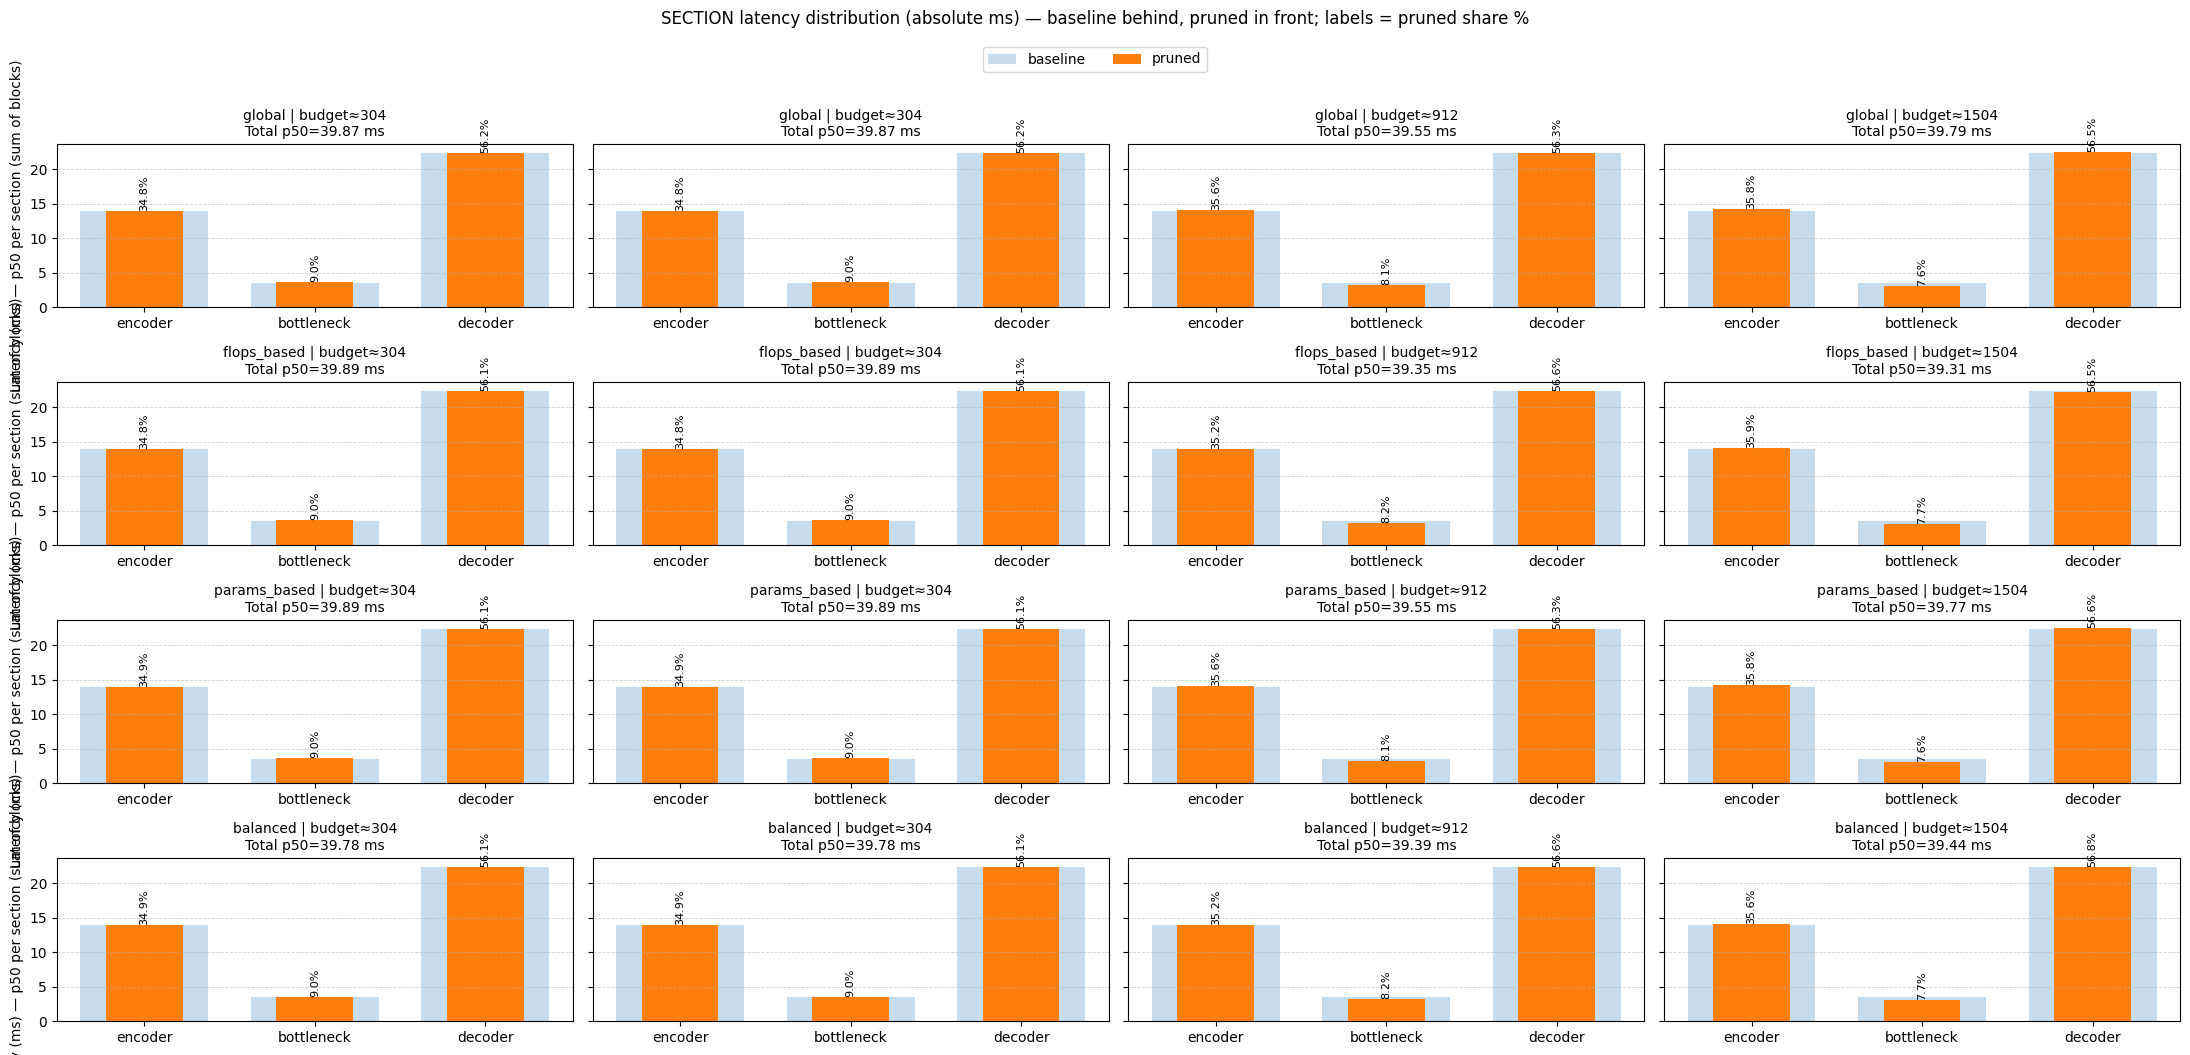

In [273]:
# Cell E — Plot: "baseline behind, pruned in front" for SECTION latency distribution (absolute ms)
# Same style as your params/flops distribution plots:
# - baseline bars behind (blue, transparent)
# - pruned bars in front (orange)
# - labels show % share of pruned (enc/bottleneck/dec)

import numpy as np
import matplotlib.pyplot as plt

SECS = ["encoder", "bottleneck", "decoder"]
types = ["global", "flops_based", "params_based", "balanced"]
budgets = [300, 500, 900, 1600]

# baseline absolute per section
base_row = df_sec_lat[df_sec_lat["experiment_type"] == "baseline"].iloc[0]
base_abs = np.array([float(base_row["enc_ms_p50"]), float(base_row["bottleneck_ms_p50"]), float(base_row["dec_ms_p50"])], dtype=float)

def pick_row_latency(df, t, target_budget):
    dd = df[df["experiment_type"] == t].copy()
    dd["dist"] = (pd.to_numeric(dd["budget_x"], errors="coerce") - target_budget).abs()
    return dd.sort_values(["dist"]).iloc[0]

x = np.arange(len(SECS))

fig, axes = plt.subplots(len(types), len(budgets), figsize=(22, 10), sharey=True)

for i, t in enumerate(types):
    for j, b in enumerate(budgets):
        ax = axes[i, j]
        dd = df_sec_lat[df_sec_lat["experiment_type"] == t]
        if dd.empty:
            ax.axis("off")
            continue

        rr = pick_row_latency(df_sec_lat, t, b)
        pr_abs = np.array([float(rr["enc_ms_p50"]), float(rr["bottleneck_ms_p50"]), float(rr["dec_ms_p50"])], dtype=float)

        pr_total = float(np.nansum(pr_abs))
        pr_share = (pr_abs / pr_total * 100.0) if pr_total > 0 else np.full_like(pr_abs, np.nan)

        ax.bar(x, base_abs, width=0.75, alpha=0.25, label="baseline" if (i==0 and j==0) else None)
        ax.bar(x, pr_abs,   width=0.45, alpha=1.00, label="pruned"   if (i==0 and j==0) else None)

        ax.set_xticks(x)
        ax.set_xticklabels(SECS)
        ax.grid(True, axis="y", linestyle="--", linewidth=0.6, alpha=0.6)

        # share labels on pruned bars
        for k in range(len(SECS)):
            if np.isfinite(pr_abs[k]) and pr_abs[k] > 0 and np.isfinite(pr_share[k]):
                ax.text(k, pr_abs[k], f"{pr_share[k]:.1f}%", ha="center", va="bottom", fontsize=8, rotation=90)

        ax.set_title(f"{t} | budget≈{int(rr['budget_x'])}\nTotal p50={float(rr['lat_total_ms_p50']):.2f} ms", fontsize=10)

for r_i in range(len(types)):
    axes[r_i, 0].set_ylabel("Latency (ms) — p50 per section (sum of blocks)")

handles, labels = axes[0, 0].get_legend_handles_labels()
if handles:
    fig.legend(handles, labels, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.02))

plt.suptitle("SECTION latency distribution (absolute ms) — baseline behind, pruned in front; labels = pruned share %", y=1.05)
plt.tight_layout()
plt.show()


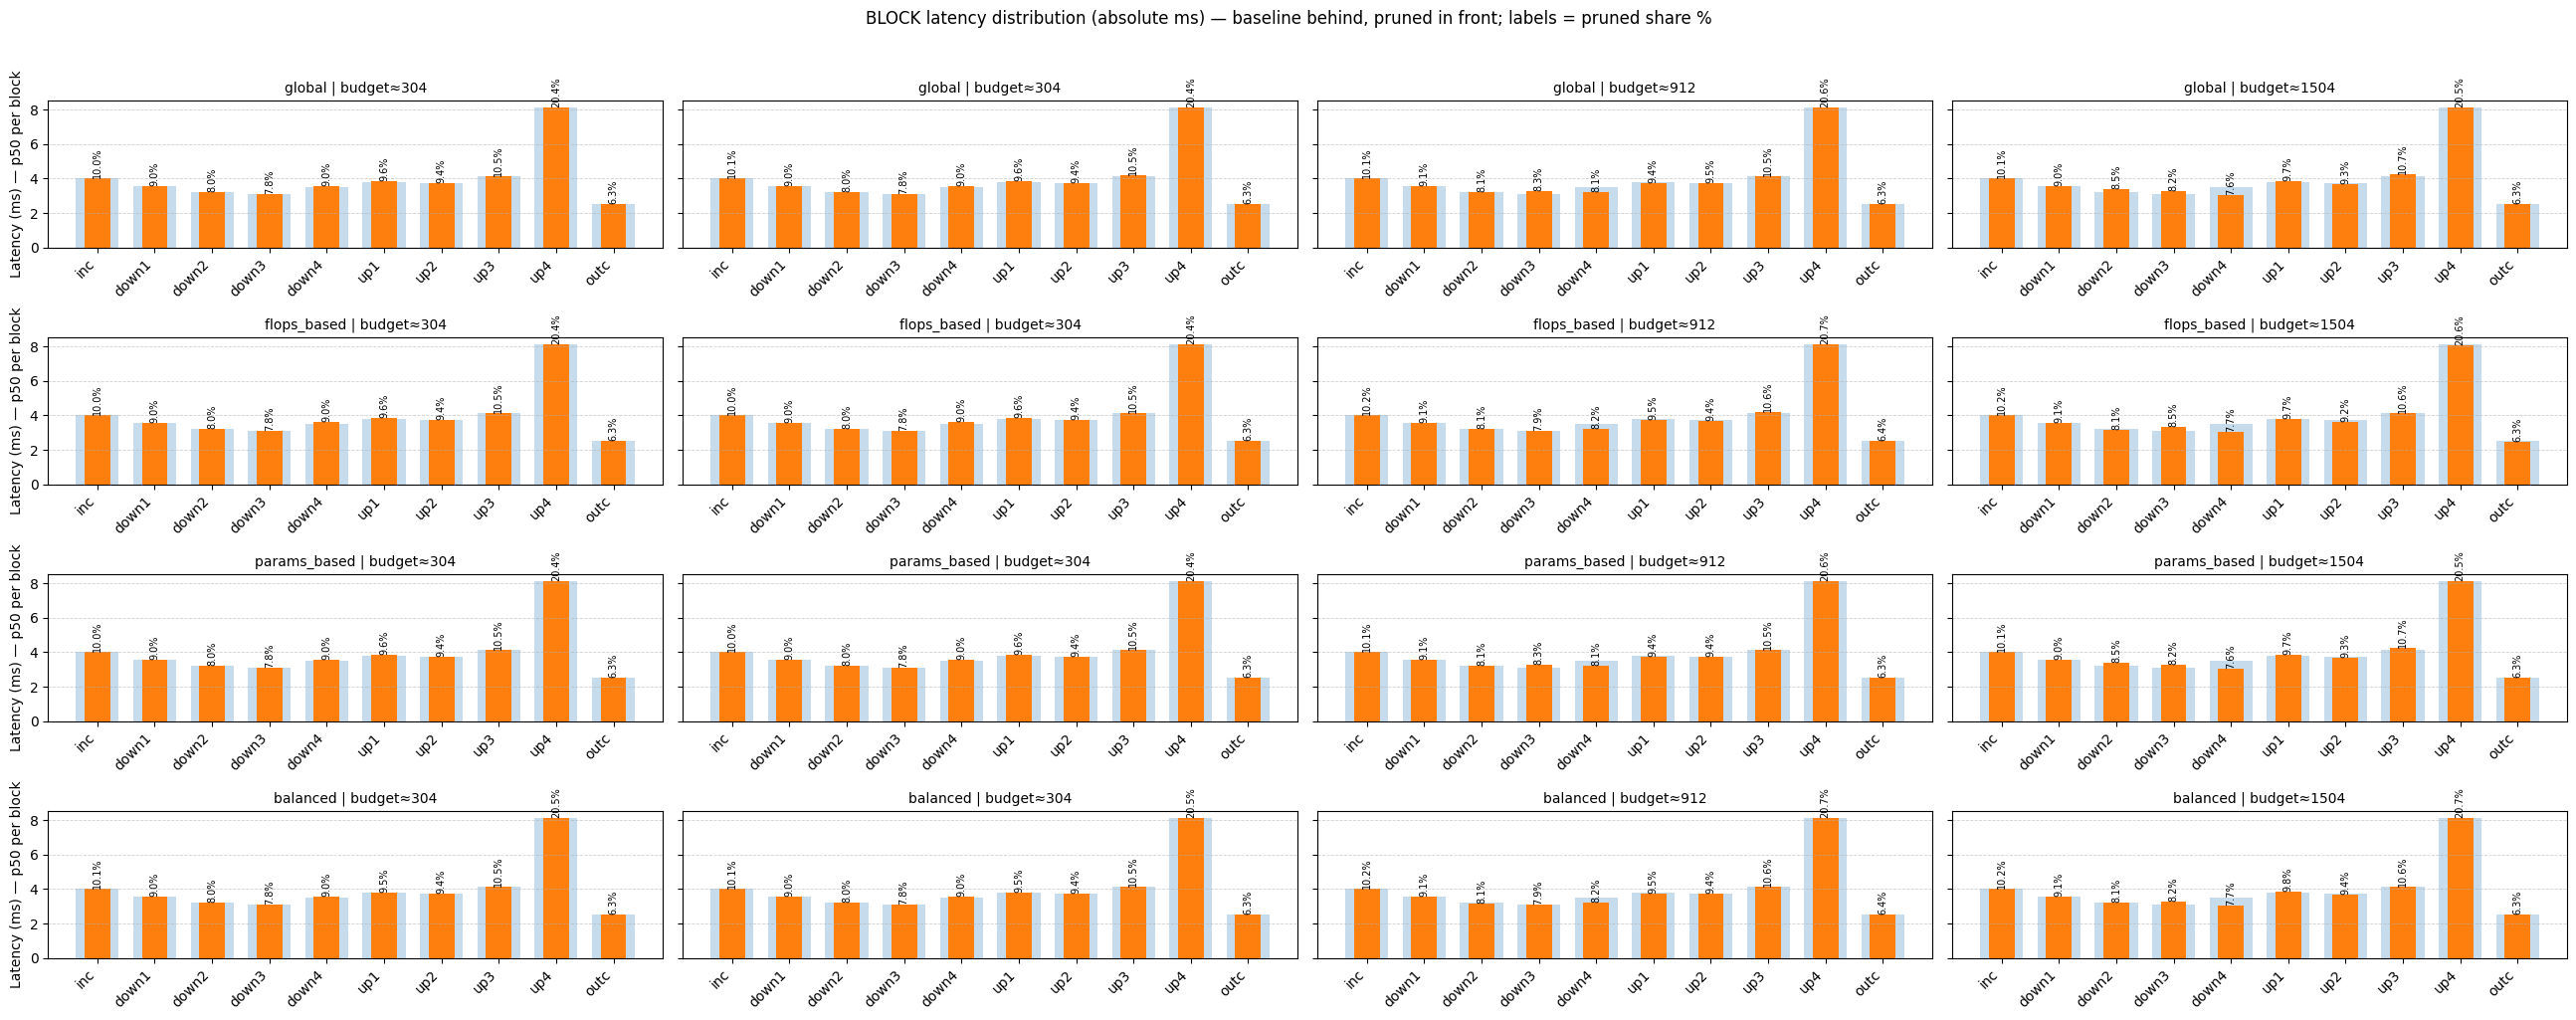

In [274]:
# Cell F (optional) — Same view but per-BLOCK latency distribution (inc..outc)
# Useful if you want the detailed "all blocks" analog of your params/flops distribution plots.

import numpy as np
import matplotlib.pyplot as plt

BLOCKS = ["inc","down1","down2","down3","down4","up1","up2","up3","up4","outc"]
types = ["global", "flops_based", "params_based", "balanced"]
budgets = [300, 500, 900, 1600]

def profile_blocks_latency_row(weights_path: str):
    m, _ = build_unet_from_weights(weights_path, device=DEVICE)
    prof = profile_sections_latency_ms(
        m, device=DEVICE, input_hw=INPUT_HW, batch_size=BATCH,
        warmup=WARMUP, runs=RUNS, use_amp=USE_AMP, channels_last=CHANNELS_LAST
    )
    blk = prof["block_df"].set_index("block")["lat_ms_p50"].to_dict()
    return blk

# baseline blocks
base_blocks = profile_blocks_latency_row(BASELINE_PTH)
base_abs = np.array([float(base_blocks.get(b, np.nan)) for b in BLOCKS], dtype=float)
x = np.arange(len(BLOCKS))

fig, axes = plt.subplots(len(types), len(budgets), figsize=(26, 10), sharey=True)

for i, t in enumerate(types):
    for j, b in enumerate(budgets):
        ax = axes[i, j]
        dd = df_sec_lat[df_sec_lat["experiment_type"] == t]
        if dd.empty:
            ax.axis("off")
            continue

        rr = pick_row_latency(df_sec_lat, t, b)
        blk = profile_blocks_latency_row(rr["weights_path"])
        pr_abs = np.array([float(blk.get(bb, np.nan)) for bb in BLOCKS], dtype=float)

        pr_total = float(np.nansum(pr_abs))
        pr_share = (pr_abs / pr_total * 100.0) if pr_total > 0 else np.full_like(pr_abs, np.nan)

        ax.bar(x, base_abs, width=0.75, alpha=0.25)
        ax.bar(x, pr_abs,   width=0.45, alpha=1.00)

        ax.set_xticks(x)
        ax.set_xticklabels(BLOCKS, rotation=45, ha="right")
        ax.grid(True, axis="y", linestyle="--", linewidth=0.6, alpha=0.6)

        for k in range(len(BLOCKS)):
            if np.isfinite(pr_abs[k]) and pr_abs[k] > 0 and np.isfinite(pr_share[k]):
                ax.text(k, pr_abs[k], f"{pr_share[k]:.1f}%", ha="center", va="bottom", fontsize=7, rotation=90)

        ax.set_title(f"{t} | budget≈{int(rr['budget_x'])}", fontsize=10)

for r_i in range(len(types)):
    axes[r_i, 0].set_ylabel("Latency (ms) — p50 per block")

plt.suptitle("BLOCK latency distribution (absolute ms) — baseline behind, pruned in front; labels = pruned share %", y=1.02)
plt.tight_layout()
plt.show()


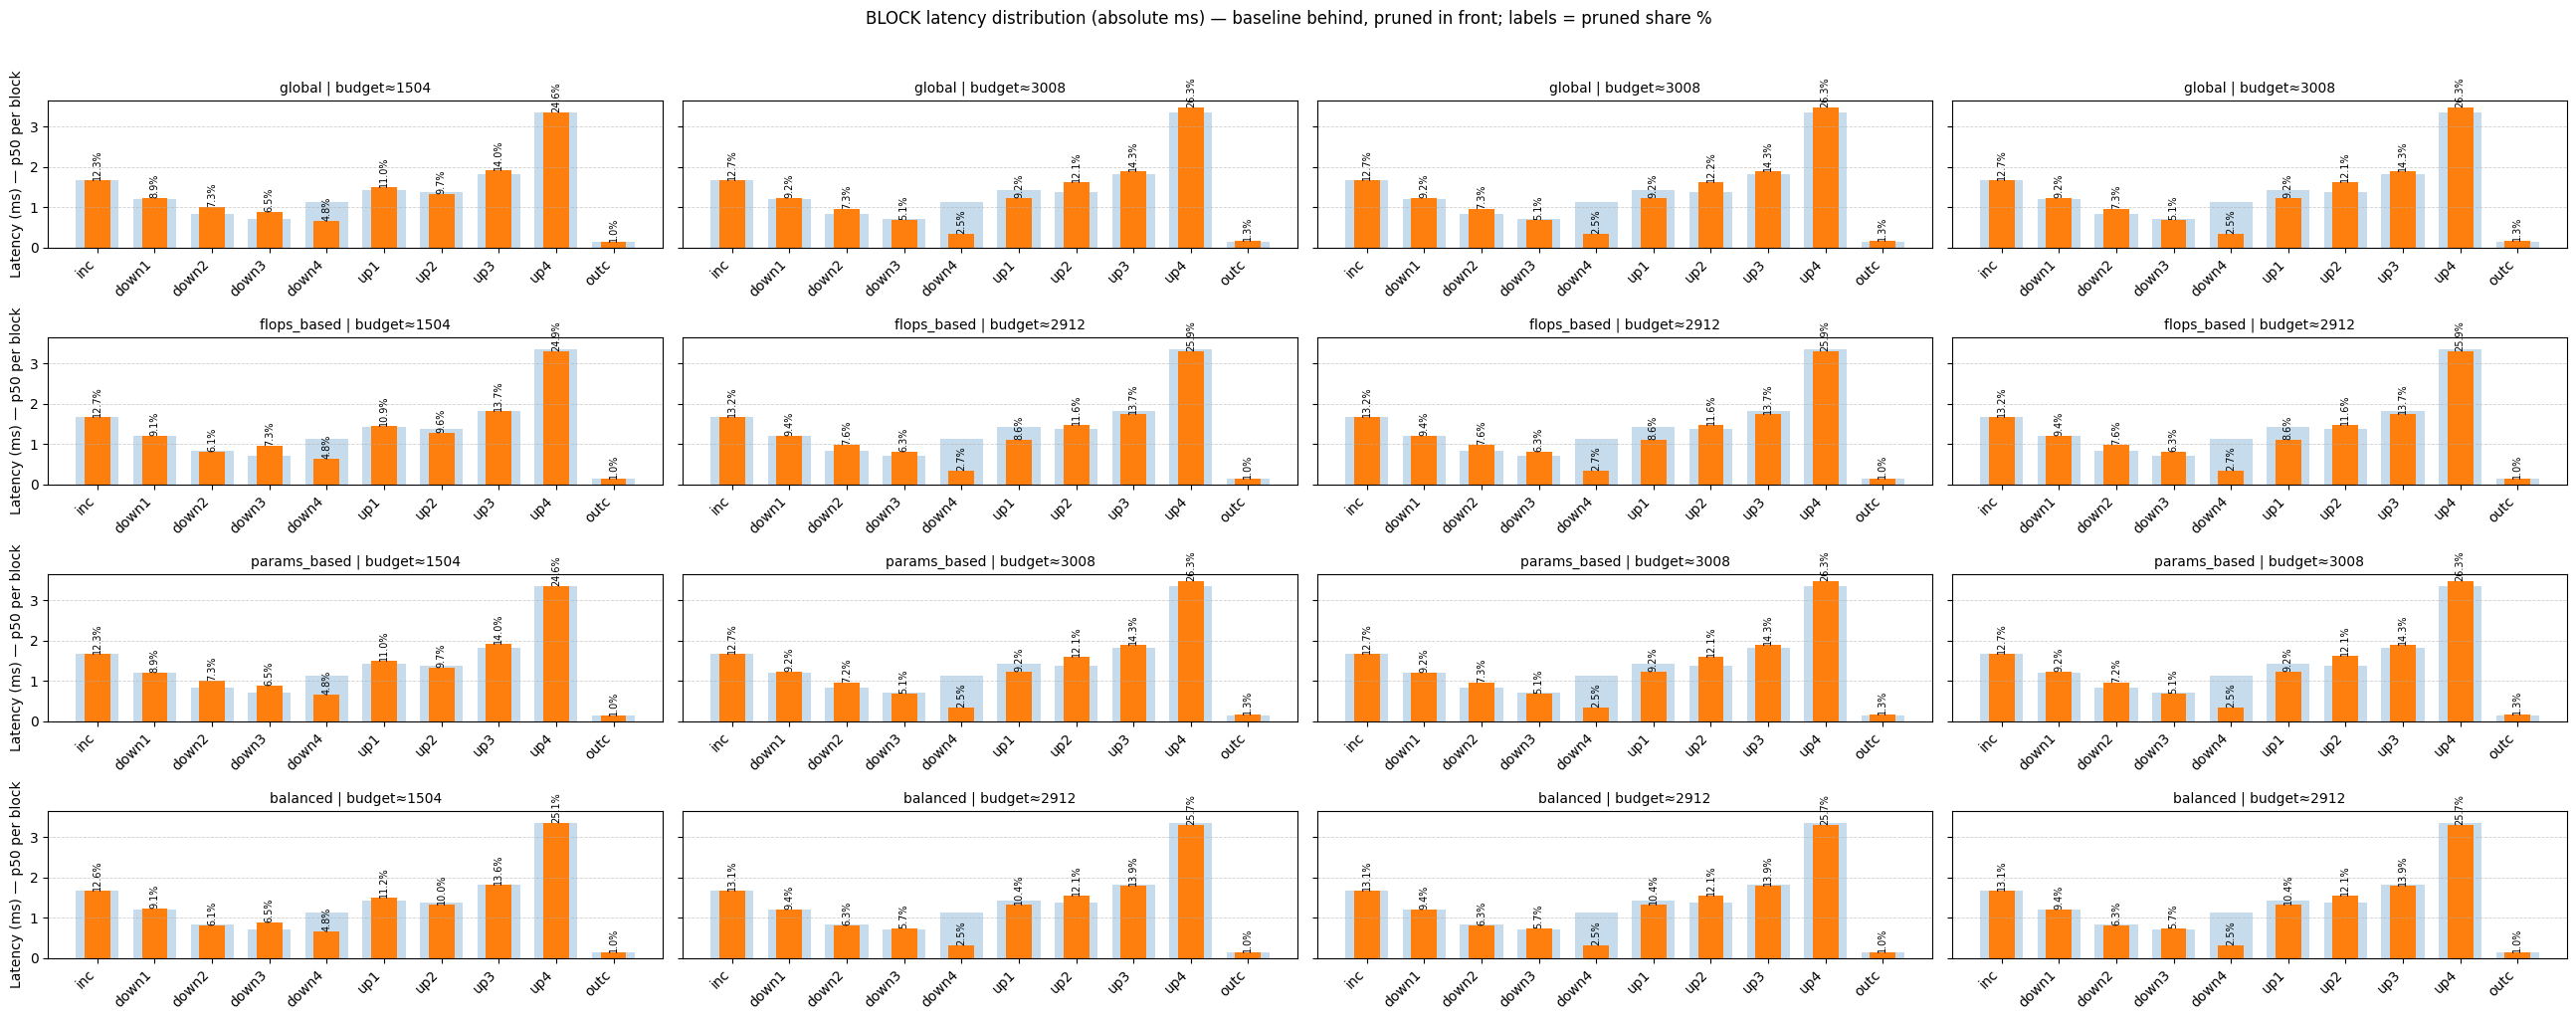

In [281]:
# Cell F (optional) — Same view but per-BLOCK latency distribution (inc..outc)
# Useful if you want the detailed "all blocks" analog of your params/flops distribution plots.

import numpy as np
import matplotlib.pyplot as plt

BLOCKS = ["inc","down1","down2","down3","down4","up1","up2","up3","up4","outc"]
types = ["global", "flops_based", "params_based", "balanced"]
budgets = [1900, 2500, 2700, 3300]

def profile_blocks_latency_row(weights_path: str):
    m, _ = build_unet_from_weights(weights_path, device=DEVICE)
    prof = profile_sections_latency_ms(
        m, device=DEVICE, input_hw=INPUT_HW, batch_size=BATCH,
        warmup=WARMUP, runs=RUNS, use_amp=USE_AMP, channels_last=CHANNELS_LAST
    )
    blk = prof["block_df"].set_index("block")["lat_ms_p50"].to_dict()
    return blk

# baseline blocks
base_blocks = profile_blocks_latency_row(BASELINE_PTH)
base_abs = np.array([float(base_blocks.get(b, np.nan)) for b in BLOCKS], dtype=float)
x = np.arange(len(BLOCKS))

fig, axes = plt.subplots(len(types), len(budgets), figsize=(26, 10), sharey=True)

for i, t in enumerate(types):
    for j, b in enumerate(budgets):
        ax = axes[i, j]
        dd = df_sec_lat[df_sec_lat["experiment_type"] == t]
        if dd.empty:
            ax.axis("off")
            continue

        rr = pick_row_latency(df_sec_lat, t, b)
        blk = profile_blocks_latency_row(rr["weights_path"])
        pr_abs = np.array([float(blk.get(bb, np.nan)) for bb in BLOCKS], dtype=float)

        pr_total = float(np.nansum(pr_abs))
        pr_share = (pr_abs / pr_total * 100.0) if pr_total > 0 else np.full_like(pr_abs, np.nan)

        ax.bar(x, base_abs, width=0.75, alpha=0.25)
        ax.bar(x, pr_abs,   width=0.45, alpha=1.00)

        ax.set_xticks(x)
        ax.set_xticklabels(BLOCKS, rotation=45, ha="right")
        ax.grid(True, axis="y", linestyle="--", linewidth=0.6, alpha=0.6)

        for k in range(len(BLOCKS)):
            if np.isfinite(pr_abs[k]) and pr_abs[k] > 0 and np.isfinite(pr_share[k]):
                ax.text(k, pr_abs[k], f"{pr_share[k]:.1f}%", ha="center", va="bottom", fontsize=7, rotation=90)

        ax.set_title(f"{t} | budget≈{int(rr['budget_x'])}", fontsize=10)

for r_i in range(len(types)):
    axes[r_i, 0].set_ylabel("Latency (ms) — p50 per block")

plt.suptitle("BLOCK latency distribution (absolute ms) — baseline behind, pruned in front; labels = pruned share %", y=1.02)
plt.tight_layout()
plt.show()


## Time Analysis (More generalised)

In [275]:
# Cell C — REPLACEMENT (debug + hard fix)

import sys
from pathlib import Path
import torch

ROOT = Path(".").resolve()
PRUNE_UNET_DIR = ROOT / "Prune_U-Net"
if str(PRUNE_UNET_DIR) not in sys.path:
    sys.path.insert(0, str(PRUNE_UNET_DIR))

from unet import UNet

N_CHANNELS = 3
N_CLASSES  = 2

# Your provided baseline channels (22 lines)
BASELINE_CHANNELS = [
    64, 64, 128, 128, 256, 256, 512, 512,
    1024, 1024, 1024,
    512, 512, 512,
    256, 256, 256,
    128, 128, 128,
    64, 64
]

BASELINE_CHANNELS_TXT = (ROOT / "baseline_channels.txt").resolve()

# ---- HARD rewrite (no conditionals)
BASELINE_CHANNELS_TXT.write_text("\n".join(map(str, BASELINE_CHANNELS)) + "\n")

# ---- verify we read back exactly what we wrote
raw = BASELINE_CHANNELS_TXT.read_text().strip().splitlines()
read_back = [int(x.strip()) for x in raw if x.strip() != ""]
print("Baseline channels file:", BASELINE_CHANNELS_TXT)
print("Lines in file:", len(raw), "| Parsed ints:", len(read_back))
print("First 10:", read_back[:10])
print("Last  10:", read_back[-10:])

# If this fails, you are not writing/reading the same file path
assert read_back == BASELINE_CHANNELS, "baseline_channels.txt content mismatch vs BASELINE_CHANNELS list"

# ---- now build
def build_model_for_checkpoint(channel_txt_path: str) -> torch.nn.Module:
    return UNet(n_channels=N_CHANNELS, n_classes=N_CLASSES, f_channels=str(channel_txt_path))

# ---- extra safety: confirm UNet can be instantiated
try:
    _tmp = build_model_for_checkpoint(str(BASELINE_CHANNELS_TXT))
    print("UNet constructed OK with baseline channels. #params:", sum(p.numel() for p in _tmp.parameters()))
    del _tmp
except Exception as e:
    print("FAILED to construct UNet with baseline channels:", repr(e))
    raise


Baseline channels file: /home/jovyan/pruning-datavol-1/Prune_U-Net/analysis/baseline_channels.txt
Lines in file: 22 | Parsed ints: 22
First 10: [64, 64, 128, 128, 256, 256, 512, 512, 1024, 1024]
Last  10: [512, 512, 256, 256, 256, 128, 128, 128, 64, 64]
UNet constructed OK with baseline channels. #params: 31037698


In [276]:
# Cell H — PATCH: loader that ALWAYS passes a channels txt

import time
import numpy as np
import pandas as pd
from pathlib import Path
import torch

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

IMG_SIZE = 512
BATCH_SIZE = 1
WARMUP = 30
RUNS   = 200

USE_FP16 = False
DTYPE = torch.float16 if (USE_FP16 and DEVICE == "cuda") else torch.float32

def _safe_load_state_dict(path: str):
    try:
        return torch.load(path, map_location="cpu", weights_only=True)
    except TypeError:
        return torch.load(path, map_location="cpu")

def _load_model_from_ckpt(ckpt_path: Path, channels_txt: Path) -> torch.nn.Module:
    m = build_model_for_checkpoint(str(channels_txt)).to(DEVICE)

    sd = _safe_load_state_dict(str(ckpt_path))

    # strip DDP "module."
    if isinstance(sd, dict) and any(isinstance(k, str) and k.startswith("module.") for k in sd.keys()):
        sd = {k.replace("module.", "", 1): v for k, v in sd.items()}

    m.load_state_dict(sd, strict=True)
    m.eval()

    if DEVICE == "cuda":
        m = m.to(memory_format=torch.channels_last)
    if USE_FP16 and DEVICE == "cuda":
        m = m.half()

    return m

@torch.no_grad()
def measure_latency_ms_p50(model: torch.nn.Module, img_size: int, runs: int, warmup: int) -> float:
    x = torch.randn(BATCH_SIZE, 3, img_size, img_size, device=DEVICE, dtype=DTYPE)
    if DEVICE == "cuda":
        x = x.to(memory_format=torch.channels_last)

    for _ in range(warmup):
        _ = model(x)
    if DEVICE == "cuda":
        torch.cuda.synchronize()

    times = []
    for _ in range(runs):
        if DEVICE == "cuda":
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        _ = model(x)
        if DEVICE == "cuda":
            torch.cuda.synchronize()
        t1 = time.perf_counter()
        times.append((t1 - t0) * 1000.0)

    return float(np.percentile(np.array(times, dtype=np.float64), 50))

# ---------------------------
# Baseline latency (fixed)
# ---------------------------
if "BASELINE_PTH" not in globals():
    raise RuntimeError("Set BASELINE_PTH before running. It should point to the baseline checkpoint .pth")

BASELINE_PTH = str(Path(BASELINE_PTH).resolve())
print("Baseline checkpoint:", BASELINE_PTH)

# IMPORTANT: baseline must use BASELINE_CHANNELS_TXT (created in Cell C replacement)
base_model = _load_model_from_ckpt(Path(BASELINE_PTH), channels_txt=Path(BASELINE_CHANNELS_TXT))
baseline_lat_p50 = measure_latency_ms_p50(base_model, IMG_SIZE, runs=RUNS, warmup=WARMUP)
print(f"Baseline latency p50: {baseline_lat_p50:.3f} ms (runs={RUNS}, warmup={WARMUP})")

# ---------------------------
# ALL runs benchmark (same as before, but pass each run's pruned_channels.txt)
# ---------------------------
if "df_runs" not in globals() or df_runs is None or df_runs.empty:
    raise RuntimeError("df_runs is missing/empty.")

def _run_dir_from_log_path(log_path: str) -> Path:
    p = Path(str(log_path))
    if p.is_dir():
        return p
    if p.name.lower() == "log.txt":
        return p.parent
    return p.parent

def _find_finetuned_ckpt(run_dir: Path) -> Path:
    for name in ["Finetuned.pth", "finetuned.pth"]:
        p = run_dir / name
        if p.exists():
            return p
    cands = [p for p in run_dir.glob("*.pth") if "finetuned" in p.name.lower()]
    if cands:
        cands = sorted(cands, key=lambda p: p.stat().st_size, reverse=True)
        return cands[0]
    raise FileNotFoundError(f"No Finetuned checkpoint found in {run_dir}")

def _find_channels_txt(run_dir: Path) -> Path:
    p = run_dir / "pruned_channels.txt"
    if not p.exists():
        raise FileNotFoundError(f"Missing pruned_channels.txt in {run_dir} (cannot build pruned architecture)")
    return p

all_runs = df_runs.copy()
all_runs["run_dir"] = all_runs["log_path"].apply(lambda p: str(_run_dir_from_log_path(p).resolve()))

def _has_needed_files(run_dir: str) -> bool:
    d = Path(run_dir)
    try:
        _ = _find_finetuned_ckpt(d)
        _ = _find_channels_txt(d)
        return True
    except Exception:
        return False

all_runs["ok_files"] = all_runs["run_dir"].apply(_has_needed_files)
cand = all_runs[all_runs["ok_files"]].copy()

print("Runnable finetuned runs:", len(cand), "/", len(all_runs))

lat_cache = {}
rows, fail = [], []

for _, r in cand.iterrows():
    run_dir = Path(r["run_dir"])
    key = str(run_dir)

    try:
        if key in lat_cache:
            lat_p50 = lat_cache[key]
        else:
            ckpt = _find_finetuned_ckpt(run_dir)
            ch   = _find_channels_txt(run_dir)

            model = _load_model_from_ckpt(ckpt, channels_txt=ch)
            lat_p50 = measure_latency_ms_p50(model, IMG_SIZE, runs=RUNS, warmup=WARMUP)
            lat_cache[key] = lat_p50

        rows.append({
            "log_path": r.get("log_path",""),
            "run_dir": str(run_dir),
            "experiment_type": r.get("experiment_type",""),
            "budget_x": float(r.get("budget_x", np.nan)) if pd.notna(r.get("budget_x", np.nan)) else np.nan,
            "model_name": r.get("model_name",""),
            "dice_pruned": r.get("dice_pruned", np.nan),
            "lat_ms_p50": float(lat_p50),
        })

    except Exception as e:
        fail.append((r.get("model_name",""), str(run_dir), repr(e)))

    finally:
        try:
            del model
        except Exception:
            pass
        if DEVICE == "cuda":
            torch.cuda.empty_cache()

df_latency_all = pd.DataFrame(rows)

print("Benchmarked:", len(df_latency_all), "/", len(cand))
if fail:
    print("\nFailures:", len(fail))
    for x in fail[:10]:
        print(" -", x)

display(df_latency_all.head())


Baseline checkpoint: /home/jovyan/pruning-datavol-1/Prune_U-Net/unet_carvana_scale0.5_epoch2.pth
Baseline latency p50: 37.103 ms (runs=200, warmup=30)
Runnable finetuned runs: 82 / 82
Benchmarked: 82 / 82


,log_path,run_dir,experiment_type,budget_x,model_name,dice_pruned,lat_ms_p50
0,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...,global,NaN,global_b300,0.990509,38.846026
1,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...,global,NaN,global_b500,0.989379,38.661204
2,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...,global,NaN,global_b700,0.990607,36.104190
3,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...,global,NaN,global_b900,0.990311,38.693732
4,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...,global,NaN,global_b1100,0.990484,35.712708


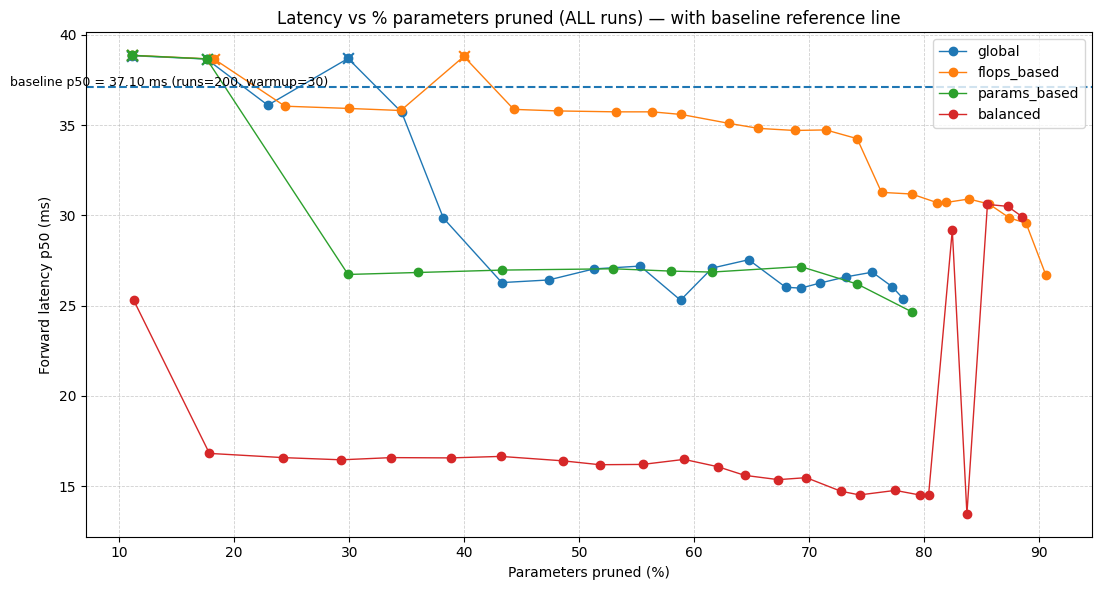

,experiment_type,budget_x,model_name,params_pruned_pct_x,lat_ms_p50,dice_pruned,run_dir
45,flops_based,NaN,flops_b300,11.104055,38.870120,0.990157,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...
71,params_based,NaN,params_b300,11.115786,38.866284,0.990509,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...
70,params_based,NaN,params_b300,11.115786,38.863082,0.990509,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...
0,global,NaN,global_b300,11.115786,38.846026,0.990509,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...
50,flops_based,NaN,flops_b1300,39.967165,38.803575,0.990389,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...
3,global,NaN,global_b900,29.898835,38.693732,0.990311,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...
72,params_based,NaN,params_b500,17.594797,38.667825,0.989379,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...
1,global,NaN,global_b500,17.594797,38.661204,0.989379,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...
46,flops_based,NaN,flops_b500,18.260088,38.654878,0.990394,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...
2,global,NaN,global_b700,22.921204,36.104190,0.990607,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...


In [277]:
# Cell I — Plot latency vs % params pruned (ALL runs) + baseline horizontal line
# Requires: df_latency_all, df_runs, df_baseline, baseline_lat_p50

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if "df_latency_all" not in globals() or df_latency_all is None or df_latency_all.empty:
    raise RuntimeError("df_latency_all is empty. Run Cell H first.")

if "baseline_lat_p50" not in globals():
    raise RuntimeError("baseline_lat_p50 missing. Cell H computes it.")

base_params = float(df_baseline.loc[0, "params_baseline"])

# Merge params info from df_runs (all runs)
# We use log_path as key (most reliable)
need_cols = ["log_path", "params_keep_pct", "params_reduction_pct", "params_pruned", "experiment_type", "budget_x"]
right = df_runs[[c for c in need_cols if c in df_runs.columns]].drop_duplicates("log_path")

d = df_latency_all.merge(right, on="log_path", how="left", suffixes=("", "_src"))

# Compute % pruned (x-axis)
if "params_reduction_pct" in d.columns and d["params_reduction_pct"].notna().any():
    d["params_pruned_pct_x"] = pd.to_numeric(d["params_reduction_pct"], errors="coerce")
elif "params_keep_pct" in d.columns and d["params_keep_pct"].notna().any():
    d["params_pruned_pct_x"] = 100.0 - pd.to_numeric(d["params_keep_pct"], errors="coerce")
elif "params_pruned" in d.columns and d["params_pruned"].notna().any():
    d["params_pruned_pct_x"] = (1.0 - (pd.to_numeric(d["params_pruned"], errors="coerce") / base_params)) * 100.0
else:
    raise RuntimeError("No params columns to compute % pruned (need params_reduction_pct or params_keep_pct or params_pruned).")

d["params_pruned_pct_x"] = d["params_pruned_pct_x"].clip(0, 100)

# Flag worse-than-baseline
d["worse_than_baseline"] = d["lat_ms_p50"] > float(baseline_lat_p50)

# Plot
types = ["global", "flops_based", "params_based", "balanced"]
plt.figure(figsize=(11, 6))

for t in types:
    dt = d[d["experiment_type"] == t].dropna(subset=["params_pruned_pct_x", "lat_ms_p50"]).sort_values("params_pruned_pct_x")
    if dt.empty:
        continue
    plt.plot(dt["params_pruned_pct_x"], dt["lat_ms_p50"], marker="o", linewidth=1, label=t)

    # highlight worse-than-baseline points
    bad = dt[dt["worse_than_baseline"]]
    if not bad.empty:
        plt.scatter(bad["params_pruned_pct_x"], bad["lat_ms_p50"], s=60, marker="x")

# Baseline reference line
plt.axhline(float(baseline_lat_p50), linestyle="--", linewidth=1.5)
plt.text(
    0.5, float(baseline_lat_p50) + 0.05,
    f"baseline p50 = {baseline_lat_p50:.2f} ms (runs={RUNS}, warmup={WARMUP})",
    fontsize=9
)

plt.xlabel("Parameters pruned (%)")
plt.ylabel("Forward latency p50 (ms)")
plt.title("Latency vs % parameters pruned (ALL runs) — with baseline reference line")
plt.grid(True, linestyle="--", linewidth=0.6, alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

# Optional: quick diagnostic table (worst offenders)
worst = d.dropna(subset=["params_pruned_pct_x","lat_ms_p50"]).sort_values("lat_ms_p50", ascending=False).head(15)
display(worst[["experiment_type","budget_x","model_name","params_pruned_pct_x","lat_ms_p50","dice_pruned","run_dir"]])


#### Run on CPU

In [278]:
# NEXT CELL — Run the same latency-vs-%pruned experiment on CPU (no repeats of previous setup)
# Assumes you already have:
#   - df_runs (ALL runs table with experiment_type, budget_x, model_name, log_path, params_reduction_pct/params_keep_pct)
#   - safe_load_state_dict, run_dir_from_log_path, find_finetuned_ckpt, build_model_for_checkpoint
#   - measure_latency_ms_p50 (or measure_latency_cpu_p50_ms) from earlier cells
#   - baseline_gpu_p50 (optional) and baseline_cpu_p50 (optional)

import os
import time
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import torch

# ---------------------------
# CPU CONFIG (only here)
# ---------------------------
CPU_DEVICE = "cpu"
torch.set_num_threads(os.cpu_count() or 8)

# Use same inference size as GPU unless it's too slow
CPU_IMG_SIZE = IMG_SIZE if "IMG_SIZE" in globals() else 512
CPU_WARMUP   = WARMUP if "WARMUP" in globals() else 30
CPU_RUNS     = RUNS if "RUNS" in globals() else 200

print("CPU benchmark:", CPU_DEVICE, "| threads:", torch.get_num_threads(),
      "| IMG:", CPU_IMG_SIZE, "| warmup:", CPU_WARMUP, "| runs:", CPU_RUNS)

# ---------------------------
# Helpers (minimal + CPU-safe)
# ---------------------------
def _safe_load_state_dict_cpu(path: str):
    # always load to CPU
    try:
        return torch.load(path, map_location="cpu", weights_only=True)
    except TypeError:
        return torch.load(path, map_location="cpu")

def _load_model_cpu(ckpt_path: Path, channels_txt: Path) -> torch.nn.Module:
    m = build_model_for_checkpoint(str(channels_txt)).to(CPU_DEVICE)
    sd = _safe_load_state_dict_cpu(str(ckpt_path))
    if isinstance(sd, dict) and any(isinstance(k, str) and k.startswith("module.") for k in sd.keys()):
        sd = {k.replace("module.", "", 1): v for k, v in sd.items()}
    m.load_state_dict(sd, strict=True)
    m.eval()
    return m

@torch.inference_mode()
def _measure_latency_cpu_p50_ms(model: torch.nn.Module, img_size: int, warmup: int, runs: int) -> float:
    x = torch.randn(1, 3, img_size, img_size, device="cpu", dtype=torch.float32)

    for _ in range(warmup):
        _ = model(x)

    times = []
    for _ in range(runs):
        t0 = time.perf_counter()
        _ = model(x)
        t1 = time.perf_counter()
        times.append((t1 - t0) * 1000.0)

    return float(np.percentile(np.asarray(times, dtype=np.float64), 50))

# ---------------------------
# Build runnable ALL-runs table from df_runs
# ---------------------------
if "df_runs" not in globals() or df_runs is None or df_runs.empty:
    raise RuntimeError("df_runs missing/empty.")

d_all = df_runs.copy()
if "log_path" not in d_all.columns:
    raise RuntimeError("df_runs must contain log_path.")

# locate ckpt + channels
d_all["run_dir"] = d_all["log_path"].apply(lambda p: str(run_dir_from_log_path(p).resolve()))
d_all["ckpt_path"] = d_all["run_dir"].apply(lambda rd: str(find_finetuned_ckpt(Path(rd))) if find_finetuned_ckpt(Path(rd)) else "")
d_all["channels_txt"] = d_all["run_dir"].apply(lambda rd: str((Path(rd) / "pruned_channels.txt").resolve()) if (Path(rd) / "pruned_channels.txt").exists() else "")

d_ok = d_all[(d_all["ckpt_path"] != "") & (d_all["channels_txt"] != "")].copy()
print("Runnable runs on CPU:", len(d_ok), "/", len(d_all))

# ---------------------------
# CPU Benchmark (ALL runs)
# ---------------------------
cpu_rows = []
cpu_fail = []

for _, r in d_ok.iterrows():
    try:
        m = _load_model_cpu(Path(r["ckpt_path"]), Path(r["channels_txt"]))
        p50 = _measure_latency_cpu_p50_ms(m, CPU_IMG_SIZE, warmup=CPU_WARMUP, runs=CPU_RUNS)

        cpu_rows.append({
            "experiment_type": r.get("experiment_type", ""),
            "budget_x": float(r.get("budget_x", np.nan)) if pd.notna(r.get("budget_x", np.nan)) else np.nan,
            "model_name": r.get("model_name", ""),
            "log_path": r.get("log_path", ""),
            "run_dir": r.get("run_dir", ""),
            "ckpt_path": r.get("ckpt_path", ""),
            "channels_txt": r.get("channels_txt", ""),
            "device": "cpu",
            "img_size": CPU_IMG_SIZE,
            "warmup": CPU_WARMUP,
            "runs": CPU_RUNS,
            "lat_ms_p50": float(p50),
            # carry pruning % if present
            "params_reduction_pct": r.get("params_reduction_pct", np.nan),
            "params_keep_pct": r.get("params_keep_pct", np.nan),
        })

    except Exception as e:
        cpu_fail.append((r.get("model_name",""), r.get("ckpt_path",""), repr(e)))

    finally:
        try:
            del m
        except Exception:
            pass

df_latency_cpu = pd.DataFrame(cpu_rows)
print("CPU bench done:", len(df_latency_cpu), "| fails:", len(cpu_fail))
if cpu_fail:
    for x in cpu_fail[:10]:
        print(" -", x)

# ---------------------------
# Compute x=% pruned (robust)
# ---------------------------
d = df_latency_cpu.copy()
if "params_reduction_pct" in d.columns and d["params_reduction_pct"].notna().any():
    d["params_pruned_pct_x"] = pd.to_numeric(d["params_reduction_pct"], errors="coerce")
elif "params_keep_pct" in d.columns and d["params_keep_pct"].notna().any():
    d["params_pruned_pct_x"] = 100.0 - pd.to_numeric(d["params_keep_pct"], errors="coerce")
else:
    # fallback: merge from df_runs (should have it)
    key = "log_path" if ("log_path" in d.columns and "log_path" in df_runs.columns) else "model_name"
    d = d.merge(df_runs[[key, "params_reduction_pct", "params_keep_pct"]].drop_duplicates(key), on=key, how="left")
    if d["params_reduction_pct"].notna().any():
        d["params_pruned_pct_x"] = pd.to_numeric(d["params_reduction_pct"], errors="coerce")
    else:
        d["params_pruned_pct_x"] = 100.0 - pd.to_numeric(d["params_keep_pct"], errors="coerce")

d["params_pruned_pct_x"] = d["params_pruned_pct_x"].clip(0, 100)

# ---------------------------
# Baseline CPU line (optional)
# ---------------------------
baseline_cpu_line = None
if "baseline_cpu_p50" in globals() and baseline_cpu_p50 is not None:
    baseline_cpu_line = float(baseline_cpu_p50)

# If you have BASELINE_PTH + BASELINE_CHANNELS_TXT available from earlier cells, compute it now
if baseline_cpu_line is None and "BASELINE_PTH" in globals() and "BASELINE_CHANNELS_TXT" in globals():
    try:
        bm = _load_model_cpu(Path(BASELINE_PTH), Path(BASELINE_CHANNELS_TXT))
        baseline_cpu_line = _measure_latency_cpu_p50_ms(bm, CPU_IMG_SIZE, warmup=CPU_WARMUP, runs=CPU_RUNS)
        print(f"Computed baseline CPU p50: {baseline_cpu_line:.3f} ms")
        del bm
    except Exception as e:
        print("[WARN] Could not compute baseline CPU:", repr(e))
        baseline_cpu_line = None

# ---------------------------
# Plot CPU curve (ALL runs) + baseline
# ---------------------------
types = ["global", "enc_only", "bottleneck_only", "dec_only"]

plt.figure(figsize=(12, 6))
for t in types:
    dt = d[d["experiment_type"] == t].dropna(subset=["params_pruned_pct_x", "lat_ms_p50"]).sort_values("params_pruned_pct_x")
    if dt.empty:
        continue
    plt.plot(dt["params_pruned_pct_x"], dt["lat_ms_p50"], marker="o", linewidth=1, label=t)

if baseline_cpu_line is not None:
    plt.axhline(baseline_cpu_line, linestyle="--")
    plt.text(1, baseline_cpu_line, f" baseline CPU p50={baseline_cpu_line:.2f} ms (runs={CPU_RUNS}, warmup={CPU_WARMUP})",
             va="bottom")

plt.title("CPU: Latency vs % parameters pruned (ALL runs) — with baseline reference line")
plt.xlabel("Parameters pruned (%)")
plt.ylabel("Forward latency p50 (ms)")
plt.grid(True, linestyle="--", linewidth=0.6, alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

# Optional quick summary table
display(
    d[["experiment_type","budget_x","model_name","params_pruned_pct_x","lat_ms_p50","ckpt_path"]]
      .sort_values(["experiment_type","params_pruned_pct_x"])
      .reset_index(drop=True)
)


CPU benchmark: cpu | threads: 128 | IMG: 512 | warmup: 30 | runs: 200


NameError: name 'run_dir_from_log_path' is not defined